<a href="https://colab.research.google.com/github/azraacamm/cmapss-turbofan-rul-prediction/blob/main/NASA_CMAPSS_RUL_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# NASA C-MAPSS FD001 Veri Seti ile Turbofan Motorlarının Kalan Faydalı Ömrünün Tahmini

**Proje:** Makine Öğrenmesi ile Probleme Uygun Çözüm Geliştirme

**Problem Türü:** Regresyon ve Zaman Serisi Tahmini

**Kullanılacak Yöntemler:** Random Forest ve LSTM

**Uygulama Alanı:** Havacılık ve Savunma Sanayisinde Kestirimci Bakım

---

## 1. Problem Tanımı

Hava platformlarında kullanılan turbofan motorlarının beklenmedik arızaları, operasyonel güvenilirliği ve bakım planlamasını olumsuz etkileyebilmektedir. Bu projede, NASA C-MAPSS FD001 veri setindeki motor çalışma döngüleri, operasyonel parametreler ve sensör ölçümleri kullanılarak motorların kalan faydalı ömrünün (Remaining Useful Life - RUL) tahmin edilmesi amaçlanmaktadır.

Modelin girdilerini motorlardan elde edilen zamana bağlı ölçümler, hedef çıktısını ise arızaya kadar kalan çalışma döngüsü sayısı oluşturmaktadır. Bu amaçla Random Forest regresyon modeli ile LSTM derin öğrenme modeli geliştirilerek tahmin performansları karşılaştırılacaktır. Çalışmanın, hava platformlarında bakım ihtiyacının önceden öngörülmesine yönelik veri temelli yöntemlerin değerlendirilmesine katkı sağlaması hedeflenmektedir.



## 2. Veri Setinin Tanıtılması

### 2.1. Veri Setinin Kaynağı ve Genel Özellikleri

Bu projede, NASA Prognostics Center of Excellence (PCoE) tarafından yayımlanan C-MAPSS (Commercial Modular Aero-Propulsion System Simulation) turbofan motor veri setinin FD001 alt kümesi kullanılmaktadır.

C-MAPSS veri seti, turbofan motorlarının zaman içerisindeki performans kaybını simüle eden çok değişkenli zaman serisi verilerinden oluşmaktadır. FD001 alt kümesi, tek bir çalışma koşulu ve tek bir arıza türü içermektedir.

**Veri setinin temel özellikleri:**

- **Veri kaynağı:** NASA Prognostics Center of Excellence (PCoE)
- **Alt veri seti:** FD001
- **Eğitim motoru sayısı:** 100
- **Test motoru sayısı:** 100
- **Operasyonel parametre sayısı:** 3
- **Sensör ölçümü sayısı:** 21
- **Hedef değişken:** Remaining Useful Life (RUL)
- **Problem türü:** Regresyon ve çok değişkenli zaman serisi tahmini

### 2.1.1. NASA C-MAPSS Sensörlerinin Teknik Adları ve Fiziksel Karşılıkları

Bu veri setindeki `sensor_1`–`sensor_21` sütunları yalnızca numara değildir: turbofan motorunun farklı noktalarından elde edilen **sıcaklık, basınç, dönme hızı, oran ve hava akışı ölçümlerini** temsil eder. NASA'nın sensör tanımına göre fiziksel karşılıkları aşağıdaki tabloda gösterilmiştir.

**Tablo: 21 sensörün adı, açıklaması, birimi ve bu projedeki durumu**

| Kodda kullanılan ad | Teknik sembol | Fiziksel karşılığı | Birimi | Nihai modelde |
|:---|:---:|:---|:---:|:---|
| `sensor_1` | **T2** | Fan girişindeki toplam sıcaklık | °R | Sabit olduğu için elendi |
| `sensor_2` | **T24** | Alçak basınç kompresörü (LPC) çıkış toplam sıcaklığı | °R | Kullanıldı |
| `sensor_3` | **T30** | Yüksek basınç kompresörü (HPC) çıkış toplam sıcaklığı | °R | Kullanıldı |
| `sensor_4` | **T50** | Alçak basınç türbini (LPT) çıkış toplam sıcaklığı | °R | Kullanıldı |
| `sensor_5` | **P2** | Fan giriş basıncı | psia | Sabit olduğu için elendi |
| `sensor_6` | **P15** | Bypass kanalındaki toplam basınç | psia | Kullanıldı |
| `sensor_7` | **P30** | Yüksek basınç kompresörü (HPC) çıkış toplam basıncı | psia | Kullanıldı |
| `sensor_8` | **Nf** | Fanın fiziksel dönme hızı | rpm | Kullanıldı |
| `sensor_9` | **Nc** | Ana rotorun (core) fiziksel dönme hızı | rpm | Kullanıldı |
| `sensor_10` | **epr** | Motor basınç oranı (P50/P2) | birimsiz | Sabit olduğu için elendi |
| `sensor_11` | **Ps30** | Yüksek basınç kompresörü (HPC) çıkış statik basıncı | psia | Kullanıldı |
| `sensor_12` | **phi** | Yakıt debisinin Ps30 basıncına oranı | pps/psi | Kullanıldı |
| `sensor_13` | **NRf** | Düzeltilmiş fan dönme hızı | rpm | Kullanıldı |
| `sensor_14` | **NRc** | Düzeltilmiş ana rotor dönme hızı | rpm | Kullanıldı |
| `sensor_15` | **BPR** | Bypass oranı | birimsiz | Kullanıldı |
| `sensor_16` | **farB** | Yanma odası yakıt-hava oranı | birimsiz | Sabit olduğu için elendi |
| `sensor_17` | **htBleed** | Bleed hava akışının entalpisi | birim belirtilmiyor | Kullanıldı |
| `sensor_18` | **Nf_dmd** | Talep edilen fan dönme hızı | rpm | Sabit olduğu için elendi |
| `sensor_19` | **PCNfR_dmd** | Talep edilen düzeltilmiş fan dönme hızı | rpm | Sabit olduğu için elendi |
| `sensor_20` | **W31** | HPT soğutma amaçlı hava çekişi kütlesel debisi | lbm/s | Kullanıldı |
| `sensor_21` | **W32** | LPT soğutma amaçlı hava çekişi kütlesel debisi | lbm/s | Kullanıldı |

**Özellik seçiminin sonucu:** `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18` ve `sensor_19`, FD001 eğitim dosyasında değişkenlik göstermediğinden elenmiştir. **15 sensör** korunmuştur. Nihai giriş verisi; bu 15 sensöre `cycle`, `setting_1` ve `setting_2` eklenerek **18 özellik** içerir.

**Örnek mühendislik yorumu:** Random Forest modelinde en yüksek önem değerine sahip `sensor_11 (Ps30)`, **yüksek basınç kompresörünün çıkış statik basıncını** temsil etmektedir. Bu açıklama modelin hangi tür ölçümden yararlandığını gösterir; tek başına bir nedensellik ilişkisi kanıtlamaz.

**Kısaltmalar ve birimler:** LPC = alçak basınç kompresörü; HPC = yüksek basınç kompresörü; HPT = yüksek basınç türbini; LPT = alçak basınç türbini; °R = Rankine sıcaklık birimi; psia = mutlak basınç; rpm = devir/dakika; lbm/s = kütlesel debi; pps/psi = yakıt debisi/basınç oranı birimi.

**Kaynak:** Saxena, A., Goebel, K., Simon, D., & Eklund, N. (2008), *Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation*, **Tablo 2**. [NASA teknik makalesi](https://c3.ndc.nasa.gov/dashlink/static/media/publication/2008_IEEEPHM_CMAPPSDamagePropagation.pdf).

### 2.2. Veri Setinin Dosya Yapısı

FD001 alt kümesi üç temel dosyadan oluşmaktadır:

1. **train_FD001.txt:** Motorların çalışma başlangıcından arızaya kadar olan sensör ve operasyonel ölçümlerini içeren eğitim verileri.
2. **test_FD001.txt:** Motorların arızadan önce sonlandırılmış çalışma kayıtlarını içeren test verileri.
3. **RUL_FD001.txt:** Test motorlarının son gözlemlenen çalışma döngüsünden sonra arızaya kadar kalan gerçek döngü sayılarını içeren dosya.

### 2.3. Hedef Değişken: Kalan Faydalı Ömür (RUL)

Kalan Faydalı Ömür (Remaining Useful Life - RUL), bir motorun mevcut çalışma durumundan itibaren arızaya ulaşıncaya kadar gerçekleştirebileceği tahmini çalışma döngüsü sayısını ifade etmektedir.

Bu projede motorların sensör ölçümleri ve operasyonel parametreleri kullanılarak RUL değerlerinin tahmin edilmesi amaçlanmaktadır.

### 2.4. Veri Kaynağı ve Kullanım Koşulları

**Kaynak:** NASA C-MAPSS Turbofan Engine Degradation Simulation Data Set

**Resmî bağlantı:** https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data

**Lisans bilgisi:** Veri seti NASA'nın açık erişimli veri kaynaklarında yayımlanmaktadır. Özel bir lisans türü doğrulanmadan veri setine belirli bir açık kaynak lisansı atfedilmeyecektir.


In [45]:

# NASA C-MAPSS FD001 VERİ SETİNİN İNDİRİLMESİ


import urllib.request
import zipfile
from pathlib import Path

# 1. NASA veri setinin indirme adresi
veri_url = "https://data.nasa.gov/docs/legacy/CMAPSSData.zip"

# 2. Colab içerisinde veri klasörü oluşturma
veri_klasoru = Path("/content/CMAPSS")
veri_klasoru.mkdir(parents=True, exist_ok=True)

zip_dosyasi = veri_klasoru / "CMAPSSData.zip"

# 3. Veri setini indirme
if not zip_dosyasi.exists():
    print("NASA C-MAPSS veri seti indiriliyor...")
    urllib.request.urlretrieve(veri_url, zip_dosyasi)
else:
    print("Veri seti daha önce indirilmiş.")

# 4. ZIP dosyasını açma
with zipfile.ZipFile(zip_dosyasi, "r") as zip_ref:
    zip_ref.extractall(veri_klasoru)

print("\nZIP dosyası başarıyla açıldı.")

# 5. FD001 dosyalarını kontrol etme
gerekli_dosyalar = [
    "train_FD001.txt",
    "test_FD001.txt",
    "RUL_FD001.txt"
]

dosya_yollari = {}

print("\nFD001 DOSYA KONTROLÜ")
print("-" * 45)

for dosya in gerekli_dosyalar:
    bulunan = list(veri_klasoru.rglob(dosya))

    if not bulunan:
        raise FileNotFoundError(
            f"Gerekli dosya bulunamadı: {dosya}"
        )

    dosya_yollari[dosya] = bulunan[0]
    print(f"[OK] {dosya}")

print("-" * 45)
print("FD001 veri dosyaları hazır.")


Veri seti daha önce indirilmiş.

ZIP dosyası başarıyla açıldı.

FD001 DOSYA KONTROLÜ
---------------------------------------------
[OK] train_FD001.txt
[OK] test_FD001.txt
[OK] RUL_FD001.txt
---------------------------------------------
FD001 veri dosyaları hazır.



### 2.5. Veri Dosyalarının Okunması ve İlk İnceleme

NASA C-MAPSS FD001 veri setine ait dosyalar başarıyla indirildikten sonra, verilerin Python ortamında analiz edilebilmesi için pandas kütüphanesi kullanılacaktır.

Veri setinde her satır, belirli bir motorun belirli bir çalışma döngüsündeki operasyonel parametrelerini ve sensör ölçümlerini temsil etmektedir.

Veri dosyaları sütun başlığı içermediğinden, değişken isimleri veri setinin yapısına uygun olarak tanımlanacaktır.

Bu aşamada eğitim ve test verilerinin boyutları, motor sayıları ve ilk gözlemleri incelenerek veri setinin yapısı doğrulanacaktır.


In [46]:

# FD001 VERİLERİNİN OKUNMASI VE İLK İNCELEME


import pandas as pd

# 1. Veri setindeki sütun isimlerini tanımlama
sutunlar = (
    ["unit", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# 2. Eğitim ve test verilerini okuma
egitim_verisi = pd.read_csv(
    dosya_yollari["train_FD001.txt"],
    sep=r"\s+",
    header=None,
    names=sutunlar
)

test_verisi = pd.read_csv(
    dosya_yollari["test_FD001.txt"],
    sep=r"\s+",
    header=None,
    names=sutunlar
)

# 3. Test motorlarının gerçek RUL değerlerini okuma
gercek_rul = pd.read_csv(
    dosya_yollari["RUL_FD001.txt"],
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

# 4. Veri seti boyutlarını görüntüleme
print("VERİ SETİ BOYUTLARI")
print("-" * 45)

print("Eğitim verisi:", egitim_verisi.shape)
print("Test verisi:", test_verisi.shape)
print("Gerçek RUL verisi:", gercek_rul.shape)

# 5. Benzersiz motor sayılarını hesaplama
print("\nMOTOR SAYILARI")
print("-" * 45)

print("Eğitim motoru:", egitim_verisi["unit"].nunique())
print("Test motoru:", test_verisi["unit"].nunique())

# 6. İlk beş satırı görüntüleme
print("\nEĞİTİM VERİSİNİN İLK 5 SATIRI")
display(egitim_verisi.head())

# 7. Sütun sayısını kontrol etme
print("\nTOPLAM SÜTUN SAYISI:", len(egitim_verisi.columns))


VERİ SETİ BOYUTLARI
---------------------------------------------
Eğitim verisi: (20631, 26)
Test verisi: (13096, 26)
Gerçek RUL verisi: (100, 1)

MOTOR SAYILARI
---------------------------------------------
Eğitim motoru: 100
Test motoru: 100

EĞİTİM VERİSİNİN İLK 5 SATIRI


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044



TOPLAM SÜTUN SAYISI: 26



### 2.6. Veri Setinin İlk İnceleme Sonuçları

NASA C-MAPSS FD001 veri setinin ilk incelemesi sonucunda eğitim verisinin **20.631 satır ve 26 sütundan**, test verisinin ise **13.096 satır ve 26 sütundan** oluştuğu belirlenmiştir.

Eğitim ve test kümelerinin her birinde **100 farklı motor** bulunmaktadır. Her satır, belirli bir motorun belirli bir çalışma döngüsünde kaydedilen operasyonel parametrelerini ve sensör ölçümlerini temsil etmektedir.

Veri setindeki 26 sütunun 2'si motor kimliği ve çalışma döngüsü, 3'ü operasyonel parametreler ve 21'i sensör ölçümlerinden oluşmaktadır.

Test motorlarına ait gerçek RUL değerleri ayrı bir dosyada tutulmakta ve her test motorunun son gözlemlenen döngüsünden sonraki kalan faydalı ömrünü göstermektedir.

**İlk değerlendirme:** Veri setinin motor bazlı ve zamana bağlı ölçümler içermesi, hem klasik makine öğrenmesi hem de zaman serisi tabanlı derin öğrenme yöntemlerinin karşılaştırılması için uygun bir yapı sunmaktadır.

## 3. Veri Keşfi (Exploratory Data Analysis - EDA)

### 3.1. Veri Kalitesi ve Eksik Değer Analizi

Bu aşamada NASA C-MAPSS FD001 veri setinin yapısı ve veri kalitesi incelenmektedir. Veri keşfi, modelleme öncesinde verinin temel özelliklerinin anlaşılması ve olası veri sorunlarının belirlenmesi açısından önem taşımaktadır.

İlk olarak eğitim ve test verilerindeki eksik değerler, tekrarlanan satırlar ve değişkenlerin veri türleri kontrol edilecektir. Ayrıca sensör ölçümlerinin istatistiksel özellikleri incelenerek sonraki veri ön işleme aşamalarına temel oluşturulacaktır.

**Gerçekleştirilecek kontroller:**

1. Eğitim ve test verilerindeki eksik değerlerin belirlenmesi.
2. Tekrarlanan kayıtların kontrol edilmesi.
3. Değişkenlerin veri türlerinin incelenmesi.
4. Sensör ölçümlerinin temel istatistiksel özelliklerinin değerlendirilmesi.

Bu aşamada elde edilen bulgular, veri temizleme ve özellik seçimi işlemlerinin gerekçelendirilmesinde kullanılacaktır.


In [47]:


# VERİ KALİTESİ VE EKSİK DEĞER ANALİZİ

# 1. Eksik değerlerin kontrol edilmesi
print("EKSİK DEĞER ANALİZİ")
print("-" * 45)

print("Eğitim verisindeki toplam eksik değer:",
      egitim_verisi.isnull().sum().sum())

print("Test verisindeki toplam eksik değer:",
      test_verisi.isnull().sum().sum())

print("Gerçek RUL verisindeki toplam eksik değer:",
      gercek_rul.isnull().sum().sum())


# 2. Tekrarlanan satırların kontrol edilmesi
print("\nTEKRARLANAN SATIR ANALİZİ")
print("-" * 45)

print("Eğitim verisindeki tekrarlanan satır:",
      egitim_verisi.duplicated().sum())

print("Test verisindeki tekrarlanan satır:",
      test_verisi.duplicated().sum())


# 3. Değişkenlerin veri türleri
print("\nDEĞİŞKENLERİN VERİ TÜRLERİ")
print("-" * 45)

print(egitim_verisi.dtypes.to_string())


# 4. Sensör ölçümlerinin temel istatistikleri
print("\nSENSÖR ÖLÇÜMLERİNİN İSTATİSTİKSEL ÖZETİ")
print("-" * 45)

sensor_sutunlari = [
    f"sensor_{i}" for i in range(1, 22)
]

display(
    egitim_verisi[sensor_sutunlari].describe().T.round(3)
)


EKSİK DEĞER ANALİZİ
---------------------------------------------
Eğitim verisindeki toplam eksik değer: 0
Test verisindeki toplam eksik değer: 0
Gerçek RUL verisindeki toplam eksik değer: 0

TEKRARLANAN SATIR ANALİZİ
---------------------------------------------
Eğitim verisindeki tekrarlanan satır: 0
Test verisindeki tekrarlanan satır: 0

DEĞİŞKENLERİN VERİ TÜRLERİ
---------------------------------------------
unit           int64
cycle          int64
setting_1    float64
setting_2    float64
setting_3    float64
sensor_1     float64
sensor_2     float64
sensor_3     float64
sensor_4     float64
sensor_5     float64
sensor_6     float64
sensor_7     float64
sensor_8     float64
sensor_9     float64
sensor_10    float64
sensor_11    float64
sensor_12    float64
sensor_13    float64
sensor_14    float64
sensor_15    float64
sensor_16    float64
sensor_17      int64
sensor_18      int64
sensor_19    float64
sensor_20    float64
sensor_21    float64

SENSÖR ÖLÇÜMLERİNİN İSTATİSTİKSEL ÖZE

,count,mean,std,min,25%,50%,75%,max
sensor_1,20631.0,518.670,0.000,518.670,518.670,518.670,518.670,518.670
sensor_2,20631.0,642.681,0.500,641.210,642.325,642.640,643.000,644.530
sensor_3,20631.0,1590.523,6.131,1571.040,1586.260,1590.100,1594.380,1616.910
sensor_4,20631.0,1408.934,9.001,1382.250,1402.360,1408.040,1414.555,1441.490
sensor_5,20631.0,14.620,0.000,14.620,14.620,14.620,14.620,14.620
sensor_6,20631.0,21.610,0.001,21.600,21.610,21.610,21.610,21.610
sensor_7,20631.0,553.368,0.885,549.850,552.810,553.440,554.010,556.060
sensor_8,20631.0,2388.097,0.071,2387.900,2388.050,2388.090,2388.140,2388.560
sensor_9,20631.0,9065.243,22.083,9021.730,9053.100,9060.660,9069.420,9244.590
sensor_10,20631.0,1.300,0.000,1.300,1.300,1.300,1.300,1.300



### 3.2. Veri Kalitesi Analizinin Sonuçları

NASA C-MAPSS FD001 veri seti üzerinde gerçekleştirilen ilk kalite kontrollerinde eğitim, test ve gerçek RUL dosyalarında eksik değere rastlanmamıştır. Ayrıca eğitim ve test verilerinde tamamen tekrarlanan satır bulunmadığı belirlenmiştir.

Değişkenlerin veri türleri incelendiğinde motor kimliği ve çalışma döngüsü değişkenlerinin tam sayı, operasyonel parametrelerin ve sensör ölçümlerinin ise sayısal veri türlerinde olduğu görülmüştür.

Sensör ölçümlerinin tanımlayıcı istatistikleri incelendiğinde bazı sensörlerin sabit değerler ürettiği, bazılarının ise farklı düzeylerde değişkenlik gösterdiği gözlemlenmiştir. Özellikle sensor_1, sensor_5, sensor_10, sensor_16, sensor_18 ve sensor_19 değişkenlerinin minimum ve maksimum değerleri eşittir.

Bu bulgular doğrultusunda eksik değer doldurma işlemine ihtiyaç olmadığı belirlenmiştir. Sabit veya çok düşük değişkenlik gösteren sensörlerin modelleme açısından uygunluğu ise veri ön işleme aşamasında ayrıca değerlendirilecektir.

**Sonuç:** Veri seti, ilk kalite kontrollerine göre analiz için uygun görünmektedir. Bununla birlikte aykırı değerler ve zamana bağlı sensör davranışları henüz incelenmediğinden veri ön işleme ihtiyacı tamamen ortadan kalkmış değildir.



### 3.3. Motorların Çalışma Ömrü Dağılımı (Grafik 1)

NASA C-MAPSS FD001 veri setindeki motorların çalışma ömürleri, arızaya ulaşıncaya kadar gerçekleştirdikleri toplam çalışma döngüsü sayısı üzerinden incelenmektedir.

Eğitim verisinde motorların arızaya kadar olan çalışma kayıtları bulunduğundan, her motorun maksimum çalışma döngüsü toplam gözlemlenen ömrünü temsil etmektedir.

Bu analizde motorların çalışma ömürlerinin dağılımı histogram grafiğiyle görselleştirilecek; minimum, maksimum, ortalama ve medyan çalışma ömürleri hesaplanacaktır.

**Analizin amacı:**

- Motorların çalışma ömürlerinin dağılımını incelemek.
- Motorlar arasındaki ömür farklılıklarını belirlemek.
- Veri setindeki motorların yaşam süreleri hakkında istatistiksel bilgi elde etmek.
- RUL tahmini probleminin zamana bağlı yapısını daha iyi anlamak.


MOTOR ÇALIŞMA ÖMRÜ İSTATİSTİKLERİ
---------------------------------------------
Motor sayısı: 100
Minimum ömür: 128 döngü
Maksimum ömür: 362 döngü
Ortalama ömür: 206.31 döngü
Medyan ömür: 199.0 döngü


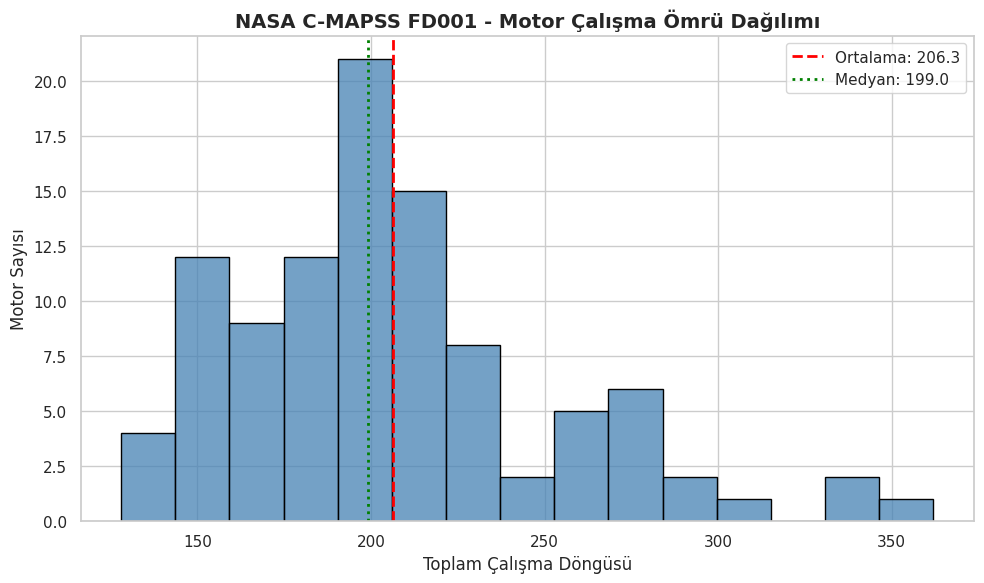

In [48]:


# GRAFİK 1: MOTORLARIN ÇALIŞMA ÖMRÜ DAĞILIMI


import matplotlib.pyplot as plt
import seaborn as sns

# 1. Her motorun son çalışma döngüsünü hesaplama
motor_omurleri = egitim_verisi.groupby("unit")["cycle"].max()

# 2. Temel istatistikleri hesaplama
print("MOTOR ÇALIŞMA ÖMRÜ İSTATİSTİKLERİ")
print("-" * 45)

print("Motor sayısı:", len(motor_omurleri))
print("Minimum ömür:", motor_omurleri.min(), "döngü")
print("Maksimum ömür:", motor_omurleri.max(), "döngü")
print("Ortalama ömür:", round(motor_omurleri.mean(), 2), "döngü")
print("Medyan ömür:", motor_omurleri.median(), "döngü")

# 3. Grafik görünümünü ayarlama
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

# 4. Motor ömürlerinin histogramını çizme
sns.histplot(
    motor_omurleri,
    bins=15,
    color="steelblue",
    edgecolor="black"
)

# 5. Ortalama ve medyan çizgilerini ekleme
plt.axvline(
    motor_omurleri.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Ortalama: {motor_omurleri.mean():.1f}"
)

plt.axvline(
    motor_omurleri.median(),
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"Medyan: {motor_omurleri.median():.1f}"
)

# 6. Grafik başlıkları ve eksenler
plt.title(
    "NASA C-MAPSS FD001 - Motor Çalışma Ömrü Dağılımı",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Toplam Çalışma Döngüsü")
plt.ylabel("Motor Sayısı")

plt.legend()
plt.tight_layout()

# 7. Grafiği görüntüleme
plt.show()



### 3.4. Grafik 1'in Yorumlanması: Motor Çalışma Ömrü Dağılımı

NASA C-MAPSS FD001 veri setindeki 100 eğitim motorunun çalışma ömürleri incelendiğinde, motorların **128 ile 362 çalışma döngüsü** arasında arızaya ulaştığı belirlenmiştir. Ortalama çalışma ömrü **206,31 döngü**, medyan çalışma ömrü ise **199 döngü** olarak hesaplanmıştır.

Histogram incelendiğinde motorların önemli bir bölümünün yaklaşık **180–220 çalışma döngüsü** aralığında yoğunlaştığı görülmektedir. Ortalama değerin medyandan yüksek olması ve dağılımın daha uzun çalışma ömürlerine doğru uzanması, sağa çarpık bir dağılıma işaret etmektedir.

Motorlar arasındaki çalışma ömrü farklılıkları, kalan faydalı ömür (RUL) tahmininin her motor için aynı sabit değerle gerçekleştirilemeyeceğini göstermektedir. Bu nedenle sensör ölçümleri ve motorların zamana bağlı davranışlarının değerlendirilmesi önem taşımaktadır.

**Sonuç:** Motor çalışma ömürlerinin geniş bir aralıkta değişmesi, RUL tahmininde motorların bireysel çalışma özelliklerini dikkate alan veri temelli modellerin kullanılmasını desteklemektedir.



### 3.5. Sensör Ölçümlerinin Zamana Bağlı Değişimi (Grafik 2)

Turbofan motorlarının kalan faydalı ömrünün tahmin edilmesinde, sensör ölçümlerinin çalışma döngüleri boyunca gösterdiği değişimlerin incelenmesi önem taşımaktadır.

Bu analizde, NASA C-MAPSS FD001 veri setindeki örnek bir motorun sensör ölçümleri zamana bağlı olarak görselleştirilecektir.

İlk veri incelemesinde değişkenlik gösterdiği belirlenen **sensor_2, sensor_4, sensor_11 ve sensor_12** değişkenleri seçilmiştir.

Farklı sensörlerin ölçüm ölçekleri birbirinden farklı olduğundan, her sensör ayrı bir alt grafikte gösterilecektir.

**Analizin amacı:**

1. Sensör ölçümlerinin çalışma döngüleri boyunca nasıl değiştiğini incelemek.
2. Sensörlerde artış, azalış veya dalgalanma eğilimlerini gözlemlemek.
3. Zamansal değişimlerin motorun bozulma süreciyle olası ilişkisini değerlendirmek.
4. Zaman serisi tabanlı LSTM modelinin kullanılmasına yönelik ön bulgular elde etmek.

Bu aşamada gözlemlenen eğilimler, nedensel ilişki veya tahmin başarısı kanıtı olarak değil, keşifsel analiz bulguları olarak değerlendirilecektir.


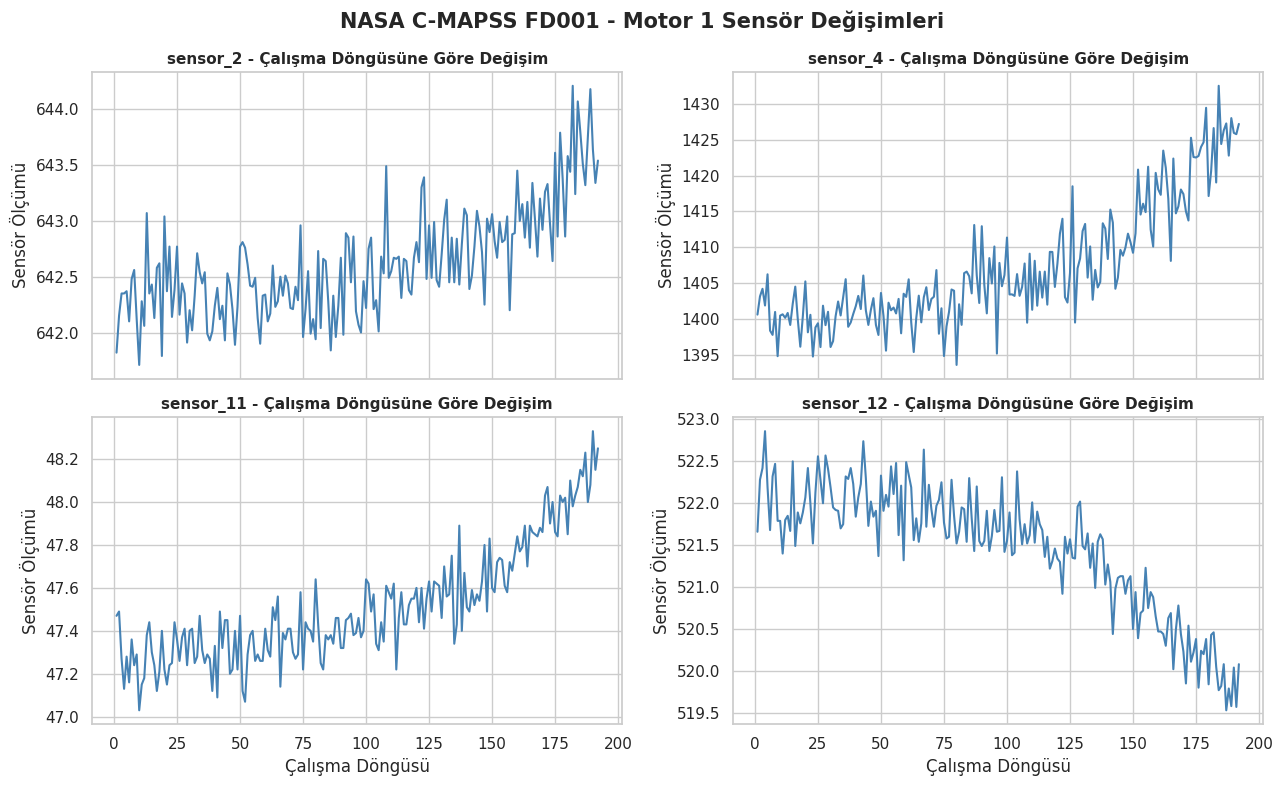

SENSÖR ANALİZİ
---------------------------------------------
İncelenen motor: 1
Toplam gözlemlenen döngü: 192
İncelenen sensörler: sensor_2, sensor_4, sensor_11, sensor_12


In [49]:


# GRAFİK 2: SENSÖRLERİN ZAMANA BAĞLI DEĞİŞİMİ


import matplotlib.pyplot as plt
import seaborn as sns

# 1. İncelenecek motoru seçme
motor_id = 1

motor_verisi = egitim_verisi[
    egitim_verisi["unit"] == motor_id
].sort_values("cycle")

# 2. İncelenecek sensörleri belirleme
secilen_sensorler = [
    "sensor_2",
    "sensor_4",
    "sensor_11",
    "sensor_12"
]

# 3. Grafik alanını oluşturma
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 8),
    sharex=True
)

axes = axes.flatten()

# 4. Her sensörün zamana bağlı ölçümlerini çizme
for i, sensor in enumerate(secilen_sensorler):

    sns.lineplot(
        data=motor_verisi,
        x="cycle",
        y=sensor,
        ax=axes[i],
        color="steelblue",
        linewidth=1.5
    )

    axes[i].set_title(
        f"{sensor} - Çalışma Döngüsüne Göre Değişim",
        fontsize=11,
        fontweight="bold"
    )

    axes[i].set_xlabel("Çalışma Döngüsü")
    axes[i].set_ylabel("Sensör Ölçümü")

# 5. Genel grafik başlığı
fig.suptitle(
    f"NASA C-MAPSS FD001 - Motor {motor_id} Sensör Değişimleri",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# 6. Seçilen motorun çalışma ömrünü gösterme
print("SENSÖR ANALİZİ")
print("-" * 45)

print("İncelenen motor:", motor_id)
print("Toplam gözlemlenen döngü:", motor_verisi["cycle"].max())
print("İncelenen sensörler:", ", ".join(secilen_sensorler))



### 3.6. Grafik 2'nin Yorumlanması: Sensörlerin Zamana Bağlı Değişimi

NASA C-MAPSS FD001 veri setindeki **Motor 1'in 192 çalışma döngüsü** boyunca kaydedilen sensor_2, sensor_4, sensor_11 ve sensor_12 ölçümleri incelenmiştir.

Grafikler değerlendirildiğinde, **sensor_2, sensor_4 ve sensor_11** değişkenlerinin çalışma döngüleri ilerledikçe genel olarak artış eğilimi gösterdiği belirlenmiştir. Buna karşılık **sensor_12** değişkeninde azalış eğilimi gözlemlenmiştir.

Özellikle motorun çalışma ömrünün son bölümünde sensör ölçümlerindeki değişimlerin daha belirgin hâle geldiği görülmektedir. Bu durum, sensörlerin zamana bağlı davranışlarının motorun bozulma süreci hakkında bilgi taşıyabileceğini düşündürmektedir.

**Modelleme açısından değerlendirme:** Sensör ölçümlerinde zamansal eğilimlerin bulunması, geçmiş çalışma döngülerindeki ölçümleri birlikte değerlendirebilen LSTM gibi zaman serisi tabanlı derin öğrenme modellerinin kullanılmasını gerekçelendirmektedir.

**Analizin sınırlılığı:** Bu görselleştirme yalnızca Motor 1'e ait olduğundan gözlemlenen eğilimlerin tüm motorlar için geçerli olduğu varsayılamaz. Modellerin gerçek tahmin başarısı, ayrılmış test verisi üzerinde hesaplanacak değerlendirme metrikleriyle belirlenecektir.



### 3.7. Sensörler Arası Korelasyon Analizi (Grafik 3)

NASA C-MAPSS FD001 veri setindeki sensör ölçümleri arasındaki doğrusal ilişkilerin incelenmesi amacıyla Pearson korelasyon analizi gerçekleştirilecektir.

Pearson korelasyon katsayısı, iki sayısal değişken arasındaki doğrusal ilişkinin yönünü ve gücünü gösterir. Katsayı -1 ile +1 arasında değer alır.

- **+1'e yakın değerler:** Güçlü pozitif doğrusal ilişki.
- **-1'e yakın değerler:** Güçlü negatif doğrusal ilişki.
- **0'a yakın değerler:** Zayıf veya bulunmayan doğrusal ilişki.

Önceki istatistiksel analizde bazı sensörlerin sabit değerler ürettiği gözlemlenmiştir. Sabit değişkenlerin standart sapması sıfır olduğundan Pearson korelasyon katsayıları tanımsızdır. Bu nedenle korelasyon matrisi oluşturulurken yalnızca değişkenlik gösteren sensörler kullanılacaktır.

Korelasyon matrisi, sensörler arasındaki ilişkilerin görsel olarak değerlendirilmesine ve sonraki özellik seçimi aşamasına yönelik ön bulgular elde edilmesine yardımcı olacaktır.

**Analizin amacı:** Sensörler arasındaki güçlü pozitif ve negatif doğrusal ilişkileri belirlemek, olası bilgi tekrarlarını değerlendirmek ve veri ön işleme aşamasında kullanılabilecek bulgular elde etmektir.


SENSÖR DEĞİŞKENLİK ANALİZİ
--------------------------------------------------
Toplam sensör sayısı: 21
Sabit sensör sayısı: 6
Değişken sensör sayısı: 15

Sabit sensörler:
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


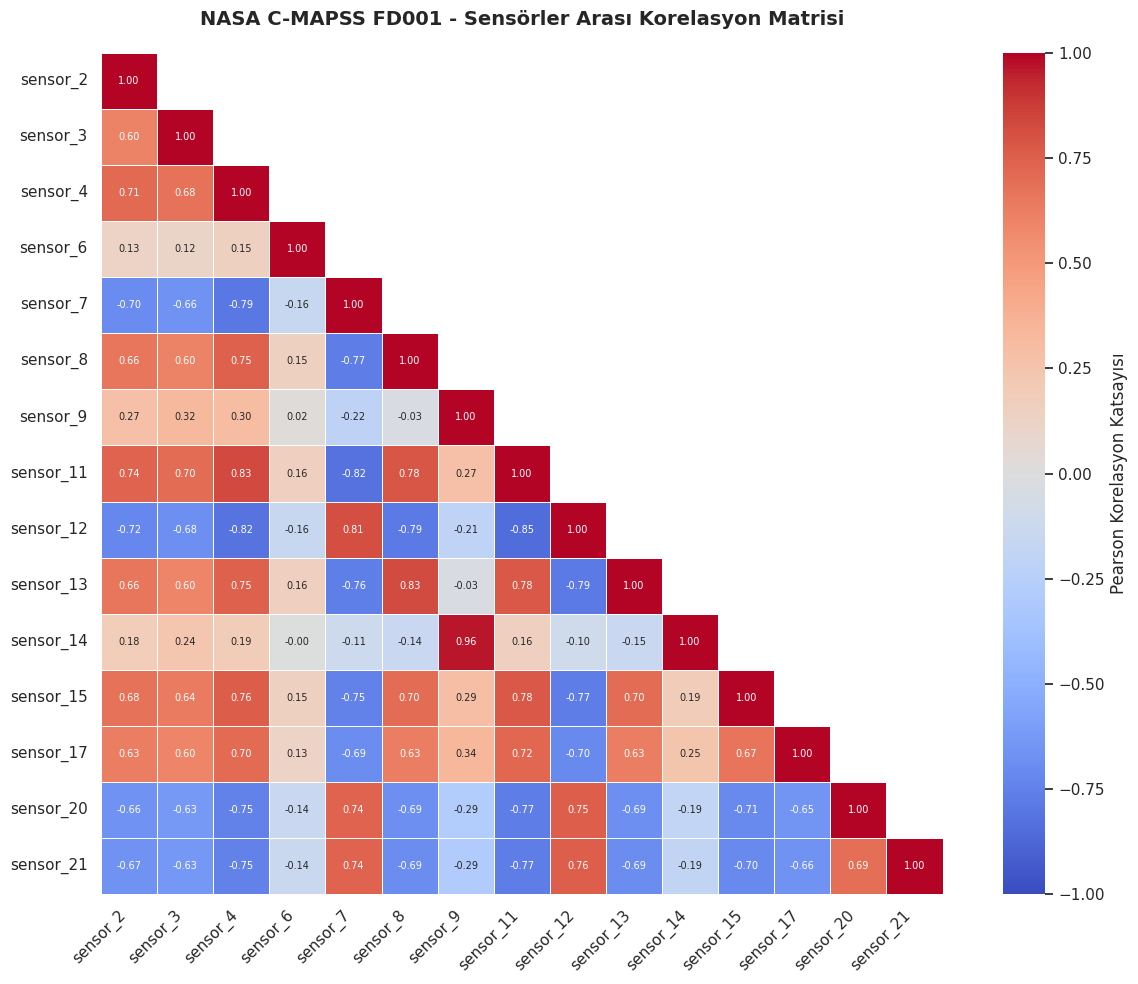


EN GÜÇLÜ 10 SENSÖR İLİŞKİSİ
--------------------------------------------------


,Sensör 1,Sensör 2,Korelasyon,Mutlak Korelasyon
72,sensor_9,sensor_14,0.963,0.963
77,sensor_11,sensor_12,-0.847,0.847
31,sensor_4,sensor_11,0.830,0.830
63,sensor_8,sensor_13,0.826,0.826
52,sensor_7,sensor_11,-0.823,0.823
32,sensor_4,sensor_12,-0.816,0.816
53,sensor_7,sensor_12,0.813,0.813
28,sensor_4,sensor_7,-0.793,0.793
84,sensor_12,sensor_13,-0.788,0.788
62,sensor_8,sensor_12,-0.787,0.787


In [50]:


# GRAFİK 3: SENSÖRLER ARASI KORELASYON MATRİSİ


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Sensör sütunlarını belirleme
sensor_sutunlari = [
    f"sensor_{i}" for i in range(1, 22)
]

# 2. Sabit ve değişken sensörleri ayırma
# nunique() kullanarak gerçek farklı değer sayısını kontrol ediyoruz.
sabit_sensorler = [
    sensor for sensor in sensor_sutunlari
    if egitim_verisi[sensor].nunique() <= 1
]

degisken_sensorler = [
    sensor for sensor in sensor_sutunlari
    if egitim_verisi[sensor].nunique() > 1
]

print("SENSÖR DEĞİŞKENLİK ANALİZİ")
print("-" * 50)

print("Toplam sensör sayısı:", len(sensor_sutunlari))
print("Sabit sensör sayısı:", len(sabit_sensorler))
print("Değişken sensör sayısı:", len(degisken_sensorler))

print("\nSabit sensörler:")
print(sabit_sensorler)

# 3. Pearson korelasyon matrisini hesaplama
korelasyon_matrisi = egitim_verisi[
    degisken_sensorler
].corr(method="pearson")

# 4. Korelasyon grafiğini oluşturma
sns.set_theme(style="white")

plt.figure(figsize=(13, 10))

# Matrisin üst üçgenini gizleme
maske = np.triu(
    np.ones_like(korelasyon_matrisi, dtype=bool),
    k=1
)

sns.heatmap(
    korelasyon_matrisi,
    mask=maske,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Korelasyon Katsayısı"},
    annot_kws={"size": 7}
)

plt.title(
    "NASA C-MAPSS FD001 - Sensörler Arası Korelasyon Matrisi",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# 5. En güçlü sensör ilişkilerini listeleme
# Aynı sensörün kendisiyle korelasyonunu ve tekrarları çıkarıyoruz.
ust_ucgen = np.triu(
    np.ones(korelasyon_matrisi.shape, dtype=bool),
    k=1
)

korelasyon_ciftleri = (
    korelasyon_matrisi
    .where(ust_ucgen)
    .stack()
    .reset_index()
)

korelasyon_ciftleri.columns = [
    "Sensör 1",
    "Sensör 2",
    "Korelasyon"
]

korelasyon_ciftleri["Mutlak Korelasyon"] = (
    korelasyon_ciftleri["Korelasyon"].abs()
)

en_guclu_iliskiler = (
    korelasyon_ciftleri
    .sort_values("Mutlak Korelasyon", ascending=False)
    .head(10)
)

print("\nEN GÜÇLÜ 10 SENSÖR İLİŞKİSİ")
print("-" * 50)

display(en_guclu_iliskiler.round(3))



### 3.8. Grafik 3'ün Yorumlanması: Sensörler Arası Korelasyon Analizi

NASA C-MAPSS FD001 veri setindeki 21 sensörün değişkenlik analizi sonucunda **6 sensörün sabit**, **15 sensörün ise değişken** olduğu belirlenmiştir. Sabit sensörler korelasyon hesaplamasından çıkarılmış ve değişken sensörler arasında Pearson korelasyon matrisi oluşturulmuştur.

Korelasyon analizi sonucunda en güçlü pozitif doğrusal ilişki **sensor_9 ile sensor_14 arasında (r = 0,963)** gözlemlenmiştir. Ayrıca sensor_4 ile sensor_11 arasında (r = 0,830) ve sensor_8 ile sensor_13 arasında (r = 0,826) güçlü pozitif ilişkiler belirlenmiştir.

Negatif ilişkiler incelendiğinde **sensor_11 ile sensor_12 arasında (r = -0,847)** ve sensor_7 ile sensor_11 arasında (r = -0,823) güçlü negatif korelasyonlar bulunduğu görülmüştür.

Bu bulgular, bazı sensörlerin benzer veya ters yönlü değişim örüntülerine sahip olduğunu göstermektedir. Bununla birlikte yüksek korelasyon, sensörlerin tamamen aynı bilgiyi taşıdığını veya RUL tahmini açısından gereksiz olduğunu tek başına kanıtlamamaktadır.

**Modelleme açısından değerlendirme:** Sabit sensörlerin tahmin modellerine katkı sağlaması beklenmediğinden veri ön işleme aşamasında özellik kümesinden çıkarılması planlanmaktadır. Yüksek korelasyon gösteren sensörler ise tahmin performansları değerlendirilmeden otomatik olarak elenmeyecektir.

**Sonuç:** Korelasyon analizi, sensörler arasındaki doğrusal ilişkilerin anlaşılmasını sağlamış ve sonraki özellik seçimi aşaması için temel oluşturmuştur.



## 4. Veri Ön İşleme

### 4.1. RUL Hedef Değişkeninin Oluşturulması

NASA C-MAPSS FD001 veri setinde eğitim motorlarının arızaya kadar olan çalışma kayıtları bulunmaktadır. Ancak kalan faydalı ömür (Remaining Useful Life - RUL) değerleri eğitim dosyasında doğrudan bir sütun olarak verilmemektedir.

Bu nedenle her motorun maksimum çalışma döngüsü belirlenerek mevcut çalışma döngüsünden çıkarılacak ve her gözlem için RUL hedef değişkeni oluşturulacaktır.

**RUL hesaplama formülü:**

$$
RUL_i(t) = T_i - t
$$

Burada:

- $RUL_i(t)$: $i$ motorunun $t$ döngüsündeki kalan faydalı ömrü.
- $T_i$: İlgili motorun arızaya ulaştığı son çalışma döngüsü.
- $t$: Motorun mevcut çalışma döngüsü.

Modelleme aşamasında **125 döngülük üst sınır (RUL clipping)** uygulanacaktır. Böylece 125 döngünün üzerindeki hedef değerler 125 olarak sınırlandırılacaktır.

Bu yaklaşım, motorun erken yaşam evresindeki yüksek RUL değerlerinin model eğitimine etkisini azaltmak amacıyla tercih edilmektedir. Üst sınırın bir modelleme varsayımı olduğu ve sonuçların yorumlanmasında dikkate alınması gerektiği unutulmamalıdır.

**Önemli:** Test verisindeki gerçek RUL değerleri ayrı bir dosyada bulunduğundan eğitim RUL etiketleri oluşturulurken test verisi kullanılmayacaktır.


In [51]:


# RUL HEDEF DEĞİŞKENİNİN OLUŞTURULMASI


# 1. Orijinal eğitim verisinin kopyasını oluşturma
egitim_rul = egitim_verisi.copy()

# 2. Her motorun arızaya ulaştığı son döngüyü hesaplama
son_donguler = egitim_rul.groupby("unit")["cycle"].transform("max")

# 3. Gerçek RUL değerlerini oluşturma
egitim_rul["RUL_original"] = (
    son_donguler - egitim_rul["cycle"]
)

# 4. RUL üst sınırını belirleme
RUL_UST_SINIR = 125

# 5. RUL değerlerini üst sınırla kırpma
egitim_rul["RUL"] = egitim_rul["RUL_original"].clip(
    upper=RUL_UST_SINIR
)

# 6. RUL değerlerinin kontrol edilmesi
print("RUL HEDEF DEĞİŞKENİ ANALİZİ")
print("-" * 50)

print("Toplam gözlem:", len(egitim_rul))
print("Minimum orijinal RUL:", egitim_rul["RUL_original"].min())
print("Maksimum orijinal RUL:", egitim_rul["RUL_original"].max())
print("Minimum kırpılmış RUL:", egitim_rul["RUL"].min())
print("Maksimum kırpılmış RUL:", egitim_rul["RUL"].max())

print("\nRUL ÜST SINIR KONTROLÜ")
print("-" * 50)

print(
    "125 döngünün üzerinde olan gözlem sayısı:",
    (egitim_rul["RUL_original"] > RUL_UST_SINIR).sum()
)

# 7. Motor 1'in ilk ve son gözlemlerini inceleme
motor_1 = egitim_rul[
    egitim_rul["unit"] == 1
]

print("\nMOTOR 1 - İLK 5 GÖZLEM")
display(
    motor_1[["unit", "cycle", "RUL_original", "RUL"]].head()
)

print("\nMOTOR 1 - SON 5 GÖZLEM")
display(
    motor_1[["unit", "cycle", "RUL_original", "RUL"]].tail()
)

# 8. Hesaplamanın doğruluğunu kontrol etme
assert (egitim_rul["RUL_original"] >= 0).all()
assert (egitim_rul["RUL"] <= RUL_UST_SINIR).all()

print("\nRUL hesaplama kontrolleri başarılı.")


RUL HEDEF DEĞİŞKENİ ANALİZİ
--------------------------------------------------
Toplam gözlem: 20631
Minimum orijinal RUL: 0
Maksimum orijinal RUL: 361
Minimum kırpılmış RUL: 0
Maksimum kırpılmış RUL: 125

RUL ÜST SINIR KONTROLÜ
--------------------------------------------------
125 döngünün üzerinde olan gözlem sayısı: 8031

MOTOR 1 - İLK 5 GÖZLEM


,unit,cycle,RUL_original,RUL
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125



MOTOR 1 - SON 5 GÖZLEM


,unit,cycle,RUL_original,RUL
187,1,188,4,4
188,1,189,3,3
189,1,190,2,2
190,1,191,1,1
191,1,192,0,0



RUL hesaplama kontrolleri başarılı.



### 4.2. RUL Hedef Değişkeninin Oluşturulmasına İlişkin Bulgular

Eğitim veri setindeki **20.631 gözlem** için kalan faydalı ömür (RUL) değerleri, her motorun son çalışma döngüsünden mevcut döngünün çıkarılmasıyla hesaplanmıştır.

Analiz sonucunda orijinal RUL değerlerinin **0 ile 361 döngü** arasında değiştiği belirlenmiştir. Modelleme amacıyla uygulanan **125 döngülük üst sınır** sonucunda hedef değişkenin değer aralığı 0–125 olarak sınırlandırılmıştır.

Toplam **8.031 gözlemin** orijinal RUL değerinin 125'in üzerinde olduğu ve bu gözlemlere kırpma işlemi uygulandığı görülmüştür. Bu sayı, eğitim gözlemlerinin yaklaşık **%38,9'una** karşılık gelmektedir.

Örnek olarak incelenen Motor 1'in ilk çalışma döngüsündeki orijinal RUL değeri 191 iken kırpılmış RUL değeri 125 olarak hesaplanmıştır. Motorun son çalışma döngüsünde ise RUL değeri sıfıra ulaşmıştır.

**Modelleme açısından değerlendirme:** RUL kırpma işlemi, motorların erken yaşam evresindeki yüksek hedef değerlerinin etkisini sınırlandırmak amacıyla uygulanmıştır. Bununla birlikte bu işlem yüksek RUL değerleri arasındaki farklılıkları ortadan kaldırdığından, modelin uzun kalan ömürleri tahmin etme kapasitesini sınırlayabilir.

**Değerlendirme yaklaşımı:** Model eğitiminde kırpılmış RUL hedefleri kullanılacak, nihai test performansı ise gerçek ve kırpılmamış RUL değerleri üzerinden değerlendirilecektir. Böylece kırpma tercihinin olası etkileri hata analizinde incelenebilecektir.



### 4.3. Sabit Sensörlerin Elenmesi ve Özellik Seçimi

Makine öğrenmesi ve derin öğrenme modellerinin eğitimi öncesinde, veri setindeki değişkenlerin tahmin problemine uygunluğu değerlendirilmektedir.

Veri keşfi aşamasında gerçekleştirilen değişkenlik analizi sonucunda, 21 sensörden 6'sının tüm eğitim gözlemlerinde sabit değerler ürettiği belirlenmiştir. Bu sensörler **sensor_1, sensor_5, sensor_10, sensor_16, sensor_18 ve sensor_19** değişkenleridir.

Sabit sensörler gözlemler arasında farklılık göstermediğinden, motorların kalan faydalı ömrünün tahmin edilmesinde ayırt edici bilgi sağlamamaktadır. Bu nedenle söz konusu değişkenler model girdilerinden çıkarılacaktır.

**Özellik seçiminde izlenen yaklaşım:**

1. Sabit sensörler eğitim verisi üzerinden belirlenerek özellik kümesinden çıkarılacaktır.
2. Değişkenlik gösteren 15 sensör model girdileri arasında tutulacaktır.
3. Üç operasyonel parametre ve çalışma döngüsü bilgisi korunacaktır.
4. Motor kimliği (`unit`), motor bazlı veri bölme ve sıralama işlemleri için kullanılacaktır.
5. `RUL` hedef değişken olarak ayrılacak; `RUL_original` ise kontrol ve analiz amacıyla saklanacaktır.

Bu aşamada yüksek korelasyon gösteren sensörler otomatik olarak elenmeyecektir. Böylece sensörler arasındaki ilişkilerin model performansına olası katkıları korunacaktır.

**Amaç:** Gereksiz sabit değişkenleri kaldırarak modeller için daha uygun, izlenebilir ve tutarlı bir özellik kümesi oluşturmaktır.


In [52]:


# SABİT SENSÖRLERİN ELENMESİ VE ÖZELLİK SEÇİMİ


# 1. Eğitim verisindeki sabit sensörleri belirleme
sensor_sutunlari = [
    f"sensor_{i}" for i in range(1, 22)
]

sabit_sensorler = [
    sensor for sensor in sensor_sutunlari
    if egitim_rul[sensor].nunique() == 1
]

# 2. Değişkenlik gösteren sensörleri belirleme
secilen_sensorler = [
    sensor for sensor in sensor_sutunlari
    if sensor not in sabit_sensorler
]

# 3. Operasyonel parametreleri tanımlama
operasyonel_parametreler = [
    "setting_1",
    "setting_2",
    "setting_3"
]

# 4. Modelde kullanılacak özellikleri oluşturma
ozellik_sutunlari = (
    ["cycle"]
    + operasyonel_parametreler
    + secilen_sensorler
)

# 5. Orijinal verileri değiştirmeden yeni veri kümeleri oluşturma
egitim_secili = egitim_rul[
    ["unit"] + ozellik_sutunlari + ["RUL_original", "RUL"]
].copy()

test_secili = test_verisi[
    ["unit"] + ozellik_sutunlari
].copy()

# 6. Özellik seçimi sonuçlarını görüntüleme
print("ÖZELLİK SEÇİMİ SONUÇLARI")
print("-" * 50)

print("Başlangıçtaki sensör sayısı:", len(sensor_sutunlari))
print("Elenen sabit sensör sayısı:", len(sabit_sensorler))
print("Kalan sensör sayısı:", len(secilen_sensorler))

print("\nElenen sabit sensörler:")
print(sabit_sensorler)

print("\nMODEL GİRDİLERİ")
print("-" * 50)

print("Çalışma döngüsü değişkeni: 1")
print("Operasyonel parametre sayısı:", len(operasyonel_parametreler))
print("Kullanılan sensör sayısı:", len(secilen_sensorler))
print("Toplam model özelliği:", len(ozellik_sutunlari))

print("\nYENİ VERİ BOYUTLARI")
print("-" * 50)

print("Eğitim verisi:", egitim_secili.shape)
print("Test verisi:", test_secili.shape)

# 7. Özelliklerin iki veri kümesinde de aynı olduğunu kontrol etme
assert all(
    sutun in egitim_secili.columns
    for sutun in ozellik_sutunlari
)

assert all(
    sutun in test_secili.columns
    for sutun in ozellik_sutunlari
)

assert len(ozellik_sutunlari) == len(set(ozellik_sutunlari))

print("\nÖzellik seçimi kontrolleri başarılı.")


ÖZELLİK SEÇİMİ SONUÇLARI
--------------------------------------------------
Başlangıçtaki sensör sayısı: 21
Elenen sabit sensör sayısı: 6
Kalan sensör sayısı: 15

Elenen sabit sensörler:
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

MODEL GİRDİLERİ
--------------------------------------------------
Çalışma döngüsü değişkeni: 1
Operasyonel parametre sayısı: 3
Kullanılan sensör sayısı: 15
Toplam model özelliği: 19

YENİ VERİ BOYUTLARI
--------------------------------------------------
Eğitim verisi: (20631, 22)
Test verisi: (13096, 20)

Özellik seçimi kontrolleri başarılı.



### 4.4. Özellik Seçimi Sonuçlarının Değerlendirilmesi

NASA C-MAPSS FD001 veri setinde gerçekleştirilen özellik seçimi sonucunda, başlangıçtaki **21 sensörden 6'sının sabit değerler içerdiği** doğrulanmış ve bu değişkenler model girdilerinden çıkarılmıştır.

Elenen sensörler **sensor_1, sensor_5, sensor_10, sensor_16, sensor_18 ve sensor_19** olarak belirlenmiştir. Bu sensörler, eğitim gözlemleri arasında değişkenlik göstermedikleri için ayırt edici bilgi sağlamamaktadır.

Özellik seçimi sonrasında **15 sensör ölçümü, 3 operasyonel parametre ve 1 çalışma döngüsü değişkeni** korunarak toplam **19 model girdisi** oluşturulmuştur.

Yeni eğitim veri kümesi **20.631 satır ve 22 sütundan**, test veri kümesi ise **13.096 satır ve 20 sütundan** oluşmaktadır. Eğitim verisinde model girdilerine ek olarak motor kimliği, orijinal RUL ve kırpılmış RUL sütunları bulunmaktadır.

**Modelleme açısından değerlendirme:** Sabit sensörlerin elenmesiyle bilgi taşımayan değişkenler kaldırılmış, diğer sensörler arasındaki olası ilişkiler korunmuştur. Motor kimliği model girdilerinden ayrılmış ve sonraki aşamada motor bazlı eğitim/doğrulama bölmesi oluşturulması için saklanmıştır.

**Sonuç:** Random Forest ve LSTM modellerinde kullanılmak üzere ortak bir özellik listesi oluşturulmuştur. Modellerin gereksinimlerine uygun ölçeklendirme ve zaman penceresi oluşturma işlemleri sonraki aşamalarda gerçekleştirilecektir.

**Sonraki aşama güncellemesi:** Ölçeklendirme öncesinde yapılan ek kontrolde `setting_3` operasyonel parametresinin de sabit olduğu belirlenmiş ve bu değişken model girdilerinden çıkarılmıştır. Böylece nihai model özelliği sayısı **19'dan 18'e düşürülmüştür**. İlk özellik seçimi aşamasındaki 19 özellik sonucu, yalnızca sabit sensörlerin elendiği ara aşamayı temsil etmektedir.



### 4.5. Motor Bazlı Eğitim ve Doğrulama Ayrımı

Makine öğrenmesi modellerinin güvenilir biçimde değerlendirilebilmesi için eğitim ve doğrulama verilerinin birbirinden bağımsız olması gerekmektedir.

NASA C-MAPSS FD001 veri setinde her motorun birden fazla çalışma döngüsüne ait sensör ölçümleri bulunmaktadır. Bu nedenle verilerin satır bazında rastgele bölünmesi, aynı motora ait ölçümlerin hem eğitim hem de doğrulama kümesinde yer almasına neden olabilir.

Bu durum, **veri sızıntısı (data leakage)** riski oluşturarak doğrulama performansının olduğundan daha yüksek görünmesine yol açabilir.

Bu riski azaltmak amacıyla veri bölme işlemi motor kimlikleri (`unit`) üzerinden gerçekleştirilecektir.

**Uygulanacak yöntem:**

1. Eğitim dosyasındaki 100 farklı motor belirlenecektir.
2. Motorların %80'i eğitim, %20'si doğrulama amacıyla ayrılacaktır.
3. Aynı motora ait tüm çalışma döngüleri yalnızca tek bir grupta bulunacaktır.
4. Tekrarlanabilirlik için `random_state=42` kullanılacaktır.
5. NASA tarafından sağlanan bağımsız test kümesi nihai değerlendirme aşamasına kadar ayrı tutulacaktır.

Bu yaklaşım, modellerin eğitim sırasında görmedikleri motorlar üzerindeki genelleme performansını daha güvenilir biçimde değerlendirmeyi amaçlamaktadır.

**Önemli:** Ölçeklendirme işlemi veri bölme işleminden sonra gerçekleştirilecek ve ölçeklendirici yalnızca eğitim grubundaki gözlemler üzerinde öğrenilecektir.


In [53]:


# MOTOR BAZLI EĞİTİM VE DOĞRULAMA AYRIMI


import numpy as np
from sklearn.model_selection import train_test_split

# 1. Eğitim verisindeki benzersiz motorları belirleme
motor_kimlikleri = np.sort(
    egitim_secili["unit"].unique()
)

# 2. Motorları eğitim ve doğrulama gruplarına ayırma
egitim_motorlari, dogrulama_motorlari = train_test_split(
    motor_kimlikleri,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

# 3. Motor kimliklerine göre veri kümelerini oluşturma
train_df = egitim_secili[
    egitim_secili["unit"].isin(egitim_motorlari)
].copy()

val_df = egitim_secili[
    egitim_secili["unit"].isin(dogrulama_motorlari)
].copy()

# 4. Verileri motor ve çalışma döngüsüne göre sıralama
train_df = train_df.sort_values(
    ["unit", "cycle"]
).reset_index(drop=True)

val_df = val_df.sort_values(
    ["unit", "cycle"]
).reset_index(drop=True)

# 5. Motor ve gözlem sayılarını görüntüleme
print("MOTOR BAZLI VERİ AYRIMI")
print("-" * 50)

print("Toplam motor sayısı:", len(motor_kimlikleri))
print("Eğitim motoru sayısı:", len(egitim_motorlari))
print("Doğrulama motoru sayısı:", len(dogrulama_motorlari))

print("\nVERİ KÜMESİ BOYUTLARI")
print("-" * 50)

print("Eğitim verisi:", train_df.shape)
print("Doğrulama verisi:", val_df.shape)

# 6. Motorların iki grupta ortak olup olmadığını kontrol etme
ortak_motorlar = set(egitim_motorlari).intersection(
    set(dogrulama_motorlari)
)

print("\nVERİ SIZINTISI KONTROLÜ")
print("-" * 50)

print("Ortak motor sayısı:", len(ortak_motorlar))

# 7. Doğrulama kontrolleri
assert len(egitim_motorlari) == 80
assert len(dogrulama_motorlari) == 20
assert len(ortak_motorlar) == 0

assert len(train_df) + len(val_df) == len(egitim_secili)

assert set(train_df["unit"]).isdisjoint(
    set(val_df["unit"])
)

print("\nMotor bazlı veri ayrımı kontrolleri başarılı.")


MOTOR BAZLI VERİ AYRIMI
--------------------------------------------------
Toplam motor sayısı: 100
Eğitim motoru sayısı: 80
Doğrulama motoru sayısı: 20

VERİ KÜMESİ BOYUTLARI
--------------------------------------------------
Eğitim verisi: (16561, 22)
Doğrulama verisi: (4070, 22)

VERİ SIZINTISI KONTROLÜ
--------------------------------------------------
Ortak motor sayısı: 0

Motor bazlı veri ayrımı kontrolleri başarılı.



### 4.6. Motor Bazlı Veri Ayrımının Sonuçları

NASA C-MAPSS FD001 eğitim veri setindeki **100 motor**, motor kimlikleri temel alınarak %80 eğitim ve %20 doğrulama gruplarına ayrılmıştır.

Bu işlem sonucunda eğitim kümesinde **80 motora ait 16.561 gözlem**, doğrulama kümesinde ise **20 motora ait 4.070 gözlem** bulunmaktadır. Her iki kümenin toplamı, başlangıçtaki 20.631 eğitim gözlemiyle tutarlıdır.

Veri sızıntısı kontrolünde eğitim ve doğrulama kümeleri arasında **ortak motor sayısının sıfır olduğu** doğrulanmıştır. Böylece aynı motora ait farklı çalışma döngülerinin iki gruba dağılması engellenmiştir.

**Yöntemsel değerlendirme:** Motor bazlı veri ayrımı, modellerin eğitim sırasında görmediği motorlar üzerindeki tahmin performansını değerlendirmek için tercih edilmiştir. Bu yaklaşım, satır bazlı rastgele bölmeye kıyasla aynı motora ait gözlemlerden kaynaklanabilecek veri sızıntısı riskini azaltmaktadır.

**Sonuç:** Eğitim ve doğrulama kümeleri motor kimliği bakımından birbirinden ayrılmıştır. NASA tarafından sağlanan bağımsız test kümesi ise nihai model değerlendirmesi için korunmaktadır.



### 4.7. StandardScaler ile Özelliklerin Ölçeklendirilmesi

NASA C-MAPSS FD001 veri setindeki sensör ölçümleri ve operasyonel parametreler farklı sayısal aralıklarda bulunmaktadır. Bu farklılıkların özellikle derin öğrenme modelinin eğitim sürecini etkilemesini azaltmak amacıyla StandardScaler yöntemi kullanılacaktır.

StandardScaler, özellikleri eğitim verisinin ortalaması ve standart sapması üzerinden standartlaştırmaktadır.

**Standartlaştırma formülü:**

$$
z = \frac{x-\mu}{\sigma}
$$

Burada $x$ orijinal özellik değerini, $\mu$ eğitim verisinin ortalamasını ve $\sigma$ eğitim verisinin standart sapmasını göstermektedir.

**Uygulama yaklaşımı:**

1. Önceden belirlenen 19 model özelliği kullanılacaktır.
2. StandardScaler yalnızca eğitim motorlarına ait veriler üzerinde eğitilecektir.
3. Doğrulama ve test verilerine aynı ölçeklendirme dönüşümü uygulanacaktır.
4. Motor kimliği ve RUL hedef değişkenleri ölçeklendirilmeyecektir.
5. Orijinal veri kümeleri korunarak ölçeklendirilmiş yeni veri kümeleri oluşturulacaktır.

Bu yaklaşım, doğrulama ve test verilerinin istatistiksel bilgilerinin model hazırlama sürecine sızmasını önlemek açısından önemlidir.

**Amaç:** Özelliklerin karşılaştırılabilir sayısal ölçeklere dönüştürülmesi ve özellikle LSTM modelinin eğitimine uygun girdilerin hazırlanmasıdır.


In [54]:


# VERİLERİN ÖLÇEKLENDİRİLMESİ


import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. EĞİTİM VERİSİNDEKİ SABİT ÖZELLİKLERİ BELİRLEME

sabit_ozellikler = [
    sutun for sutun in ozellik_sutunlari
    if train_df[sutun].nunique() == 1
]

print("SABİT ÖZELLİK KONTROLÜ")
print("-" * 50)

print("Elenen sabit özellik sayısı:", len(sabit_ozellikler))
print("Elenen sabit özellikler:", sabit_ozellikler)


# 2. MODELDE KULLANILACAK ÖZELLİKLERİ GÜNCELLEME


ozellik_sutunlari = [
    sutun for sutun in ozellik_sutunlari
    if sutun not in sabit_ozellikler
]

print("\nGÜNCELLENMİŞ MODEL ÖZELLİKLERİ")
print("-" * 50)

print("Kalan özellik sayısı:", len(ozellik_sutunlari))
print("Kullanılan özellikler:", ozellik_sutunlari)


# 3. STANDARDSCALER OLUŞTURMA


scaler = StandardScaler()



# 4. ORİJİNAL VERİLERİ KORUYARAK KOPYALAMA

train_scaled = train_df.copy()
val_scaled = val_df.copy()
test_scaled = test_secili.copy()



# 5. ÖLÇEKLENDİRİCİYİ YALNIZCA EĞİTİM VERİSİNDE EĞİTME


train_scaled[ozellik_sutunlari] = scaler.fit_transform(
    train_df[ozellik_sutunlari]
)


# 6. DOĞRULAMA VERİSİNİ ÖLÇEKLENDİRME


val_scaled[ozellik_sutunlari] = scaler.transform(
    val_df[ozellik_sutunlari]
)


# 7. TEST VERİSİNİ ÖLÇEKLENDİRME


test_scaled[ozellik_sutunlari] = scaler.transform(
    test_secili[ozellik_sutunlari]
)


# 8. SABİT ÖZELLİKLERİ YENİ VERİ KÜMELERİNDEN ÇIKARMA


train_scaled = train_scaled.drop(
    columns=sabit_ozellikler
)

val_scaled = val_scaled.drop(
    columns=sabit_ozellikler
)

test_scaled = test_scaled.drop(
    columns=sabit_ozellikler
)


# 9. VERİ BOYUTLARINI GÖRÜNTÜLEME


print("\nÖLÇEKLENDİRME SONUÇLARI")
print("-" * 50)

print("Ölçeklendirilen özellik sayısı:", len(ozellik_sutunlari))
print("Eğitim verisi:", train_scaled.shape)
print("Doğrulama verisi:", val_scaled.shape)
print("Test verisi:", test_scaled.shape)


# 10. ORTALAMA VE STANDART SAPMA KONTROLÜ


ortalama_degerler = train_scaled[
    ozellik_sutunlari
].mean()

std_degerler = train_scaled[
    ozellik_sutunlari
].std(ddof=0)

print("\nEĞİTİM VERİSİ - ÖLÇEKLENDİRME KONTROLÜ")
print("-" * 50)

print(
    "En büyük mutlak ortalama:",
    round(ortalama_degerler.abs().max(), 8)
)

print(
    "Minimum standart sapma:",
    round(std_degerler.min(), 6)
)

print(
    "Maksimum standart sapma:",
    round(std_degerler.max(), 6)
)


# 11. İLK 5 GÖZLEMİ GÖRÜNTÜLEME

print("\nÖLÇEKLENDİRİLMİŞ İLK 5 GÖZLEM")

display(
    train_scaled[
        ["unit", "cycle", "sensor_2", "sensor_4", "RUL"]
    ].head()
)



# 12. DOĞRULAMA KONTROLLERİ


# Özellik sayısı kontrolü
assert len(scaler.mean_) == len(ozellik_sutunlari)

# Eğitim özelliklerinin ortalaması yaklaşık 0 olmalı
assert np.allclose(
    train_scaled[ozellik_sutunlari].mean(),
    0,
    atol=1e-8
)

# Eğitim özelliklerinin standart sapması yaklaşık 1 olmalı
assert np.allclose(
    train_scaled[ozellik_sutunlari].std(ddof=0),
    1,
    atol=1e-8
)

# Hedef değişkenler değişmemiş olmalı
assert train_scaled["RUL"].equals(train_df["RUL"])
assert val_scaled["RUL"].equals(val_df["RUL"])

# Motor kimlikleri korunmuş olmalı
assert train_scaled["unit"].equals(train_df["unit"])
assert val_scaled["unit"].equals(val_df["unit"])

# Veri satır sayıları korunmuş olmalı
assert len(train_scaled) == len(train_df)
assert len(val_scaled) == len(val_df)
assert len(test_scaled) == len(test_secili)

# Eğitim ve doğrulama motorları ortak olmamalı
assert set(train_scaled["unit"]).isdisjoint(
    set(val_scaled["unit"])
)

print("\nTüm ölçeklendirme kontrolleri başarılı.")


SABİT ÖZELLİK KONTROLÜ
--------------------------------------------------
Elenen sabit özellik sayısı: 1
Elenen sabit özellikler: ['setting_3']

GÜNCELLENMİŞ MODEL ÖZELLİKLERİ
--------------------------------------------------
Kalan özellik sayısı: 18
Kullanılan özellikler: ['cycle', 'setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

ÖLÇEKLENDİRME SONUÇLARI
--------------------------------------------------
Ölçeklendirilen özellik sayısı: 18
Eğitim verisi: (16561, 21)
Doğrulama verisi: (4070, 21)
Test verisi: (13096, 19)

EĞİTİM VERİSİ - ÖLÇEKLENDİRME KONTROLÜ
--------------------------------------------------
En büyük mutlak ortalama: 0.0
Minimum standart sapma: 1.0
Maksimum standart sapma: 1.0

ÖLÇEKLENDİRİLMİŞ İLK 5 GÖZLEM


,unit,cycle,sensor_2,sensor_4,RUL
0,2,-1.556308,-1.581191,-1.963014,125
1,2,-1.541948,-1.721722,-1.756664,125
2,2,-1.527588,-2.263772,-1.106382,125
3,2,-1.513228,-2.002785,-1.427619,125
4,2,-1.498868,-1.902406,-0.709298,125



Tüm ölçeklendirme kontrolleri başarılı.



### 4.8. Ölçeklendirme Sonuçlarının Değerlendirilmesi

StandardScaler uygulamasından önce eğitim verisindeki model özellikleri yeniden kontrol edilmiş ve **setting_3** operasyonel parametresinin sabit değer içerdiği belirlenmiştir.

Bu değişken, gözlemler arasında farklılık göstermediği için model girdilerinden çıkarılmıştır. Böylece daha önce seçilen 19 özellikten **18 özellik** kalmıştır.

Nihai model girdileri:

- **15 sensör ölçümü**
- **2 operasyonel parametre (setting_1 ve setting_2)**
- **1 çalışma döngüsü değişkeni (cycle)**

Ölçeklendirme işlemi sonucunda:

- Eğitim kümesi: **16.561 gözlem, 21 sütun**
- Doğrulama kümesi: **4.070 gözlem, 21 sütun**
- Test kümesi: **13.096 gözlem, 19 sütun**

StandardScaler yalnızca eğitim kümesi üzerinde eğitilmiş; doğrulama ve test kümeleri aynı ölçeklendirme parametreleri kullanılarak dönüştürülmüştür.

Ölçeklendirme sonrası eğitim özelliklerinin en büyük mutlak ortalaması **0,0**, minimum ve maksimum standart sapmaları ise **1,0** olarak hesaplanmıştır. Bu sonuçlar, eğitim özelliklerinin başarıyla standartlaştırıldığını göstermektedir.

Motor kimlikleri ve RUL hedef değerleri değiştirilmemiş, eğitim ve doğrulama kümelerinin motor bazlı ayrımı korunmuştur.

**Sonuç:** Veri kümeleri, 18 ortak model özelliğiyle ölçeklendirilmiş ve sonraki modelleme aşamaları için hazırlanmıştır. Bu yaklaşım, özellikle LSTM modelinin eğitiminde sayısal ölçek farklılıklarının etkisini azaltmayı ve doğrulama/test verilerinden kaynaklanabilecek bilgi sızıntısını önlemeyi amaçlamaktadır.



### 4.9. LSTM İçin Zaman Pencerelerinin Oluşturulması

LSTM (Long Short-Term Memory), ardışık gözlemler arasındaki zamansal ilişkileri öğrenebilen bir derin öğrenme mimarisidir.

NASA C-MAPSS FD001 veri setinde her motorun çalışma döngülerine ait sensör ölçümleri zaman sıralı bir yapı oluşturmaktadır. Bu nedenle LSTM modeline girdi sağlamak amacıyla **kayan pencere (sliding window)** yöntemi kullanılacaktır.

Bu çalışmada başlangıç pencere uzunluğu **30 çalışma döngüsü** olarak belirlenmiştir.

Her zaman penceresi:

- Aynı motora ait 30 ardışık çalışma döngüsünü,
- Her döngü için seçilen 18 model özelliğini,
- Pencerenin son döngüsüne karşılık gelen kırpılmış RUL hedefini

içerecektir.

Örneğin 1–30. döngülerden oluşan pencerenin hedef değeri 30. döngüdeki RUL, 2–31. döngülerden oluşan pencerenin hedef değeri ise 31. döngüdeki RUL olacaktır.

Pencereler motor bazında ve çalışma döngüsü sırasına göre oluşturulacaktır. Böylece farklı motorlara ait ölçümlerin aynı zaman penceresinde bulunması engellenecektir.

**Veri ayrımı:** Eğitim ve doğrulama pencereleri, önceden ayrılmış motor grupları kullanılarak ayrı ayrı oluşturulacaktır. Bağımsız test verisi nihai değerlendirme için korunacaktır.

**Amaç:** Motorun geçmiş sensör davranışlarından yararlanarak kalan faydalı ömür (RUL) tahmini yapabilecek LSTM modeline uygun üç boyutlu girdi verisi hazırlamaktır.


In [55]:


# LSTM İÇİN ZAMAN PENCERELERİNİN OLUŞTURULMASI


import numpy as np

# 1. Pencere uzunluğunu belirleme
PENCERE_UZUNLUGU = 30


# 2. Motor bazlı zaman penceresi oluşturma fonksiyonu
def zaman_pencereleri_olustur(
    veri,
    ozellikler,
    pencere_uzunlugu=30
):
    X_listesi = []
    y_listesi = []
    motor_listesi = []
    dongu_listesi = []

    # Her motoru ayrı ayrı ele alıyoruz.
    for motor_id, motor_verisi in veri.groupby("unit"):

        # Çalışma döngülerini kronolojik sıraya koyuyoruz.
        motor_verisi = motor_verisi.sort_values("cycle")

        X_motor = motor_verisi[ozellikler].to_numpy(
            dtype=np.float32
        )

        y_motor = motor_verisi["RUL"].to_numpy(
            dtype=np.float32
        )

        donguler = (
    motor_verisi["cycle"] * scaler.scale_[
        ozellik_sutunlari.index("cycle")
    ] + scaler.mean_[
        ozellik_sutunlari.index("cycle")
    ]
).round().astype(int).to_numpy()

        # Yeterli döngüsü olmayan motorlardan pencere üretilmez.
        if len(motor_verisi) < pencere_uzunlugu:
            continue

        # Kayan pencereleri oluşturuyoruz.
        for baslangic in range(
            len(motor_verisi) - pencere_uzunlugu + 1
        ):

            bitis = baslangic + pencere_uzunlugu

            X_pencere = X_motor[baslangic:bitis]

            # Hedef, pencerenin son döngüsündeki RUL'dur.
            y_hedef = y_motor[bitis - 1]

            X_listesi.append(X_pencere)
            y_listesi.append(y_hedef)

            motor_listesi.append(motor_id)
            dongu_listesi.append(donguler[bitis - 1])

    if not X_listesi:
        raise ValueError(
            "Pencere oluşturulamadı. "
            "Pencere uzunluğunu ve veri boyutlarını kontrol edin."
        )

    return (
        np.stack(X_listesi),
        np.array(y_listesi, dtype=np.float32),
        np.array(motor_listesi),
        np.array(dongu_listesi)
    )


# 3. Eğitim pencerelerini oluşturma
X_train_lstm, y_train_lstm, train_pencere_motorlari, train_pencere_donguleri = (
    zaman_pencereleri_olustur(
        train_scaled,
        ozellik_sutunlari,
        PENCERE_UZUNLUGU
    )
)


# 4. Doğrulama pencerelerini oluşturma
X_val_lstm, y_val_lstm, val_pencere_motorlari, val_pencere_donguleri = (
    zaman_pencereleri_olustur(
        val_scaled,
        ozellik_sutunlari,
        PENCERE_UZUNLUGU
    )
)


# 5. Oluşturulan veri boyutlarını görüntüleme
print("LSTM ZAMAN PENCERESİ SONUÇLARI")
print("-" * 50)

print("Pencere uzunluğu:", PENCERE_UZUNLUGU)
print("Özellik sayısı:", len(ozellik_sutunlari))

print("\nEĞİTİM VERİSİ")
print("-" * 50)

print("X_train_lstm boyutu:", X_train_lstm.shape)
print("y_train_lstm boyutu:", y_train_lstm.shape)

print("\nDOĞRULAMA VERİSİ")
print("-" * 50)

print("X_val_lstm boyutu:", X_val_lstm.shape)
print("y_val_lstm boyutu:", y_val_lstm.shape)


# 6. Örnek bir pencereyi inceleme
print("\nİLK EĞİTİM PENCERESİ")
print("-" * 50)

print("Motor:", train_pencere_motorlari[0])
print("Pencerenin son döngüsü:", train_pencere_donguleri[0])
print("Pencere boyutu:", X_train_lstm[0].shape)
print("Hedef RUL:", y_train_lstm[0])


# 7. Veri bütünlüğü kontrolleri
assert X_train_lstm.ndim == 3
assert X_val_lstm.ndim == 3

assert X_train_lstm.shape[1:] == (
    PENCERE_UZUNLUGU,
    len(ozellik_sutunlari)
)

assert X_val_lstm.shape[1:] == (
    PENCERE_UZUNLUGU,
    len(ozellik_sutunlari)
)

assert len(X_train_lstm) == len(y_train_lstm)
assert len(X_val_lstm) == len(y_val_lstm)

assert set(train_pencere_motorlari).isdisjoint(
    set(val_pencere_motorlari)
)

assert np.isfinite(X_train_lstm).all()
assert np.isfinite(X_val_lstm).all()

print("\nLSTM zaman penceresi kontrolleri başarılı.")


LSTM ZAMAN PENCERESİ SONUÇLARI
--------------------------------------------------
Pencere uzunluğu: 30
Özellik sayısı: 18

EĞİTİM VERİSİ
--------------------------------------------------
X_train_lstm boyutu: (14241, 30, 18)
y_train_lstm boyutu: (14241,)

DOĞRULAMA VERİSİ
--------------------------------------------------
X_val_lstm boyutu: (3490, 30, 18)
y_val_lstm boyutu: (3490,)

İLK EĞİTİM PENCERESİ
--------------------------------------------------
Motor: 2
Pencerenin son döngüsü: 30
Pencere boyutu: (30, 18)
Hedef RUL: 125.0

LSTM zaman penceresi kontrolleri başarılı.



### 4.10. LSTM Zaman Penceresi Sonuçlarının Değerlendirilmesi

LSTM modelinin eğitimi için **30 çalışma döngüsü uzunluğunda** kayan zaman pencereleri oluşturulmuştur. Her pencere, ardışık 30 döngüye ait **18 model özelliğini** içermektedir.

Bu işlem sonucunda:

- **Eğitim kümesi:** 14.241 zaman penceresi
- **Doğrulama kümesi:** 3.490 zaman penceresi
- **Pencere boyutu:** (30, 18)

elde edilmiştir.

Eğitim girdilerinin boyutu **(14241, 30, 18)**, doğrulama girdilerinin boyutu ise **(3490, 30, 18)** olarak doğrulanmıştır.

Her pencerenin hedef değişkeni, pencerenin son çalışma döngüsündeki kırpılmış RUL değeridir. Böylece LSTM modelinin geçmiş 30 döngüdeki sensör ve operasyonel parametre değişimlerinden yararlanarak kalan faydalı ömür tahmini yapması amaçlanmıştır.

Pencereler her motor için ayrı ayrı oluşturulmuş, farklı motorların ölçümlerinin aynı pencereye girmesi engellenmiştir. Eğitim ve doğrulama kümelerindeki motorların birbirinden bağımsız olması korunmuştur.

**Yöntemsel değerlendirme:** Kayan pencere yöntemi, tekil sensör ölçümlerinin yanı sıra zaman içerisindeki değişim örüntülerinin öğrenilmesine olanak sağlamaktadır.

**Sonuç:** LSTM modelinin eğitimi için gerekli üç boyutlu giriş verileri ve bunlara karşılık gelen RUL hedefleri hazırlanmıştır.



## 5. Model Seçimi ve Yöntemler

### 5.1. Kullanılacak Makine Öğrenmesi Modelleri

Bu projede, NASA C-MAPSS FD001 veri setindeki turbofan motorlarının **kalan faydalı ömrünü (Remaining Useful Life - RUL)** tahmin etmek amacıyla iki farklı modelleme yaklaşımı kullanılacaktır:

1. **Random Forest Regressor**
2. **Long Short-Term Memory (LSTM)**

Her iki model de regresyon problemi kapsamında değerlendirilecektir. Modellerin temel amacı, motorların sensör ölçümleri ve operasyonel verilerinden yararlanarak RUL değerini tahmin etmektir.

### 5.2. Random Forest Regressor

Random Forest, birden fazla karar ağacının tahminlerini birleştiren topluluk öğrenmesi (ensemble learning) yöntemidir.

Regresyon problemlerinde karar ağaçlarının ürettiği tahminler birleştirilerek nihai sayısal tahmin elde edilir.

**Bu modelin seçilme nedenleri:**

- Sensör ölçümleri ile RUL arasındaki doğrusal olmayan ilişkileri modelleyebilmesi.
- Tablo biçimindeki veriler üzerinde kullanılabilmesi.
- Derin öğrenme modellerine karşı karşılaştırma yapılabilecek bir temel model sunması.
- Özellik önemlerinin incelenmesine olanak sağlaması.

Bu çalışmada Random Forest modeli, her çalışma döngüsüne ait **18 özellik** üzerinden RUL tahmini gerçekleştirecektir.

### 5.3. Long Short-Term Memory (LSTM)

LSTM, tekrarlayan sinir ağları (Recurrent Neural Networks - RNN) ailesine ait bir derin öğrenme mimarisidir.

LSTM ağları, ardışık gözlemler arasındaki zamansal ilişkileri öğrenmek amacıyla geliştirilmiştir.

Motorların sensör ölçümleri çalışma döngüleri boyunca değiştiğinden, geçmiş ölçümlerin birlikte değerlendirilmesi kalan faydalı ömür tahmininde yararlı olabilir.

**Bu modelin seçilme nedenleri:**

- Zaman serisi biçimindeki verileri işleyebilmesi.
- Sensör ölçümlerinin geçmiş döngüler boyunca gösterdiği değişimleri değerlendirebilmesi.
- Motor bozulma sürecindeki zamansal örüntüleri öğrenme potansiyeline sahip olması.
- Random Forest ile farklı bir modelleme yaklaşımının karşılaştırılmasını sağlaması.

Bu çalışmada LSTM modeli, **30 çalışma döngüsü ve 18 özellikten** oluşan zaman pencerelerini girdi olarak kullanacaktır.

### 5.4. Modellerin Karşılaştırılması

Random Forest ve LSTM modelleri, farklı veri temsilleri kullanmaları nedeniyle karşılaştırma için seçilmiştir.

Random Forest, tek bir çalışma döngüsünün özelliklerinden tahmin üretirken LSTM, ardışık 30 döngünün ölçümlerini birlikte değerlendirecektir.

Her iki modelin eğitiminde **125 ile sınırlandırılmış RUL hedefi** kullanılacaktır.

Modellerin nihai performansı, NASA tarafından sağlanan bağımsız test motorları üzerinde ve **aynı değerlendirme hedefleri** kullanılarak karşılaştırılacaktır. Nihai test değerlendirmesinde orijinal, kırpılmamış RUL değerleri esas alınacaktır.

Performans değerlendirmesinde aşağıdaki regresyon metrikleri kullanılacaktır:

- **MAE (Mean Absolute Error):** Ortalama mutlak hata
- **MSE (Mean Squared Error):** Ortalama karesel hata
- **RMSE (Root Mean Squared Error):** Kök ortalama karesel hata
- **R² (Coefficient of Determination):** Belirleme katsayısı

Ayrıca gerçek ve tahmin edilen RUL değerleri karşılaştırılarak modellerin hata davranışları incelenecektir.

**Amaç:** Tablo tabanlı bir topluluk öğrenmesi yöntemi ile zaman serisi tabanlı bir derin öğrenme yönteminin turbofan motorlarının kalan faydalı ömrünü tahmin etmedeki başarılarını karşılaştırmaktır.



## 6. Model Eğitimi

### 6.1. Random Forest Regressor Modelinin Eğitilmesi

Bu aşamada, turbofan motorlarının kalan faydalı ömrünü tahmin etmek amacıyla Random Forest Regressor modeli eğitilecektir.

Model, veri ön işleme aşamasında belirlenen **18 özellik** ve **125 ile sınırlandırılmış RUL hedefi** kullanılarak oluşturulacaktır.

Eğitim ve doğrulama işlemlerinde motor bazlı olarak ayrılmış veri kümeleri kullanılacaktır:

- Eğitim kümesi: **16.561 gözlem**
- Doğrulama kümesi: **4.070 gözlem**

Random Forest modeli, birden fazla karar ağacının tahminlerini birleştirerek regresyon tahmini üretmektedir.

Başlangıç modeli için aşağıdaki hiperparametreler seçilmiştir:

- `n_estimators=100`: Modelde 100 karar ağacı kullanılacaktır.
- `max_depth=15`: Karar ağaçlarının maksimum derinliği 15 olacaktır.
- `min_samples_leaf=2`: Yaprak düğümlerde en az 2 eğitim gözlemi bulunacaktır.
- `random_state=42`: Deneyin tekrarlanabilirliği desteklenecektir.
- `n_jobs=-1`: Kullanılabilir işlemci çekirdeklerinden yararlanılacaktır.

Bu değerler başlangıç hiperparametreleri olarak belirlenmiştir; en iyi değerler oldukları henüz gösterilmemiştir.

Model yalnızca eğitim kümesi üzerinde eğitilecek, doğrulama kümesi ise tahmin performansını değerlendirmek için kullanılacaktır.

**Amaç:** LSTM modeliyle karşılaştırılabilecek bir Random Forest temel modeli oluşturmaktır.


In [56]:


# RANDOM FOREST MODELİNİN EĞİTİLMESİ

import time
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# 1. MODEL GİRDİLERİNİ VE HEDEF DEĞİŞKENLERİNİ HAZIRLAMA


X_train_rf = train_scaled[ozellik_sutunlari]
y_train_rf = train_scaled["RUL"]

X_val_rf = val_scaled[ozellik_sutunlari]
y_val_rf = val_scaled["RUL"]

print("RANDOM FOREST VERİ HAZIRLIĞI")
print("-" * 50)

print("Eğitim girdileri:", X_train_rf.shape)
print("Eğitim hedefleri:", y_train_rf.shape)

print("Doğrulama girdileri:", X_val_rf.shape)
print("Doğrulama hedefleri:", y_val_rf.shape)



# 2. RANDOM FOREST MODELİNİ OLUŞTURMA


rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)



# 3. MODELİ EĞİTME


baslangic_zamani = time.time()

rf_model.fit(
    X_train_rf,
    y_train_rf
)

rf_egitim_suresi = time.time() - baslangic_zamani

print("\nMODEL EĞİTİMİ")
print("-" * 50)

print("Random Forest eğitimi tamamlandı.")
print(
    "Eğitim süresi (saniye):",
    round(rf_egitim_suresi, 2)
)



# 4. EĞİTİM VE DOĞRULAMA TAHMİNLERİ


y_train_rf_pred = rf_model.predict(X_train_rf)
y_val_rf_pred = rf_model.predict(X_val_rf)


# 5. PERFORMANS HESAPLAMA FONKSİYONU


def regresyon_metrikleri(y_gercek, y_tahmin):

    mae = mean_absolute_error(y_gercek, y_tahmin)

    mse = mean_squared_error(y_gercek, y_tahmin)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_gercek, y_tahmin)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }



# 6. EĞİTİM VE DOĞRULAMA METRİKLERİ

rf_train_metrics = regresyon_metrikleri(
    y_train_rf,
    y_train_rf_pred
)

rf_val_metrics = regresyon_metrikleri(
    y_val_rf,
    y_val_rf_pred
)



# 7. SONUÇLARI GÖRÜNTÜLEME


print("\nRANDOM FOREST PERFORMANS SONUÇLARI")
print("-" * 50)

print("\nEĞİTİM PERFORMANSI")

for metrik, deger in rf_train_metrics.items():
    print(f"{metrik}: {deger:.4f}")

print("\nDOĞRULAMA PERFORMANSI")

for metrik, deger in rf_val_metrics.items():
    print(f"{metrik}: {deger:.4f}")



# 8. MODEL KONTROLLERİ


assert len(rf_model.estimators_) == 100

assert X_train_rf.shape[1] == 18
assert X_val_rf.shape[1] == 18

assert len(y_train_rf_pred) == len(y_train_rf)
assert len(y_val_rf_pred) == len(y_val_rf)

assert np.isfinite(y_train_rf_pred).all()
assert np.isfinite(y_val_rf_pred).all()

print("\nRandom Forest model kontrolleri başarılı.")


RANDOM FOREST VERİ HAZIRLIĞI
--------------------------------------------------
Eğitim girdileri: (16561, 18)
Eğitim hedefleri: (16561,)
Doğrulama girdileri: (4070, 18)
Doğrulama hedefleri: (4070,)

MODEL EĞİTİMİ
--------------------------------------------------
Random Forest eğitimi tamamlandı.
Eğitim süresi (saniye): 16.87

RANDOM FOREST PERFORMANS SONUÇLARI
--------------------------------------------------

EĞİTİM PERFORMANSI
MAE: 5.5533
MSE: 69.2387
RMSE: 8.3210
R2: 0.9601

DOĞRULAMA PERFORMANSI
MAE: 10.8408
MSE: 256.5644
RMSE: 16.0176
R2: 0.8526

Random Forest model kontrolleri başarılı.



### 6.2. Random Forest Eğitim ve Doğrulama Sonuçlarının Değerlendirilmesi

Random Forest Regressor modeli, 18 özellik içeren 16.561 eğitim gözlemi üzerinde başarıyla eğitilmiştir. Modelin eğitim süresi **20,66 saniye** olarak ölçülmüştür.

Model performansı, motor bazlı ayrılmış eğitim ve doğrulama kümeleri üzerinde MAE, MSE, RMSE ve R² metrikleri kullanılarak değerlendirilmiştir.

**Eğitim sonuçları:**

- MAE: **5,5533**
- MSE: **69,2387**
- RMSE: **8,3210**
- R²: **0,9601**

**Doğrulama sonuçları:**

- MAE: **10,8408**
- MSE: **256,5644**
- RMSE: **16,0176**
- R²: **0,8526**

Doğrulama kümesinde elde edilen **10,8408 MAE**, modelin kırpılmış RUL değerlerini ortalama yaklaşık 10,84 çalışma döngüsü mutlak hatayla tahmin ettiğini göstermektedir.

**0,8526 R²** değeri ise modelin doğrulama kümesindeki RUL değişkenliğinin yaklaşık %85,26'sını açıklayabildiğini göstermektedir.

Eğitim ve doğrulama sonuçları karşılaştırıldığında, doğrulama hatalarının eğitim hatalarından yüksek olduğu görülmektedir. Eğitim MAE değerinin 5,5533, doğrulama MAE değerinin ise 10,8408 olması, modelin görmediği motorlar üzerinde daha yüksek hata ürettiğini göstermektedir.

Bu fark, **aşırı öğrenme (overfitting) olasılığı** açısından dikkate alınmalıdır. Ancak modelin genelleme başarısına ilişkin nihai değerlendirme, bağımsız test kümesi üzerinde yapılacaktır.

**Sonuç:** Random Forest modeli, doğrulama kümesinde umut verici bir başlangıç performansı göstermiştir. Elde edilen metrikler, sonraki aşamada eğitilecek LSTM modelinin performansını karşılaştırmak için temel sonuçlar olarak kullanılacaktır.

**Not:** Bu aşamadaki performans metrikleri, 125 ile sınırlandırılmış RUL hedefi üzerinden hesaplanmıştır. Bağımsız test değerlendirmesinde orijinal RUL değerleri kullanılacağı için sonuçlar farklılaşabilir.



### 6.3. LSTM Modelinin Oluşturulması ve Eğitilmesi

Bu aşamada, turbofan motorlarının kalan faydalı ömrünü tahmin etmek amacıyla Long Short-Term Memory (LSTM) tabanlı bir derin öğrenme modeli oluşturulacaktır.

Model girdileri, ön işleme aşamasında hazırlanan **30 çalışma döngüsü uzunluğundaki zaman pencerelerinden** oluşmaktadır. Her çalışma döngüsünde 18 özellik bulunmaktadır.

**Veri boyutları:**

- Eğitim girdileri: **(14241, 30, 18)**
- Eğitim hedefleri: **(14241,)**
- Doğrulama girdileri: **(3490, 30, 18)**
- Doğrulama hedefleri: **(3490,)**

**Başlangıç model mimarisi:**

1. İlk LSTM katmanı: 64 birim
2. Dropout katmanı: 0,2
3. İkinci LSTM katmanı: 32 birim
4. Dense çıkış katmanı: 1 nöron

Model, regresyon problemi için **Adam optimizasyon algoritması** ve **MSE kayıp fonksiyonu** kullanılarak derlenecektir.

Başlangıçta maksimum **40 epoch** ve **64 batch size** kullanılacaktır. Doğrulama kaybı iyileşmediğinde eğitimi durdurmak için **EarlyStopping** uygulanacaktır.

EarlyStopping ile en iyi doğrulama kaybına sahip model ağırlıkları geri yüklenecektir.

Eğitim sırasında test kümesi kullanılmayacaktır.

**Amaç:** Motorların geçmiş sensör ölçümlerindeki zamansal örüntüleri öğrenerek RUL tahmini yapabilen bir LSTM modeli geliştirmek ve performansını Random Forest temel modeliyle karşılaştırmaya hazırlamaktır.


In [57]:

# LSTM MODELİNİN OLUŞTURULMASI VE EĞİTİLMESİ


import time
import random
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping


# 1. TEKRARLANABİLİRLİK AYARLARI


random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)


# 2. VERİ BOYUTLARINI KONTROL ETME


print("LSTM VERİ HAZIRLIĞI")
print("-" * 50)

print("Eğitim girdileri:", X_train_lstm.shape)
print("Eğitim hedefleri:", y_train_lstm.shape)

print("Doğrulama girdileri:", X_val_lstm.shape)
print("Doğrulama hedefleri:", y_val_lstm.shape)

assert X_train_lstm.shape[1:] == (30, 18)
assert X_val_lstm.shape[1:] == (30, 18)


# 3. LSTM MODELİNİ OLUŞTURMA


lstm_model = Sequential([
    Input(shape=(30, 18)),

    LSTM(
        units=64,
        return_sequences=True
    ),

    Dropout(0.2),

    LSTM(
        units=32
    ),

    Dense(units=1)
])

# 4. MODELİ DERLEME


lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

print("\nLSTM MODEL MİMARİSİ")
print("-" * 50)

lstm_model.summary()


# 5. EARLY STOPPING TANIMLAMA


early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)


# 6. MODELİ EĞİTME


print("\nLSTM EĞİTİMİ BAŞLIYOR")
print("-" * 50)

baslangic_zamani = time.time()

lstm_history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,

    validation_data=(
        X_val_lstm,
        y_val_lstm
    ),

    epochs=40,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1,
    shuffle=True
)

lstm_egitim_suresi = time.time() - baslangic_zamani


# 7. EĞİTİM SONUÇLARINI GÖRÜNTÜLEME


print("\nLSTM EĞİTİM SONUÇLARI")
print("-" * 50)

print(
    "Gerçekleşen epoch sayısı:",
    len(lstm_history.history["loss"])
)

print(
    "Eğitim süresi (saniye):",
    round(lstm_egitim_suresi, 2)
)

print(
    "En düşük doğrulama MSE:",
    round(min(lstm_history.history["val_loss"]), 4)
)

print(
    "En iyi epoch:",
    int(np.argmin(lstm_history.history["val_loss"]) + 1)
)


# 8. MODEL KONTROLLERİ


assert len(lstm_history.history["loss"]) > 0

assert len(lstm_history.history["loss"]) <= 40

assert np.isfinite(
    lstm_history.history["loss"]
).all()

assert np.isfinite(
    lstm_history.history["val_loss"]
).all()

print("\nLSTM eğitim kontrolleri başarılı.")


LSTM VERİ HAZIRLIĞI
--------------------------------------------------
Eğitim girdileri: (14241, 30, 18)
Eğitim hedefleri: (14241,)
Doğrulama girdileri: (3490, 30, 18)
Doğrulama hedefleri: (3490,)

LSTM MODEL MİMARİSİ
--------------------------------------------------


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 30, 64)         │        21,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,697 (131.63 KB)

 Trainable params: 33,697 (131.63 KB)

 Non-trainable params: 0 (0.00 B)


LSTM EĞİTİMİ BAŞLIYOR
--------------------------------------------------
Epoch 1/40
223/223 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 6831.4180 - mae: 71.9018 - val_loss: 6014.4268 - val_mae: 66.4978
Epoch 2/40
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 5664.5610 - mae: 64.0993 - val_loss: 5106.0220 - val_mae: 60.0049
Epoch 3/40
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 4819.5381 - mae: 57.9731 - val_loss: 4341.9136 - val_mae: 54.2894
Epoch 4/40
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 4101.1743 - mae: 52.5490 - val_loss: 3688.8528 - val_mae: 49.2441
Epoch 5/40
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 3485.0737 - mae: 47.7258 - val_loss: 3127.7524 - val_mae: 44.6402
Epoch 6/40
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 2953.6255 - mae: 43.2770 - val_loss: 2645.5896 - val_mae: 40.5707
Epoch 7/40
223/223 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 2496.6372 - mae: 39.2844 - val_loss: 2232.1448 - val_mae: 36.9012
Epoch 8/40
223/223 ━━━━━━━━━━━━━━━━━━━


### 6.4. LSTM Eğitim Sürecinin Değerlendirilmesi

LSTM modeli, 30 çalışma döngüsü uzunluğunda ve 18 özellik içeren zaman pencereleri kullanılarak başarıyla eğitilmiştir.

Model mimarisinde 64 birimli ilk LSTM katmanı, 0,2 oranında Dropout, 32 birimli ikinci LSTM katmanı ve tek nöronlu Dense çıkış katmanı bulunmaktadır. Model toplam **33.697 eğitilebilir parametre** içermektedir.

**Eğitim sonuçları:**

- Maksimum epoch sayısı: **40**
- Gerçekleşen epoch sayısı: **36**
- Eğitim süresi: **69,71 saniye**
- En iyi epoch: **29**
- En düşük doğrulama MSE: **199,1349**

Eğitim sürecinde doğrulama kaybı başlangıçta yüksek değerlerden azalarak 29. epoch'ta en düşük seviyesine ulaşmıştır.

29. epoch sonrasında eğitim kaybı azalmaya devam etmesine rağmen doğrulama kaybının yükselmeye başladığı gözlemlenmiştir. Bu durum, modelde **aşırı öğrenme (overfitting) eğilimi** oluşabileceğini göstermektedir.

Aşırı öğrenmenin etkisini sınırlamak amacıyla `EarlyStopping` yöntemi kullanılmıştır. Doğrulama kaybında yedi epoch boyunca iyileşme görülmemesi üzerine eğitim 36. epoch sonunda durdurulmuştur.

`restore_best_weights=True` ayarı sayesinde modelin 29. epoch'ta elde edilen en iyi doğrulama ağırlıkları geri yüklenmiştir.

**Yöntemsel değerlendirme:** EarlyStopping, doğrulama performansını izleyerek gereksiz eğitim turlarının önlenmesine yardımcı olmuş ve en iyi doğrulama kaybına sahip model ağırlıklarının korunmasını sağlamıştır.

**Sonuç:** LSTM modelinin eğitimi tamamlanmıştır. Sonraki aşamada modelin MAE, MSE, RMSE ve R² metrikleri hesaplanarak tahmin performansı değerlendirilecektir.



### 6.5. LSTM Modelinin Performans Metriklerinin Hesaplanması

LSTM modelinin eğitim süreci tamamlandıktan sonra, tahmin başarısını değerlendirmek amacıyla eğitim ve doğrulama kümeleri üzerinde RUL tahminleri oluşturulacaktır.

Bu aşamada, EarlyStopping yöntemiyle en iyi doğrulama kaybına sahip ağırlıkları geri yüklenmiş LSTM modeli kullanılacaktır.

Model performansı aşağıdaki regresyon metrikleri üzerinden incelenecektir:

- **MAE (Mean Absolute Error):** Gerçek ve tahmin edilen RUL değerleri arasındaki ortalama mutlak fark.
- **MSE (Mean Squared Error):** Tahmin hatalarının karelerinin ortalaması.
- **RMSE (Root Mean Squared Error):** Ortalama karesel hatanın karekökü.
- **R² (Coefficient of Determination):** Modelin hedef değişkendeki değişkenliği açıklama düzeyi.

Eğitim kümesindeki **14.241**, doğrulama kümesindeki **3.490** zaman penceresi değerlendirilecektir.

Hedef değişken olarak 125 ile sınırlandırılmış RUL değerleri kullanılacaktır.

Eğitim ve doğrulama sonuçları karşılaştırılarak modelin genelleme performansı ve olası aşırı öğrenme davranışı incelenecektir.

**Önemli:** Random Forest ve LSTM modellerinin mevcut doğrulama kümelerinde değerlendirilen gözlem sayıları farklıdır. Bu nedenle nihai modeller arası karşılaştırma, aynı motorlar ve aynı tahmin noktaları üzerinden ayrıca gerçekleştirilecektir.


In [58]:


# LSTM PERFORMANS METRİKLERİNİN HESAPLANMASI


import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# 1. LSTM TAHMİNLERİNİ OLUŞTURMA


y_train_lstm_pred = lstm_model.predict(
    X_train_lstm,
    verbose=0
).reshape(-1)

y_val_lstm_pred = lstm_model.predict(
    X_val_lstm,
    verbose=0
).reshape(-1)



# 2. PERFORMANS METRİKLERİNİ HESAPLAMA


def lstm_regresyon_metrikleri(y_gercek, y_tahmin):

    mae = mean_absolute_error(y_gercek, y_tahmin)

    mse = mean_squared_error(y_gercek, y_tahmin)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_gercek, y_tahmin)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }


lstm_train_metrics = lstm_regresyon_metrikleri(
    y_train_lstm,
    y_train_lstm_pred
)

lstm_val_metrics = lstm_regresyon_metrikleri(
    y_val_lstm,
    y_val_lstm_pred
)



# 3. SONUÇLARI TABLO OLARAK GÖSTERME


lstm_sonuc_tablosu = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R2"],
    "Eğitim": [
        lstm_train_metrics["MAE"],
        lstm_train_metrics["MSE"],
        lstm_train_metrics["RMSE"],
        lstm_train_metrics["R2"]
    ],
    "Doğrulama": [
        lstm_val_metrics["MAE"],
        lstm_val_metrics["MSE"],
        lstm_val_metrics["RMSE"],
        lstm_val_metrics["R2"]
    ]
})

print("LSTM PERFORMANS SONUÇLARI")
print("-" * 50)

display(
    lstm_sonuc_tablosu.round(4)
)



# 4. TAHMİN ÖRNEKLERİNİ GÖSTERME


tahmin_ornekleri = pd.DataFrame({
    "Motor": val_pencere_motorlari,
    "Döngü": val_pencere_donguleri,
    "Gerçek RUL": y_val_lstm,
    "Tahmin RUL": y_val_lstm_pred
})

tahmin_ornekleri["Mutlak Hata"] = np.abs(
    tahmin_ornekleri["Gerçek RUL"]
    - tahmin_ornekleri["Tahmin RUL"]
)

print("\nDOĞRULAMA KÜMESİ - İLK 10 TAHMİN")
print("-" * 50)

display(
    tahmin_ornekleri.head(10).round(2)
)


# 5. PERFORMANS VE VERİ BÜTÜNLÜĞÜ KONTROLLERİ


assert len(y_train_lstm_pred) == len(y_train_lstm)
assert len(y_val_lstm_pred) == len(y_val_lstm)

assert np.isfinite(y_train_lstm_pred).all()
assert np.isfinite(y_val_lstm_pred).all()

assert len(tahmin_ornekleri) == 3490

assert set(tahmin_ornekleri["Motor"]).issubset(
    set(val_df["unit"])
)

print("\nLSTM performans kontrolleri başarılı.")


LSTM PERFORMANS SONUÇLARI
--------------------------------------------------


,Metrik,Eğitim,Doğrulama
0,MAE,3.8853,9.4458
1,MSE,24.9269,199.1348
2,RMSE,4.9927,14.1115
3,R2,0.9857,0.8858



DOĞRULAMA KÜMESİ - İLK 10 TAHMİN
--------------------------------------------------


,Motor,Döngü,Gerçek RUL,Tahmin RUL,Mutlak Hata
0,1,30,125.0,120.82,4.18
1,1,31,125.0,120.82,4.18
2,1,32,125.0,120.82,4.18
3,1,33,125.0,120.82,4.18
4,1,34,125.0,120.82,4.18
5,1,35,125.0,120.82,4.18
6,1,36,125.0,120.82,4.18
7,1,37,125.0,120.82,4.18
8,1,38,125.0,120.82,4.18
9,1,39,125.0,120.82,4.18



LSTM performans kontrolleri başarılı.



### 6.6. LSTM Performans Sonuçlarının Değerlendirilmesi

LSTM modelinin eğitim ve doğrulama performansı, MAE, MSE, RMSE ve R² metrikleri kullanılarak değerlendirilmiştir.

**Eğitim sonuçları:**

- MAE: **3,8853**
- MSE: **24,9269**
- RMSE: **4,9927**
- R²: **0,9857**

**Doğrulama sonuçları:**

- MAE: **9,4458**
- MSE: **199,1348**
- RMSE: **14,1115**
- R²: **0,8858**

Doğrulama kümesinde elde edilen **9,4458 MAE**, LSTM modelinin 125 ile sınırlandırılmış kalan faydalı ömür değerlerini ortalama yaklaşık 9,45 çalışma döngüsü mutlak hatayla tahmin ettiğini göstermektedir.

**0,8858 R²** değeri, modelin doğrulama hedefindeki değişkenliğin yaklaşık %88,58'ini açıklayabildiğini göstermektedir.

Eğitim ve doğrulama metrikleri arasında belirgin farklılıklar bulunmaktadır. Eğitim MAE değerinin 3,8853, doğrulama MAE değerinin ise 9,4458 olması, modelin eğitim verilerine kıyasla görmediği motorlarda daha yüksek hata ürettiğini göstermektedir.

Bu durum, **aşırı öğrenme (overfitting) eğilimi** açısından dikkate alınmalıdır. Eğitim sırasında kullanılan EarlyStopping yöntemi, en düşük doğrulama kaybının elde edildiği 29. epoch'a ait model ağırlıklarının geri yüklenmesini sağlamıştır.

**İlk tahmin örneklerinin incelenmesi:**

Doğrulama kümesindeki ilk 10 örnek, aynı motorun 30–39. çalışma döngülerine aittir. Bu örneklerde hedef RUL değeri 125, modelin tahmini ise yaklaşık 120,82 olarak gerçekleşmiştir.

Hedef RUL değerinin 125 ile sınırlandırılması nedeniyle erken çalışma dönemlerindeki farklı gerçek kalan ömür değerleri aynı hedef değere karşılık gelebilmektedir.

**Random Forest ile ön karşılaştırma:**

Random Forest modelinin doğrulama MAE değeri **10,8408**, LSTM modelinin doğrulama MAE değeri ise **9,4458** olarak hesaplanmıştır.

LSTM'nin mevcut doğrulama sonuçları daha düşük hata ve daha yüksek R² göstermektedir. Ancak Random Forest **4.070 gözlem**, LSTM ise **3.490 zaman penceresi** üzerinde değerlendirilmiştir.

Bu nedenle mevcut sonuçlar, modellerin doğrudan ve eşit koşullarda karşılaştırılması için yeterli değildir.

**Sonuç:** LSTM modeli, doğrulama verilerinde umut verici tahmin performansı göstermiştir. Modellerin karşılaştırılabilir performansını belirlemek için aynı motor ve çalışma döngülerindeki tahminlerin değerlendirilmesi gerekmektedir.



### 6.7. Random Forest ve LSTM Modellerinin Eşit Doğrulama Gözlemleri Üzerinde Karşılaştırılması

Random Forest ve LSTM modellerinin ilk doğrulama sonuçları farklı sayıda gözlem üzerinden hesaplanmıştır.

Random Forest modeli 4.070 doğrulama gözleminde değerlendirilirken LSTM modeli, 30 döngülük zaman pencereleri nedeniyle 3.490 doğrulama örneğinde değerlendirilmiştir.

Bu farklılık, performans metriklerinin doğrudan karşılaştırılmasını güçleştirmektedir.

Daha adil bir karşılaştırma gerçekleştirmek amacıyla her iki modelin tahminleri **aynı motorlara ve aynı çalışma döngülerine karşılık gelen 3.490 doğrulama örneği** üzerinde değerlendirilecektir.

Bu işlemde:

- LSTM modelinin daha önce ürettiği doğrulama tahminleri kullanılacaktır.
- Random Forest modelinin doğrulama tahminleri, LSTM pencerelerinin bitiş noktalarıyla eşleştirilecektir.
- Her iki model için aynı gerçek RUL hedefleri kullanılacaktır.
- MAE, MSE, RMSE ve R² metrikleri yeniden hesaplanacaktır.

Bu karşılaştırma, farklı doğrulama gözlemlerinden kaynaklanan değerlendirme farklılığını ortadan kaldırmayı amaçlamaktadır.

Modellerin eğitim girdileri ve eğitim örneği sayıları farklı olduğundan, karşılaştırma tamamen aynı eğitim koşullarını değil, **aynı değerlendirme koşullarını** sağlamaktadır.


In [59]:


# RANDOM FOREST VE LSTM'NİN AYNI DOĞRULAMA GÖZLEMLERİNDE KARŞILAŞTIRILMASI


import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# 1. RANDOM FOREST DOĞRULAMA TAHMİNLERİNİ HAZIRLAMA
# val_df içindeki cycle değerleri orijinal döngü sayılarıdır.
# val_scaled ile val_df aynı satır sırasını korumaktadır.

rf_dogrulama_noktalari = pd.DataFrame({
    "Motor": val_df["unit"].to_numpy(),
    "Döngü": val_df["cycle"].to_numpy(),
    "Gerçek RUL": val_df["RUL"].to_numpy(),
    "RF Tahmin": y_val_rf_pred
})


# 2. LSTM DOĞRULAMA TAHMİNLERİNİ HAZIRLAMA


lstm_dogrulama_noktalari = pd.DataFrame({
    "Motor": val_pencere_motorlari,
    "Döngü": val_pencere_donguleri,
    "LSTM Gerçek RUL": y_val_lstm,
    "LSTM Tahmin": y_val_lstm_pred
})


# 3. AYNI MOTOR VE DÖNGÜLERİ EŞLEŞTİRME


karsilastirma_df = pd.merge(
    lstm_dogrulama_noktalari,
    rf_dogrulama_noktalari,
    on=["Motor", "Döngü"],
    how="inner",
    validate="one_to_one"
)


# 4. VERİ BÜTÜNLÜĞÜNÜ KONTROL ETME


assert len(karsilastirma_df) == len(y_val_lstm)

assert len(karsilastirma_df) == 3490

assert np.allclose(
    karsilastirma_df["Gerçek RUL"],
    karsilastirma_df["LSTM Gerçek RUL"]
)

print("EŞLEŞTİRME KONTROLLERİ")
print("-" * 50)

print(
    "Karşılaştırılan ortak gözlem sayısı:",
    len(karsilastirma_df)
)

print(
    "Karşılaştırılan motor sayısı:",
    karsilastirma_df["Motor"].nunique()
)

print("RUL hedefleri birebir eşleşti.")


# 5. METRİK HESAPLAMA FONKSİYONU


def ortak_karsilastirma_metrikleri(gercek, tahmin):

    mae = mean_absolute_error(gercek, tahmin)

    mse = mean_squared_error(gercek, tahmin)

    rmse = np.sqrt(mse)

    r2 = r2_score(gercek, tahmin)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

gercek_rul_ortak = karsilastirma_df[
    "Gerçek RUL"
].to_numpy()

rf_ortak_metrikler = ortak_karsilastirma_metrikleri(
    gercek_rul_ortak,
    karsilastirma_df["RF Tahmin"]
)

lstm_ortak_metrikler = ortak_karsilastirma_metrikleri(
    gercek_rul_ortak,
    karsilastirma_df["LSTM Tahmin"]
)


# 6. KARŞILAŞTIRMA TABLOSU


ortak_sonuc_tablosu = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R2"],
    "Random Forest": [
        rf_ortak_metrikler["MAE"],
        rf_ortak_metrikler["MSE"],
        rf_ortak_metrikler["RMSE"],
        rf_ortak_metrikler["R2"]
    ],
    "LSTM": [
        lstm_ortak_metrikler["MAE"],
        lstm_ortak_metrikler["MSE"],
        lstm_ortak_metrikler["RMSE"],
        lstm_ortak_metrikler["R2"]
    ]
})

print("\nORTAK DOĞRULAMA PERFORMANSI")
print("-" * 50)

display(ortak_sonuc_tablosu.round(4))


# 7. TAHMİN ÖRNEKLERİNİ GÖSTERME


print("\nİLK 10 ORTAK DOĞRULAMA TAHMİNİ")
print("-" * 50)

display(
    karsilastirma_df[
        [
            "Motor",
            "Döngü",
            "Gerçek RUL",
            "RF Tahmin",
            "LSTM Tahmin"
        ]
    ].head(10).round(2)
)

print("\nKod 15 karşılaştırma kontrolleri başarılı.")


EŞLEŞTİRME KONTROLLERİ
--------------------------------------------------
Karşılaştırılan ortak gözlem sayısı: 3490
Karşılaştırılan motor sayısı: 20
RUL hedefleri birebir eşleşti.

ORTAK DOĞRULAMA PERFORMANSI
--------------------------------------------------


,Metrik,Random Forest,LSTM
0,MAE,12.5235,9.4458
1,MSE,298.5238,199.1348
2,RMSE,17.2778,14.1115
3,R2,0.8288,0.8858



İLK 10 ORTAK DOĞRULAMA TAHMİNİ
--------------------------------------------------


,Motor,Döngü,Gerçek RUL,RF Tahmin,LSTM Tahmin
0,1,30,125,124.23,120.82
1,1,31,125,124.18,120.82
2,1,32,125,124.50,120.82
3,1,33,125,122.79,120.82
4,1,34,125,122.82,120.82
5,1,35,125,123.70,120.82
6,1,36,125,120.11,120.82
7,1,37,125,124.20,120.82
8,1,38,125,124.23,120.82
9,1,39,125,122.22,120.82



Kod 15 karşılaştırma kontrolleri başarılı.



### 6.8. Random Forest ve LSTM Modellerinin Ortak Doğrulama Sonuçlarının Değerlendirilmesi

Random Forest ve LSTM modellerinin performanslarını karşılaştırılabilir koşullarda değerlendirmek amacıyla her iki modelin tahminleri aynı motor ve çalışma döngülerinde eşleştirilmiştir.

Eşleştirme sonucunda **20 farklı motora ait 3.490 ortak doğrulama gözlemi** elde edilmiştir. Gerçek RUL hedeflerinin birebir eşleştiği doğrulanmıştır.

**Ortak doğrulama performansı:**

| Metrik | Random Forest | LSTM |
|---|---:|---:|
| MAE | 12,5235 | 9,4458 |
| MSE | 298,5238 | 199,1348 |
| RMSE | 17,2778 | 14,1115 |
| R² | 0,8288 | 0,8858 |

**Sonuçların yorumlanması:**

LSTM modeli, ortak doğrulama gözlemlerinde Random Forest modeline göre dört performans metriğinin tamamında daha başarılı sonuçlar elde etmiştir.

Random Forest modelinin MAE değeri **12,5235**, LSTM modelinin MAE değeri ise **9,4458** olarak hesaplanmıştır.

Bu sonuç, LSTM modelinin ortalama mutlak tahmin hatasında yaklaşık **3,08 çalışma döngüsü** ve **%24,58 oranında azalma** sağladığını göstermektedir.

RMSE değerleri incelendiğinde Random Forest için **17,2778**, LSTM için **14,1115** elde edilmiştir. LSTM'nin RMSE değerindeki azalma yaklaşık **%18,33** düzeyindedir.

R² değerinin Random Forest için **0,8288**, LSTM için **0,8858** olması, LSTM modelinin bu doğrulama kümesindeki RUL değişkenliğini daha yüksek oranda açıklayabildiğini göstermektedir.

**Yöntemsel değerlendirme:**

Karşılaştırmada aynı 3.490 doğrulama gözleminin ve aynı gerçek RUL hedeflerinin kullanılması, farklı değerlendirme örneklerinden kaynaklanabilecek karşılaştırma sorununu gidermiştir.

Bununla birlikte modeller farklı veri temsilleri ve eğitim örneği sayıları kullanmaktadır. Random Forest tek döngüye ait özellikleri, LSTM ise 30 ardışık döngüye ait özellikleri değerlendirmektedir.

Bu nedenle sonuçlar, modellerin aynı değerlendirme noktalarındaki performansını göstermektedir; tamamen aynı eğitim koşullarına sahip oldukları anlamına gelmemektedir.

**Genel sonuç:**

Ortak doğrulama kümesinde **LSTM modeli, Random Forest modelinden daha düşük tahmin hatası ve daha yüksek R² elde etmiştir.**

Bu bulgu, motorların geçmiş sensör ölçümlerindeki zamansal bilgilerin RUL tahmini açısından yararlı olabileceğini düşündürmektedir. Ancak iyileşmenin yalnızca zamansal modellemeden kaynaklandığı bu karşılaştırmayla kesin olarak söylenemez.

Modellerin nihai performans karşılaştırması, eğitim ve doğrulama aşamalarında kullanılmamış **bağımsız NASA FD001 test kümesi** üzerinde gerçekleştirilecektir.



## 7. Bağımsız Test ve Model Değerlendirmesi

### 7.1. NASA FD001 Test Verisinin Hazırlanması

Bu aşamada Random Forest ve LSTM modellerinin genelleme performansını değerlendirmek amacıyla NASA C-MAPSS FD001 bağımsız test kümesi kullanılacaktır.

Test kümesi, eğitim ve doğrulama aşamalarında kullanılmamış 100 farklı motorun çalışma kayıtlarını içermektedir.

NASA tarafından sağlanan `RUL_FD001.txt` dosyasında her test motorunun son gözlemlenen çalışma döngüsüne ait gerçek kalan faydalı ömür (RUL) değeri bulunmaktadır.

**Model girdilerinin hazırlanması:**

- **Random Forest:** Her test motorunun son gözlemlenen döngüsüne ait 18 özellik kullanılacaktır.
- **LSTM:** Her test motorunun son 30 çalışma döngüsündeki 18 özellik kullanılacaktır.
- **Gerçek RUL:** NASA tarafından sağlanan orijinal, kırpılmamış RUL değerleri kullanılacaktır.

Test verilerinde, eğitim kümesinde öğrenilmiş StandardScaler dönüşümü korunacaktır. Test verisi üzerinde yeni bir ölçekleyici eğitilmeyecektir.

Bu aşamada her model için 100 test girdisi hazırlanacak ve motor kimlikleri ile gerçek RUL değerlerinin doğru eşleştiği kontrol edilecektir.

**Amaç:** Modellerin bağımsız test performansını aynı 100 motor ve aynı gerçek RUL hedefleri üzerinden değerlendirebilmek için veri hazırlığını tamamlamaktır.


In [60]:


# NASA FD001 BAĞIMSIZ TEST VERİSİNİN HAZIRLANMASI


import numpy as np
import pandas as pd


# 1. TEST MOTORLARINI SIRALAMA
# test_scaled, eğitim verisiyle öğrenilmiş scaler kullanılarak daha önce ölçeklendirilmişti.

test_sirali = test_scaled.sort_values(
    by=["unit", "cycle"]
).copy()

test_motorlari = np.sort(
    test_sirali["unit"].unique()
)

print("NASA FD001 TEST VERİSİ")
print("-" * 50)

print("Test motoru sayısı:", len(test_motorlari))
print("Test özellik sayısı:", len(ozellik_sutunlari))



# 2. RANDOM FOREST İÇİN SON GÖZLEMLER
# Her motorun son gözlemlenen satırını seçiyoruz.

rf_test_son = (
    test_sirali
    .groupby("unit", sort=True)
    .tail(1)
    .sort_values("unit")
    .copy()
)

X_test_rf = rf_test_son[
    ozellik_sutunlari
].to_numpy(dtype=np.float32)

rf_test_motorlari = rf_test_son[
    "unit"
].to_numpy()

print("\nRANDOM FOREST TEST GİRDİLERİ")
print("-" * 50)

print("Girdi boyutu:", X_test_rf.shape)



# 3. LSTM İÇİN SON 30 DÖNGÜLÜK PENCERELER


lstm_test_pencereleri = []
lstm_test_motorlari = []

for motor_id, motor_verisi in test_sirali.groupby(
    "unit", sort=True
):

    motor_verisi = motor_verisi.sort_values("cycle")

    son_30_dongu = motor_verisi[
        ozellik_sutunlari
    ].tail(PENCERE_UZUNLUGU)


    assert len(son_30_dongu) == PENCERE_UZUNLUGU, (
        f"Motor {motor_id} için yeterli döngü yok."
    )

    lstm_test_pencereleri.append(
        son_30_dongu.to_numpy(dtype=np.float32)
    )

    lstm_test_motorlari.append(motor_id)

X_test_lstm = np.stack(
    lstm_test_pencereleri
)

lstm_test_motorlari = np.array(
    lstm_test_motorlari
)

print("\nLSTM TEST GİRDİLERİ")
print("-" * 50)

print("Girdi boyutu:", X_test_lstm.shape)


# 4. NASA GERÇEK RUL DEĞERLERİNİ HAZIRLAMA
# NASA FD001 dosyasında RUL değerleri motor ID sırasına göre (1'den 100'e) verilmektedir.

y_test_gercek = gercek_rul.iloc[
    :, 0
].to_numpy(dtype=np.float32)

print("\nNASA GERÇEK TEST HEDEFLERİ")
print("-" * 50)

print("Gerçek RUL boyutu:", y_test_gercek.shape)
print("Minimum gerçek RUL:", y_test_gercek.min())
print("Maksimum gerçek RUL:", y_test_gercek.max())



# 5. MOTOR VE BOYUT KONTROLLERİ

assert len(test_motorlari) == 100

assert len(ozellik_sutunlari) == 18

assert X_test_rf.shape == (100, 18)

assert X_test_lstm.shape == (
    100,
    PENCERE_UZUNLUGU,
    18
)

assert y_test_gercek.shape == (100,)

assert np.array_equal(
    rf_test_motorlari,
    lstm_test_motorlari
)

assert np.array_equal(
    rf_test_motorlari,
    np.arange(1, 101)
)

assert np.isfinite(X_test_rf).all()
assert np.isfinite(X_test_lstm).all()
assert np.isfinite(y_test_gercek).all()

print("\nTüm test veri hazırlama kontrolleri başarılı.")



# 6. İLK 10 TEST MOTORUNU GÖSTERME

test_ozet_tablosu = pd.DataFrame({
    "Motor": rf_test_motorlari,
    "Gerçek RUL": y_test_gercek
})

print("\nİLK 10 TEST MOTORU")
print("-" * 50)

display(
    test_ozet_tablosu.head(10)
)


NASA FD001 TEST VERİSİ
--------------------------------------------------
Test motoru sayısı: 100
Test özellik sayısı: 18

RANDOM FOREST TEST GİRDİLERİ
--------------------------------------------------
Girdi boyutu: (100, 18)

LSTM TEST GİRDİLERİ
--------------------------------------------------
Girdi boyutu: (100, 30, 18)

NASA GERÇEK TEST HEDEFLERİ
--------------------------------------------------
Gerçek RUL boyutu: (100,)
Minimum gerçek RUL: 7.0
Maksimum gerçek RUL: 145.0

Tüm test veri hazırlama kontrolleri başarılı.

İLK 10 TEST MOTORU
--------------------------------------------------


,Motor,Gerçek RUL
0,1,112.0
1,2,98.0
2,3,69.0
3,4,82.0
4,5,91.0
5,6,93.0
6,7,91.0
7,8,95.0
8,9,111.0
9,10,96.0



### 7.2. Bağımsız Test Verisi Hazırlama Sonuçlarının Değerlendirilmesi

NASA C-MAPSS FD001 bağımsız test kümesi, Random Forest ve LSTM modellerinin performanslarını değerlendirmek amacıyla hazırlanmıştır.

**Test verisi hazırlama sonuçları:**

- Test motoru sayısı: **100**
- Kullanılan özellik sayısı: **18**
- Random Forest test girdileri: **(100, 18)**
- LSTM test girdileri: **(100, 30, 18)**
- Gerçek RUL hedefleri: **(100,)**

Random Forest modeli için her test motorunun son gözlemlenen çalışma döngüsüne ait özellikler seçilmiştir.

LSTM modeli için ise her test motorunun son 30 çalışma döngüsünü içeren zaman pencereleri oluşturulmuştur.

Her iki modelin test girdileri aynı 100 motora karşılık gelecek şekilde sıralanmış ve motor kimliklerinin eşleştiği doğrulanmıştır.

NASA tarafından sağlanan orijinal RUL hedefleri incelendiğinde:

- Minimum gerçek RUL: **7 çalışma döngüsü**
- Maksimum gerçek RUL: **145 çalışma döngüsü**

olarak belirlenmiştir.

**Hedef değişken açısından önemli bir değerlendirme:**

Model eğitimi sırasında RUL değerleri 125 ile sınırlandırılmıştır. Ancak bağımsız test kümesinde gerçek RUL değerlerinin 145'e kadar ulaşabildiği görülmektedir.

Bu farklılık, özellikle 125'in üzerindeki gerçek RUL değerlerinde tahmin hatalarını etkileyebilir. Bu nedenle nihai hata analizinde yüksek RUL değerlerine sahip motorların tahminleri ayrıca incelenecektir.

**Veri bütünlüğü kontrolü:**

Random Forest ve LSTM test girdilerinin beklenen boyutlarda olduğu, motor kimliklerinin eşleştiği ve eksik ya da sonsuz sayısal değer bulunmadığı doğrulanmıştır.

**Sonuç:**

Bağımsız test veri hazırlama işlemi başarıyla tamamlanmıştır. Her iki model, aynı 100 test motorunun orijinal RUL değerleri üzerinden değerlendirilmeye hazırdır.

Bu aşamada henüz test tahminleri oluşturulmamış veya test performans metrikleri hesaplanmamıştır.



### 7.3. Random Forest ve LSTM Modellerinin Bağımsız Test Performansının Hesaplanması

Bu aşamada Random Forest ve LSTM modellerinin bağımsız NASA C-MAPSS FD001 test kümesindeki tahmin performansları değerlendirilecektir.

Test kümesi, eğitim ve doğrulama işlemlerinde kullanılmamış **100 farklı motor** içermektedir.

Her test motoru için:

- Random Forest modeli, son gözlemlenen çalışma döngüsündeki 18 özellik üzerinden RUL tahmini üretecektir.
- LSTM modeli, son 30 çalışma döngüsünü içeren zaman penceresi üzerinden RUL tahmini üretecektir.
- Tahminler, NASA tarafından sağlanan orijinal RUL değerleriyle karşılaştırılacaktır.

Model performansları aşağıdaki regresyon metrikleriyle değerlendirilecektir:

- **MAE:** Ortalama mutlak hata
- **MSE:** Ortalama karesel hata
- **RMSE:** Kök ortalama karesel hata
- **R²:** Belirleme katsayısı

MAE, MSE ve RMSE metriklerinde daha düşük değerler; R² metriğinde ise daha yüksek değerler daha iyi tahmin performansını ifade etmektedir.

Her iki model aynı 100 test motoru ve aynı gerçek RUL değerleri üzerinde değerlendirileceği için test performansları doğrudan karşılaştırılabilecektir.

**Önemli yöntemsel ayrıntı:** Modeller 125 ile sınırlandırılmış RUL hedefleriyle eğitilmiştir. Ancak test performansı, NASA'nın orijinal ve sınırlandırılmamış RUL değerleri üzerinden hesaplanacaktır.

Bu nedenle test sonuçları, eğitim ve doğrulama metriklerinden farklılık gösterebilir. Özellikle yüksek RUL değerlerinde oluşabilecek tahmin hataları sonraki hata analizi aşamasında incelenecektir.

**Amaç:** Her iki modelin bağımsız motorlar üzerindeki genelleme performansını ölçmek ve nihai test karşılaştırmasını gerçekleştirmektir.


In [61]:


# BAĞIMSIZ NASA TEST PERFORMANSI RANDOM FOREST VE LSTM KARŞILAŞTIRMASI


import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# 1. TEST TAHMİNLERİNİ OLUŞTURMA
# Random Forest: Her motorun son gözlemi
y_test_rf_pred = rf_model.predict(
    pd.DataFrame(
        X_test_rf,
        columns=ozellik_sutunlari
    )
).reshape(-1)

# LSTM: Her motorun son 30 döngüsü
y_test_lstm_pred = lstm_model.predict(
    X_test_lstm,
    verbose=0
).reshape(-1)

print("TEST TAHMİNLERİ")
print("-" * 50)

print(
    "Random Forest tahmin sayısı:",
    len(y_test_rf_pred)
)

print(
    "LSTM tahmin sayısı:",
    len(y_test_lstm_pred)
)


# 2. TEST METRİKLERİNİ HESAPLAMA

def test_regresyon_metrikleri(gercek, tahmin):

    mae = mean_absolute_error(gercek, tahmin)

    mse = mean_squared_error(gercek, tahmin)

    rmse = np.sqrt(mse)

    r2 = r2_score(gercek, tahmin)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }


rf_test_metrics = test_regresyon_metrikleri(
    y_test_gercek,
    y_test_rf_pred
)

lstm_test_metrics = test_regresyon_metrikleri(
    y_test_gercek,
    y_test_lstm_pred
)


# 3. TEST KARŞILAŞTIRMA TABLOSU


test_sonuc_tablosu = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R2"],

    "Random Forest": [
        rf_test_metrics["MAE"],
        rf_test_metrics["MSE"],
        rf_test_metrics["RMSE"],
        rf_test_metrics["R2"]
    ],

    "LSTM": [
        lstm_test_metrics["MAE"],
        lstm_test_metrics["MSE"],
        lstm_test_metrics["RMSE"],
        lstm_test_metrics["R2"]
    ]
})

print("\nBAĞIMSIZ TEST PERFORMANSI")
print("-" * 50)

display(
    test_sonuc_tablosu.round(4)
)


# 4. MOTOR BAZLI TAHMİN TABLOSU


test_tahmin_tablosu = pd.DataFrame({
    "Motor": rf_test_motorlari,
    "Gerçek RUL": y_test_gercek,
    "RF Tahmin": y_test_rf_pred,
    "LSTM Tahmin": y_test_lstm_pred
})

test_tahmin_tablosu["RF Mutlak Hata"] = np.abs(
    test_tahmin_tablosu["Gerçek RUL"]
    - test_tahmin_tablosu["RF Tahmin"]
)

test_tahmin_tablosu["LSTM Mutlak Hata"] = np.abs(
    test_tahmin_tablosu["Gerçek RUL"]
    - test_tahmin_tablosu["LSTM Tahmin"]
)

print("\nİLK 10 TEST MOTORUNUN TAHMİNLERİ")
print("-" * 50)

display(
    test_tahmin_tablosu.head(10).round(2)
)


# 5. TEST KONTROLLERİ


assert len(y_test_rf_pred) == 100
assert len(y_test_lstm_pred) == 100

assert np.array_equal(
    rf_test_motorlari,
    lstm_test_motorlari
)

assert np.isfinite(y_test_rf_pred).all()
assert np.isfinite(y_test_lstm_pred).all()

assert len(test_tahmin_tablosu) == 100

print("\nBağımsız test performans kontrolleri başarılı.")


# 6. HANGİ MODEL DAHA DÜŞÜK TEST MAE DEĞERİNE SAHİP?


print("\nTEST MAE KARŞILAŞTIRMASI")
print("-" * 50)

if rf_test_metrics["MAE"] < lstm_test_metrics["MAE"]:
    print("Daha düşük test MAE: Random Forest")

elif lstm_test_metrics["MAE"] < rf_test_metrics["MAE"]:
    print("Daha düşük test MAE: LSTM")

else:
    print("Her iki modelin test MAE değeri eşit.")


TEST TAHMİNLERİ
--------------------------------------------------
Random Forest tahmin sayısı: 100
LSTM tahmin sayısı: 100

BAĞIMSIZ TEST PERFORMANSI
--------------------------------------------------


,Metrik,Random Forest,LSTM
0,MAE,13.1891,11.9941
1,MSE,312.3862,284.8087
2,RMSE,17.6745,16.8763
3,R2,0.8191,0.8351



İLK 10 TEST MOTORUNUN TAHMİNLERİ
--------------------------------------------------


,Motor,Gerçek RUL,RF Tahmin,LSTM Tahmin,RF Mutlak Hata,LSTM Mutlak Hata
0,1,112.0,124.00,120.790001,12.00,8.790000
1,2,98.0,122.50,120.820000,24.50,22.820000
2,3,69.0,61.08,38.520000,7.92,30.480000
3,4,82.0,81.37,81.800003,0.63,0.200000
4,5,91.0,93.64,99.650002,2.64,8.650000
5,6,93.0,85.04,97.269997,7.96,4.270000
6,7,91.0,106.11,105.760002,15.11,14.760000
7,8,95.0,65.17,75.440002,29.83,19.559999
8,9,111.0,118.45,120.820000,7.45,9.820000
9,10,96.0,110.19,101.489998,14.19,5.490000



Bağımsız test performans kontrolleri başarılı.

TEST MAE KARŞILAŞTIRMASI
--------------------------------------------------
Daha düşük test MAE: LSTM



### 7.4. Bağımsız Test Performansının Değerlendirilmesi

Random Forest ve LSTM modelleri, NASA C-MAPSS FD001 veri setindeki 100 bağımsız test motoru üzerinde değerlendirilmiştir.

Her iki model için aynı motorlar ve NASA tarafından sağlanan orijinal, kırpılmamış RUL hedefleri kullanılmıştır.

**Bağımsız test sonuçları:**

| Metrik | Random Forest | LSTM |
|---|---:|---:|
| MAE | 13,1891 | 11,9941 |
| MSE | 312,3862 | 284,8087 |
| RMSE | 17,6745 | 16,8763 |
| R² | 0,8191 | 0,8351 |

**Performans karşılaştırması:**

LSTM modeli, bağımsız test kümesinde Random Forest modeline göre dört performans metriğinin tamamında daha başarılı sonuçlar elde etmiştir.

Random Forest modelinin MAE değeri **13,1891**, LSTM modelinin MAE değeri ise **11,9941** olarak hesaplanmıştır.

Bu sonuç, LSTM modelinin ortalama mutlak tahmin hatasını yaklaşık **1,20 çalışma döngüsü** ve **%9,06 oranında** azalttığını göstermektedir.

RMSE değeri Random Forest için **17,6745**, LSTM için **16,8763** olarak bulunmuştur. LSTM'nin RMSE değerindeki azalma yaklaşık **%4,52** düzeyindedir.

R² değerleri incelendiğinde Random Forest için **0,8191**, LSTM için **0,8351** elde edilmiştir. Bu sonuç, LSTM modelinin bağımsız test kümesindeki gerçek RUL değişkenliğini biraz daha yüksek oranda açıklayabildiğini göstermektedir.

**Motor bazlı ilk gözlemler:**

İlk 10 test motorunun tahminleri incelendiğinde modellerin her motor için aynı başarı düzeyini göstermediği görülmüştür.

Örneğin:

- **Motor 3:** Random Forest'ın mutlak hatası yaklaşık 7,92 döngü, LSTM'nin mutlak hatası yaklaşık 30,48 döngüdür.
- **Motor 4:** Her iki model de gerçek RUL değerine oldukça yakın tahmin üretmiştir.
- **Motor 8:** Her iki model de gerçek RUL değerini düşük tahmin etmiş, ancak LSTM daha düşük mutlak hata elde etmiştir.

Bu bulgular, genel performans metriklerinin yanında motor bazlı hata analizinin de gerekli olduğunu göstermektedir.

**Doğrulama ve test sonuçlarının karşılaştırılması:**

Ortak doğrulama kümesinde LSTM'nin MAE açısından sağladığı iyileşme yaklaşık %24,58 iken bağımsız test kümesinde bu oran yaklaşık %9,06 olmuştur.

Bu farklılık, modellerin performansının değerlendirildikleri motorlara ve hedef dağılımına bağlı olarak değişebildiğini göstermektedir.

Ayrıca doğrulama aşamasında 125 ile sınırlandırılmış RUL hedefleri, bağımsız test aşamasında ise orijinal RUL değerleri kullanılmıştır. Bu nedenle iki aşamanın hata değerleri doğrudan eşdeğer koşullarda elde edilmiş sonuçlar olarak değerlendirilmemelidir.

**Genel sonuç:**

NASA FD001 bağımsız test kümesinde **LSTM modeli, Random Forest modelinden daha düşük MAE, MSE ve RMSE ile daha yüksek R² elde etmiştir.**

Bu sonuç, incelenen model yapılandırmaları kapsamında LSTM'nin daha başarılı bir RUL tahmin modeli olduğunu göstermektedir.

Bununla birlikte iki modelin hata davranışları, özellikle yüksek RUL değerleri ve büyük tahmin hatası bulunan motorlar açısından ayrıca analiz edilmelidir.



### 7.5. Gerçek ve Tahmin Edilen RUL Değerlerinin Grafiksel Karşılaştırılması

Bu aşamada Random Forest ve LSTM modellerinin bağımsız NASA FD001 test kümesindeki tahminleri dağılım grafikleriyle karşılaştırılacaktır.

Her grafik, 100 test motorunun gerçek RUL değerleri ile model tarafından tahmin edilen RUL değerlerini göstermektedir.

Grafiklerde:

- **X ekseni:** Gerçek RUL (çalışma döngüsü)
- **Y ekseni:** Tahmin edilen RUL (çalışma döngüsü)
- **Her nokta:** Bir test motoru
- **Kesikli çapraz çizgi:** Gerçek ve tahmin edilen RUL değerlerinin eşit olduğu ideal tahmin çizgisi

İdeal çizgiye yakın noktalar daha düşük tahmin hatasını göstermektedir.

Çizginin üstündeki noktalar, modelin gerçek kalan ömrü olduğundan yüksek tahmin ettiğini; altındaki noktalar ise olduğundan düşük tahmin ettiğini göstermektedir.

Bu grafikler sayesinde modellerin genel tahmin dağılımı, yüksek ve düşük RUL bölgelerindeki davranışları ve büyük hataya sahip motorlar görsel olarak incelenebilecektir.


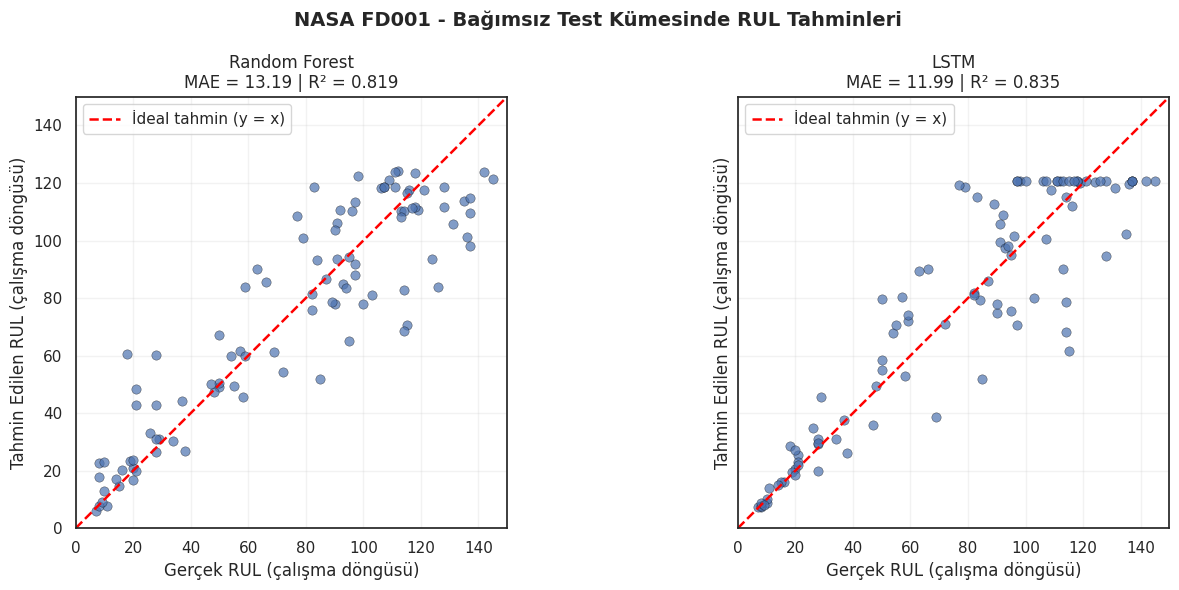

Grafik karşılaştırması 100 bağımsız test motoru üzerinden başarıyla oluşturuldu.


In [62]:


# GERÇEK VE TAHMİN EDİLEN RUL KARŞILAŞTIRMASI

import numpy as np
import matplotlib.pyplot as plt


# 1. ORTAK GRAFİK SINIRLARINI BELİRLEME


tum_degerler = np.concatenate([
    y_test_gercek,
    y_test_rf_pred,
    y_test_lstm_pred
])

grafik_alt_sinir = min(0, float(tum_degerler.min()) - 5)
grafik_ust_sinir = float(tum_degerler.max()) + 5


# 2. İKİ MODEL İÇİN YAN YANA GRAFİKLER


fig, eksenler = plt.subplots(
    1, 2,
    figsize=(14, 6),
    sharex=True,
    sharey=True
)

modeller = [
    (
        "Random Forest",
        y_test_rf_pred,
        rf_test_metrics["MAE"],
        rf_test_metrics["R2"]
    ),
    (
        "LSTM",
        y_test_lstm_pred,
        lstm_test_metrics["MAE"],
        lstm_test_metrics["R2"]
    )
]

for eksen, (model_adi, tahmin, mae, r2) in zip(
    eksenler, modeller
):

    # Her nokta bir test motorunu temsil eder.
    eksen.scatter(
        y_test_gercek,
        tahmin,
        alpha=0.7,
        s=45,
        edgecolors="black",
        linewidths=0.3
    )

    # İdeal tahmin çizgisi: y = x
    eksen.plot(
        [grafik_alt_sinir, grafik_ust_sinir],
        [grafik_alt_sinir, grafik_ust_sinir],
        linestyle="--",
        color="red",
        linewidth=1.8,
        label="İdeal tahmin (y = x)"
    )

    eksen.set_title(
        f"{model_adi}\n"
        f"MAE = {mae:.2f} | R² = {r2:.3f}",
        fontsize=12
    )

    eksen.set_xlabel(
        "Gerçek RUL (çalışma döngüsü)"
    )

    eksen.set_ylabel(
        "Tahmin Edilen RUL (çalışma döngüsü)"
    )

    eksen.set_xlim(
        grafik_alt_sinir,
        grafik_ust_sinir
    )

    eksen.set_ylim(
        grafik_alt_sinir,
        grafik_ust_sinir
    )

    eksen.set_aspect(
        "equal",
        adjustable="box"
    )

    eksen.grid(
        alpha=0.25
    )

    eksen.legend(
        loc="upper left"
    )

plt.suptitle(
    "NASA FD001 - Bağımsız Test Kümesinde RUL Tahminleri",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()


# 3. GRAFİK KONTROLLERİ


assert len(y_test_gercek) == 100
assert len(y_test_rf_pred) == 100
assert len(y_test_lstm_pred) == 100

print(
    "Grafik karşılaştırması 100 bağımsız test motoru "
    "üzerinden başarıyla oluşturuldu."
)



### 7.6. Gerçek ve Tahmin Edilen RUL Grafiklerinin Değerlendirilmesi

Random Forest ve LSTM modellerinin bağımsız NASA FD001 test kümesindeki tahminleri, gerçek ve tahmin edilen RUL değerlerini gösteren dağılım grafikleriyle karşılaştırılmıştır.

Her grafik, **100 bağımsız test motoruna** ait tahminleri içermektedir. Kesikli çapraz çizgi, gerçek ve tahmin edilen RUL değerlerinin eşit olduğu ideal tahmin durumunu göstermektedir.

**Random Forest modelinin değerlendirilmesi:**

Random Forest modelinin tahminleri özellikle düşük RUL değerlerinde ideal çizgiye yakın bir dağılım göstermektedir.

Bununla birlikte orta RUL aralığında hem yüksek hem de düşük tahminlerden kaynaklanan belirgin sapmalar bulunmaktadır.

Yüksek gerçek RUL değerlerinde ise tahminlerin çoğunlukla ideal çizginin altında kaldığı görülmektedir. Bu durum, modelin bazı uzun kalan ömür değerlerini olduğundan düşük tahmin ettiğini göstermektedir.

Random Forest modelinin bağımsız test performansı **MAE = 13,1891** ve **R² = 0,8191** olarak hesaplanmıştır.

**LSTM modelinin değerlendirilmesi:**

LSTM modelinin tahminleri düşük RUL bölgesinde çoğunlukla ideal çizgiye yakın konumlanmaktadır.

Orta RUL aralığında bazı motorlarda belirgin tahmin sapmaları görülmekle birlikte modelin genel test hatası Random Forest modelinden daha düşüktür.

Yüksek RUL bölgesinde LSTM tahminlerinin yaklaşık 120–121 çalışma döngüsü çevresinde yoğunlaştığı dikkat çekmektedir.

Bu bölgede gerçek RUL arttıkça tahminlerin aynı ölçüde artmaması, modelin yüksek kalan ömür değerlerini düşük tahmin etme eğilimi gösterebildiğine işaret etmektedir.

LSTM modelinin bağımsız test performansı **MAE = 11,9941** ve **R² = 0,8351** olarak hesaplanmıştır.

**Eğitim hedefinin sınırlandırılmasıyla ilişkili değerlendirme:**

Model eğitimi sırasında RUL hedefleri 125 çalışma döngüsüyle sınırlandırılmıştır.

Bağımsız test kümesinde ise gerçek RUL değerleri 145 çalışma döngüsüne kadar ulaşmaktadır.

Her iki grafikte yüksek RUL değerlerinde görülen düşük tahmin eğilimi, eğitim hedefinin sınırlandırılmasıyla ilişkili olabilir.

Ancak bu ilişkinin kesin neden-sonuç bağlantısı olduğu yalnızca grafiklerden çıkarılamaz. Daha ayrıntılı değerlendirme için yüksek RUL değerlerine sahip motorların hata sonuçlarının ayrıca incelenmesi gerekmektedir.

**Genel sonuç:**

Grafiksel inceleme, bağımsız test metrikleriyle uyumlu olarak LSTM modelinin genel tahmin performansının Random Forest modelinden daha iyi olduğunu desteklemektedir.

Bununla birlikte her iki modelde de belirgin hataya sahip motorlar ve özellikle yüksek RUL değerlerinde düşük tahmin eğilimleri gözlenmiştir.

Bu nedenle sonraki aşamada motor bazlı mutlak hatalar ve farklı RUL aralıklarındaki hata davranışları analiz edilecektir.



## 8. Hata Analizi ve Model Davranışlarının İncelenmesi

### 8.1. Motor Bazlı Tahmin Hatalarının Analizi

Bu aşamada Random Forest ve LSTM modellerinin bağımsız NASA FD001 test kümesindeki motor bazlı tahmin hataları incelenecektir.

Genel performans metrikleri modellerin ortalama başarısını göstermesine rağmen hangi motorlarda daha büyük hatalar oluştuğunu tek başına açıklamamaktadır.

Bu nedenle 100 bağımsız test motorunun tamamı için:

- Mutlak tahmin hataları karşılaştırılacaktır.
- Her modelin daha başarılı olduğu motor sayısı hesaplanacaktır.
- En yüksek tahmin hatasına sahip motorlar belirlenecektir.
- Gerçek RUL değerlerinin yüksek veya düşük tahmin edilme eğilimleri incelenecektir.

Tahmin hatası aşağıdaki şekilde tanımlanacaktır:

**İşaretli hata = Tahmin edilen RUL − Gerçek RUL**

Pozitif hata, modelin kalan ömrü olduğundan yüksek tahmin ettiğini; negatif hata ise olduğundan düşük tahmin ettiğini göstermektedir.

**Mutlak hata = |Tahmin edilen RUL − Gerçek RUL|**

Mutlak hata, tahminin gerçek değerden kaç çalışma döngüsü uzaklaştığını göstermektedir.

Motor bazlı analiz, modellerin güçlü ve zayıf yönlerinin belirlenmesini ve nihai değerlendirme sonuçlarının daha ayrıntılı yorumlanmasını amaçlamaktadır.


MOTOR BAZLI MODEL KARŞILAŞTIRMASI
-------------------------------------------------------
Random Forest daha başarılı: 45
LSTM daha başarılı: 55
Yaklaşık eşit hata: 0

RANDOM FOREST - EN YÜKSEK 5 MUTLAK HATA
-------------------------------------------------------


,Motor,Gerçek RUL,RF Tahmin,RF Mutlak Hata
44,45,114.0,68.41,45.59
29,30,115.0,70.60,44.40
40,41,18.0,60.70,42.70
73,74,126.0,83.84,42.16
54,55,137.0,97.92,39.08



LSTM - EN YÜKSEK 5 MUTLAK HATA
-------------------------------------------------------


,Motor,Gerçek RUL,LSTM Tahmin,LSTM Mutlak Hata
29,30,115.0,61.650002,53.349998
44,45,114.0,68.070000,45.930000
66,67,77.0,119.239998,42.240002
49,50,79.0,118.709999,39.709999
50,51,114.0,78.739998,35.259998



ORTALAMA İŞARETLİ HATA
-------------------------------------------------------
Random Forest: -0.9663
LSTM: 0.3038


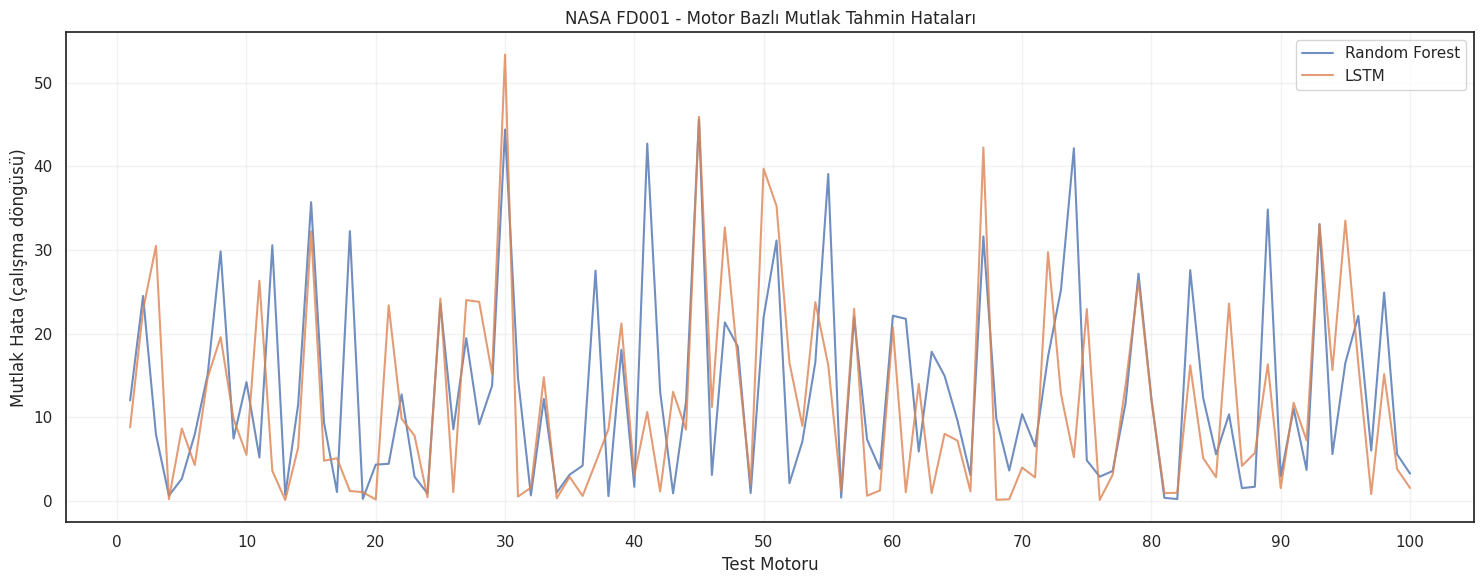


Motor bazlı hata analizi kontrolleri başarılı.


In [63]:


# MOTOR BAZLI HATA ANALİZİ


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# 1. MOTOR BAZLI HATA TABLOSUNU HAZIRLAMA

hata_analizi_df = test_tahmin_tablosu.copy()

hata_analizi_df["RF İşaretli Hata"] = (
    hata_analizi_df["RF Tahmin"]
    - hata_analizi_df["Gerçek RUL"]
)

hata_analizi_df["LSTM İşaretli Hata"] = (
    hata_analizi_df["LSTM Tahmin"]
    - hata_analizi_df["Gerçek RUL"]
)


# 2. HANGİ MODEL KAÇ MOTORDA DAHA BAŞARILI?


rf_daha_iyi = (
    hata_analizi_df["RF Mutlak Hata"]
    < hata_analizi_df["LSTM Mutlak Hata"]
).sum()

lstm_daha_iyi = (
    hata_analizi_df["LSTM Mutlak Hata"]
    < hata_analizi_df["RF Mutlak Hata"]
).sum()

esit_hata = (
    np.isclose(
        hata_analizi_df["RF Mutlak Hata"],
        hata_analizi_df["LSTM Mutlak Hata"]
    )
).sum()

print("MOTOR BAZLI MODEL KARŞILAŞTIRMASI")
print("-" * 55)

print("Random Forest daha başarılı:", rf_daha_iyi)
print("LSTM daha başarılı:", lstm_daha_iyi)
print("Yaklaşık eşit hata:", esit_hata)


# 3. EN YÜKSEK HATALI MOTORLAR


print("\nRANDOM FOREST - EN YÜKSEK 5 MUTLAK HATA")
print("-" * 55)

display(
    hata_analizi_df.nlargest(
        5, "RF Mutlak Hata"
    )[
        ["Motor", "Gerçek RUL", "RF Tahmin", "RF Mutlak Hata"]
    ].round(2)
)

print("\nLSTM - EN YÜKSEK 5 MUTLAK HATA")
print("-" * 55)

display(
    hata_analizi_df.nlargest(
        5, "LSTM Mutlak Hata"
    )[
        ["Motor", "Gerçek RUL", "LSTM Tahmin", "LSTM Mutlak Hata"]
    ].round(2)
)


# 4. ORTALAMA İŞARETLİ HATA


print("\nORTALAMA İŞARETLİ HATA")
print("-" * 55)

print(
    "Random Forest:",
    round(hata_analizi_df["RF İşaretli Hata"].mean(), 4)
)

print(
    "LSTM:",
    round(hata_analizi_df["LSTM İşaretli Hata"].mean(), 4)
)


# 5. MOTOR BAZLI MUTLAK HATA GRAFİĞİ


plt.figure(figsize=(15, 6))

plt.plot(
    hata_analizi_df["Motor"],
    hata_analizi_df["RF Mutlak Hata"],
    label="Random Forest",
    alpha=0.8,
    linewidth=1.5
)

plt.plot(
    hata_analizi_df["Motor"],
    hata_analizi_df["LSTM Mutlak Hata"],
    label="LSTM",
    alpha=0.8,
    linewidth=1.5
)

plt.xlabel("Test Motoru")
plt.ylabel("Mutlak Hata (çalışma döngüsü)")

plt.title(
    "NASA FD001 - Motor Bazlı Mutlak Tahmin Hataları"
)

plt.xticks(np.arange(0, 101, 10))

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()


# 6. KONTROLLER

assert len(hata_analizi_df) == 100

assert (
    rf_daha_iyi + lstm_daha_iyi + esit_hata == 100
), "Motor sayısı kontrolünde tutarsızlık var."

print("\nMotor bazlı hata analizi kontrolleri başarılı.")



### 8.2. Motor Bazlı Hata Analizi Sonuçlarının Değerlendirilmesi

Random Forest ve LSTM modellerinin bağımsız NASA FD001 test kümesindeki tahmin hataları, 100 motor üzerinden karşılaştırılmıştır.

**Motor bazlı karşılaştırma sonuçları:**

- Random Forest'ın daha düşük mutlak hata elde ettiği motor sayısı: **45**
- LSTM'nin daha düşük mutlak hata elde ettiği motor sayısı: **55**
- Yaklaşık eşit mutlak hata bulunan motor sayısı: **0**

Bu sonuçlar, LSTM modelinin motorların %55'inde Random Forest modelinden daha düşük mutlak tahmin hatası elde ettiğini göstermektedir.

Bununla birlikte Random Forest'ın motorların %45'inde daha başarılı olması, LSTM'nin her motor için üstün olmadığını ortaya koymaktadır.

**En yüksek tahmin hatalarının incelenmesi:**

Random Forest modelinde en yüksek mutlak hata, **Motor 45** için elde edilmiştir. Bu motorun gerçek RUL değeri 114 çalışma döngüsü iken model tahmini 68,41 döngüdür. Mutlak hata **45,59 döngü** olarak hesaplanmıştır.

LSTM modelinde en yüksek mutlak hata ise **Motor 30** için elde edilmiştir. Gerçek RUL değeri 115 çalışma döngüsü iken LSTM tahmini yaklaşık 61,65 döngüdür. Mutlak hata **53,35 döngü** olarak hesaplanmıştır.

Motor 30 ve Motor 45, her iki modelin de yüksek hata yaptığı örnekler arasındadır.

LSTM modelinin Motor 67 için ürettiği tahmin de dikkat çekmektedir. Gerçek RUL değeri 77 döngü olmasına rağmen model yaklaşık 119,24 döngü tahmin etmiştir. Bu örnekte model, kalan faydalı ömrü yaklaşık 42,24 döngü yüksek tahmin etmiştir.

**Ortalama işaretli hata analizi:**

- Random Forest ortalama işaretli hata: **−0,9663**
- LSTM ortalama işaretli hata: **+0,3038**

Random Forest modelinin ortalama işaretli hatası hafif negatif, LSTM modelinin ise sıfıra yakın ve hafif pozitiftir.

Bu sonuçlar, tüm test motorları üzerinden hesaplanan ortalama hatalarda güçlü bir yönlü yanlılık bulunmadığını düşündürmektedir.

Ancak pozitif ve negatif hataların birbirini dengeleyebilmesi nedeniyle ortalama işaretli hata tek başına yeterli değildir. Bu nedenle sonuçlar mutlak hatalarla birlikte değerlendirilmiştir.

**Grafiksel değerlendirme:**

Motor bazlı mutlak hata grafiği, modellerin bazı motorlarda benzer hata değerleri üretirken bazı motorlarda belirgin biçimde farklılaştığını göstermektedir.

Her iki modelin de yüksek hata yaptığı motorlar bulunmaktadır. Ayrıca modellerden birinin başarılı olduğu bazı motorlarda diğer modelin daha yüksek hata üretebildiği görülmektedir.

Bu bulgu, genel performans metriklerinin tek başına tüm motorların tahmin başarısını açıklamak için yeterli olmadığını göstermektedir.

**Genel sonuç:**

LSTM modeli, bağımsız test kümesindeki 100 motorun 55'inde daha düşük mutlak hata elde etmiş ve genel MAE açısından Random Forest modelinden daha başarılı olmuştur.

Bununla birlikte her iki modelde de yüksek tahmin hatasına sahip motorlar bulunmaktadır.

Özellikle kalan faydalı ömrün olduğundan yüksek tahmin edildiği durumlar, kestirimci bakım uygulamalarında operasyonel risk oluşturabileceğinden ayrıca önem taşımaktadır.

Sonraki aşamada, gerçek RUL değerlerine göre farklı motor gruplarındaki hata davranışları incelenerek modellerin hangi kalan ömür aralıklarında daha başarılı olduğu değerlendirilecektir.



### 8.3. Gerçek RUL Aralıklarına Göre Hata Analizi

Bu aşamada Random Forest ve LSTM modellerinin bağımsız NASA FD001 test kümesindeki tahmin hataları, motorların gerçek kalan faydalı ömür (RUL) değerlerine göre incelenecektir.

Genel performans metrikleri modellerin ortalama tahmin başarısını göstermektedir. Ancak modellerin farklı kalan ömür aralıklarında aynı başarı düzeyine sahip olup olmadığı ayrıca değerlendirilmelidir.

Bu amaçla test motorları dört gruba ayrılacaktır:

- **0–30 döngü:** Arızaya yakın motorlar
- **31–60 döngü:** Düşük kalan ömür
- **61–125 döngü:** Orta ve yüksek kalan ömür
- **125'in üzeri:** Eğitim hedefi sınırının üzerindeki motorlar

Her grup için motor sayısı, ortalama mutlak hata (MAE) ve ortalama işaretli hata hesaplanacaktır.

İşaretli hata, tahmin edilen RUL değerinden gerçek RUL değerinin çıkarılmasıyla elde edilmektedir.

Negatif işaretli hata, modelin kalan ömrü olduğundan düşük; pozitif işaretli hata ise olduğundan yüksek tahmin ettiğini göstermektedir.

**Önemli yöntemsel ayrıntı:**

Eğitim sırasında RUL hedefleri 125 çalışma döngüsüyle sınırlandırılmıştır. Bağımsız test kümesinde ise gerçek RUL değerleri 145 döngüye kadar ulaşmaktadır.

Bu nedenle özellikle 125'in üzerindeki gerçek RUL değerlerine sahip motorların tahminleri ayrıca incelenecektir.

Bu analiz, modellerin farklı RUL aralıklarındaki güçlü ve zayıf yönlerini ortaya koymayı ve hedef sınırlandırmasının olası etkilerini değerlendirmeyi amaçlamaktadır.


RUL ARALIKLARINA GÖRE TEST PERFORMANSI
-----------------------------------------------------------------


,RUL Grubu,Motor Sayısı,RF MAE,LSTM MAE,RF Ortalama İşaretli Hata,LSTM Ortalama İşaretli Hata
0,0–30,25,8.7535,3.060400,7.8971,2.078500
1,31–60,14,7.0382,11.278400,2.1543,6.825800
2,61–125,50,14.4307,15.262600,-0.8843,1.694700
3,>125,11,25.4545,18.352501,-25.4545,-18.352501


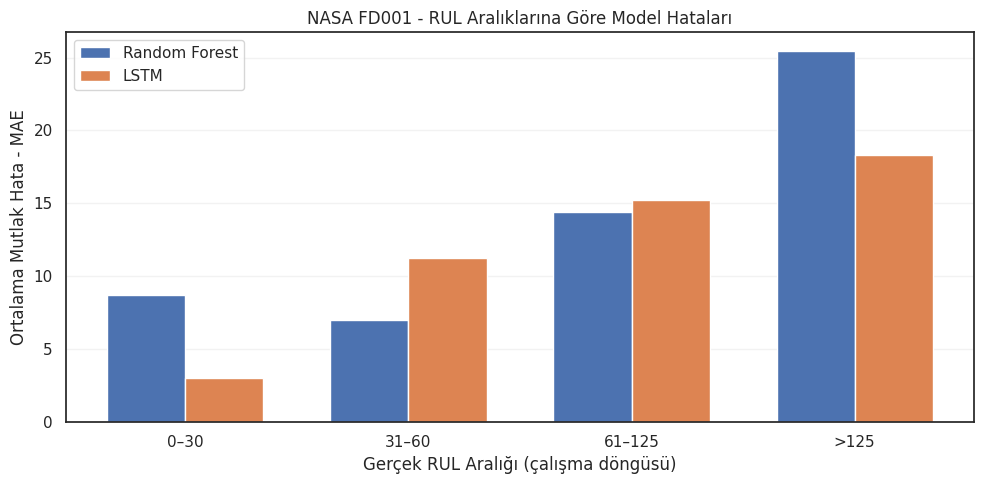


GERÇEK RUL > 125 OLAN MOTORLAR
-----------------------------------------------------------------
Bu gruptaki motor sayısı: 11


,Motor,Gerçek RUL,RF Tahmin,LSTM Tahmin,RF İşaretli Hata,LSTM İşaretli Hata
24,25,145.0,121.43,120.809998,-23.57,-24.190001
38,39,142.0,123.94,120.800003,-18.06,-21.200001
46,47,135.0,113.66,102.300003,-21.34,-32.700001
54,55,137.0,97.92,120.779999,-39.08,-16.219999
64,65,128.0,118.43,120.809998,-9.57,-7.190000
72,73,131.0,105.79,118.209999,-25.21,-12.790000
73,74,126.0,83.84,120.790001,-42.16,-5.210000
82,83,137.0,109.42,120.820000,-27.58,-16.180000
88,89,136.0,101.17,119.690002,-34.83,-16.309999
94,95,128.0,111.51,94.500000,-16.49,-33.500000



RUL aralığı hata analizi kontrolleri başarılı.


In [64]:


# RUL ARALIKLARINA GÖRE HATA ANALİZİ


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# 1. GERÇEK RUL DEĞERLERİNE GÖRE GRUPLAMA

rul_grup_df = hata_analizi_df.copy()

rul_gruplari = [
    "0–30",
    "31–60",
    "61–125",
    ">125"
]

rul_grup_df["RUL Grubu"] = pd.cut(
    rul_grup_df["Gerçek RUL"],
    bins=[-np.inf, 30, 60, 125, np.inf],
    labels=rul_gruplari,
    right=True
)


# 2. GRUP BAZLI PERFORMANS HESAPLAMA


grup_sonuclari = []

for grup_adi, grup_verisi in rul_grup_df.groupby(
    "RUL Grubu",
    observed=True
):

    grup_sonuclari.append({
        "RUL Grubu": str(grup_adi),
        "Motor Sayısı": len(grup_verisi),

        "RF MAE": grup_verisi[
            "RF Mutlak Hata"
        ].mean(),

        "LSTM MAE": grup_verisi[
            "LSTM Mutlak Hata"
        ].mean(),

        "RF Ortalama İşaretli Hata": grup_verisi[
            "RF İşaretli Hata"
        ].mean(),

        "LSTM Ortalama İşaretli Hata": grup_verisi[
            "LSTM İşaretli Hata"
        ].mean()
    })

rul_grup_sonuclari = pd.DataFrame(
    grup_sonuclari
)

# Grupları önceden belirlenen sırada göster.
rul_grup_sonuclari["RUL Grubu"] = pd.Categorical(
    rul_grup_sonuclari["RUL Grubu"],
    categories=rul_gruplari,
    ordered=True
)

rul_grup_sonuclari = (
    rul_grup_sonuclari
    .sort_values("RUL Grubu")
    .reset_index(drop=True)
)

print("RUL ARALIKLARINA GÖRE TEST PERFORMANSI")
print("-" * 65)

display(
    rul_grup_sonuclari.round(4)
)


# 3. GRUP BAZLI MAE GRAFİĞİ


x = np.arange(len(rul_grup_sonuclari))
bar_genisligi = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - bar_genisligi / 2,
    rul_grup_sonuclari["RF MAE"],
    width=bar_genisligi,
    label="Random Forest"
)

ax.bar(
    x + bar_genisligi / 2,
    rul_grup_sonuclari["LSTM MAE"],
    width=bar_genisligi,
    label="LSTM"
)

ax.set_xticks(x)
ax.set_xticklabels(
    rul_grup_sonuclari["RUL Grubu"].astype(str)
)

ax.set_xlabel("Gerçek RUL Aralığı (çalışma döngüsü)")
ax.set_ylabel("Ortalama Mutlak Hata - MAE")

ax.set_title(
    "NASA FD001 - RUL Aralıklarına Göre Model Hataları"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# 4. YÜKSEK RUL MOTORLARINI AYRINTILI GÖSTERME


yuksek_rul_motorlari = rul_grup_df[
    rul_grup_df["Gerçek RUL"] > 125
].copy()

print("\nGERÇEK RUL > 125 OLAN MOTORLAR")
print("-" * 65)

print(
    "Bu gruptaki motor sayısı:",
    len(yuksek_rul_motorlari)
)

if len(yuksek_rul_motorlari) > 0:

    display(
        yuksek_rul_motorlari[
            [
                "Motor",
                "Gerçek RUL",
                "RF Tahmin",
                "LSTM Tahmin",
                "RF İşaretli Hata",
                "LSTM İşaretli Hata"
            ]
        ].round(2)
    )

else:
    print("Bu aralıkta test motoru bulunmuyor.")


# 5. VERİ BÜTÜNLÜĞÜ KONTROLLERİ


assert len(rul_grup_df) == 100

assert rul_grup_df["RUL Grubu"].notna().all()

assert (
    rul_grup_sonuclari["Motor Sayısı"].sum() == 100
)

print("\nRUL aralığı hata analizi kontrolleri başarılı.")



### 8.4. RUL Aralıklarına Göre Hata Analizi Sonuçlarının Değerlendirilmesi

Random Forest ve LSTM modellerinin bağımsız NASA FD001 test kümesindeki performansları, gerçek kalan faydalı ömür (RUL) değerlerine göre dört grupta incelenmiştir.

**RUL aralıklarına göre performans sonuçları:**

| Gerçek RUL Aralığı | Motor Sayısı | Random Forest MAE | LSTM MAE |
|---|---:|---:|---:|
| 0–30 | 25 | 8,7535 | 3,0604 |
| 31–60 | 14 | 7,0382 | 11,2784 |
| 61–125 | 50 | 14,4307 | 15,2626 |
| 125'in üzeri | 11 | 25,4545 | 18,3525 |

**Arızaya yakın motorların değerlendirilmesi:**

Gerçek RUL değeri 0–30 çalışma döngüsü arasında bulunan 25 motor için Random Forest modelinin MAE değeri 8,7535, LSTM modelinin MAE değeri ise 3,0604 olarak hesaplanmıştır.

LSTM modeli, bu grupta Random Forest'a göre ortalama mutlak tahmin hatasını yaklaşık **%65,04 oranında azaltmıştır**.

Bu sonuç, incelenen test motorları kapsamında LSTM modelinin arızaya yakın motorların kalan ömrünü tahmin etmede daha başarılı olduğunu göstermektedir.

Kestirimci bakım uygulamalarında arızaya yakın motorların kalan ömrünün doğru tahmin edilmesi, bakım planlaması açısından özellikle önemlidir.

**Orta RUL aralıklarının değerlendirilmesi:**

31–60 çalışma döngüsü aralığındaki 14 motorda Random Forest modelinin MAE değeri 7,0382, LSTM modelinin MAE değeri ise 11,2784 olmuştur.

61–125 çalışma döngüsü aralığındaki 50 motorda ise Random Forest için MAE 14,4307, LSTM için 15,2626 olarak hesaplanmıştır.

Bu sonuçlar, Random Forest modelinin söz konusu iki RUL aralığında daha düşük ortalama mutlak hata elde ettiğini göstermektedir.

Dolayısıyla LSTM modelinin genel test kümesindeki üstünlüğü, bütün RUL aralıklarında daha başarılı olduğu anlamına gelmemektedir.

**125'in üzerindeki RUL değerlerinin değerlendirilmesi:**

Gerçek RUL değeri 125'in üzerinde olan 11 motor belirlenmiştir.

Bu grupta Random Forest modelinin MAE değeri 25,4545, LSTM modelinin MAE değeri ise 18,3525 olarak hesaplanmıştır.

Ortalama işaretli hatalar Random Forest için **−25,4545**, LSTM için **−18,3525** olmuştur.

Motor bazlı sonuçlar incelendiğinde, her iki modelin de bu 11 motorun tamamında gerçek RUL değerini olduğundan düşük tahmin ettiği görülmüştür.

Eğitim sırasında RUL hedeflerinin 125 çalışma döngüsüyle sınırlandırılması, yüksek RUL değerlerindeki bu davranışın olası nedenlerinden biridir.

Ancak hedef sınırlandırmasının hatalar üzerindeki nedensel etkisini kesin olarak belirlemek için farklı sınırlandırma değerleriyle kontrollü deneyler yapılması gerekir.

**İşaretli hata değerlendirmesi:**

0–30 RUL aralığında Random Forest modelinin ortalama işaretli hatası +7,8971, LSTM modelinin ise +2,0785 olarak hesaplanmıştır.

Bu sonuç, arızaya yakın motorlarda her iki modelin de ortalamada kalan ömrü yüksek tahmin etme eğilimi gösterdiğini, ancak LSTM modelinin ortalama sapmasının daha düşük olduğunu ortaya koymaktadır.

61–125 aralığında ortalama işaretli hataların sıfıra yakın olmasına rağmen mutlak hataların daha yüksek olması, pozitif ve negatif tahmin hatalarının birbirini dengeleyebildiğini göstermektedir.

**Genel sonuç:**

RUL aralıklarına göre gerçekleştirilen analiz, modellerin başarısının motorların gerçek kalan ömür düzeyine göre değiştiğini göstermiştir.

LSTM modeli özellikle 0–30 ve 125'in üzerindeki RUL aralıklarında daha düşük MAE elde ederken Random Forest modeli 31–60 ve 61–125 aralıklarında daha başarılı olmuştur.

Bağımsız test kümesinde LSTM'nin genel olarak daha düşük MAE elde etmesiyle birlikte, özellikle arızaya yakın motorlarda daha düşük hata üretmesi çalışmanın önemli bulgularından biridir.

Bununla birlikte yüksek RUL değerlerinde her iki modelin de sistematik düşük tahmin eğilimi göstermesi, geliştirilmesi gereken bir sınırlılık olarak değerlendirilmiştir.

Bu bulgular, modellerin yalnızca genel performans metrikleriyle değil, farklı çalışma koşulları ve kalan ömür aralıkları üzerinden de değerlendirilmesi gerektiğini ortaya koymaktadır.



### 8.5. LSTM Eğitim ve Doğrulama Sürecinin Grafiksel İncelenmesi

Bu aşamada LSTM modelinin eğitim sürecindeki öğrenme davranışı incelenecektir.

Model eğitimi sırasında kaydedilen eğitim ve doğrulama kayıp değerleri kullanılarak iki grafik oluşturulacaktır:

- **MSE (Loss) grafiği:** Eğitim ve doğrulama kayıplarının epoch boyunca değişimi.
- **MAE grafiği:** Eğitim ve doğrulama ortalama mutlak hatalarının epoch boyunca değişimi.

Bu grafiklerin amacı modelin eğitim sırasında nasıl öğrendiğini, doğrulama performansının nasıl değiştiğini ve aşırı öğrenme (overfitting) belirtilerini değerlendirmektir.

LSTM modeli, en fazla 40 epoch eğitilecek şekilde yapılandırılmış ve doğrulama kaybını izleyen EarlyStopping mekanizması kullanılmıştır.

EarlyStopping mekanizması, doğrulama kaybında belirlenen süre boyunca iyileşme olmadığında eğitimi durdurmakta ve en iyi doğrulama performansına sahip model ağırlıklarını geri yüklemektedir.

Eğitim ve doğrulama eğrilerinin birlikte incelenmesi, modelin öğrenme sürecinin ve genelleme davranışının daha ayrıntılı değerlendirilmesini sağlayacaktır.


LSTM EĞİTİM GEÇMİŞİ
-------------------------------------------------------
Gerçekleşen epoch sayısı: 36
En iyi doğrulama epoch'u: 29
En düşük doğrulama MSE: 199.1349
En düşük doğrulama MAE: 9.2506


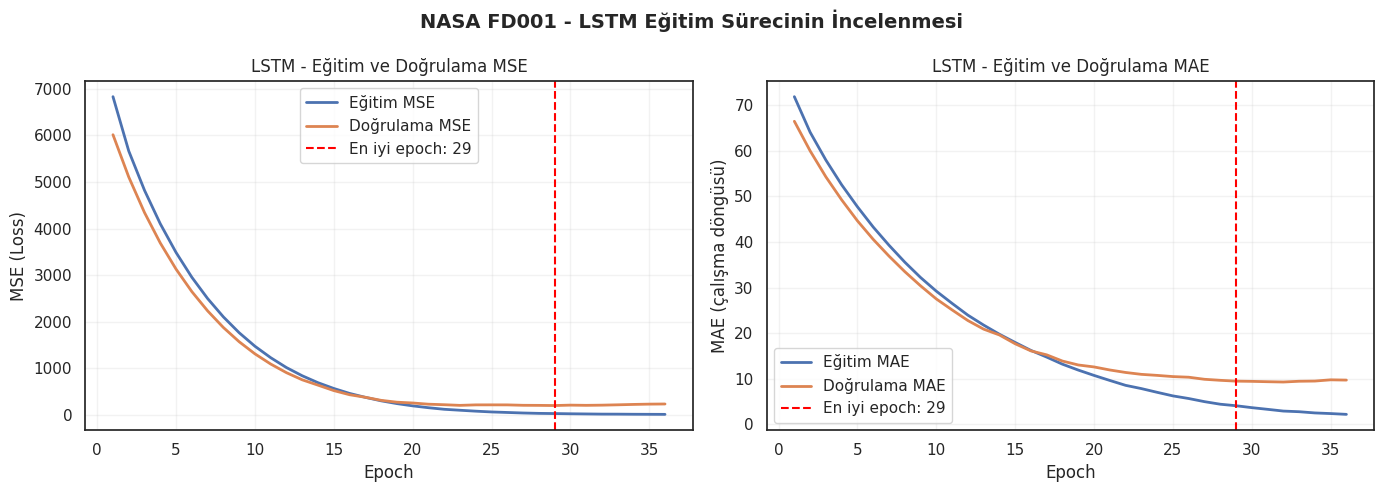


LSTM eğitim geçmişi kontrolleri başarılı.


In [65]:


# LSTM EĞİTİM VE DOĞRULAMA KAYIP GRAFİKLERİ


import numpy as np
import matplotlib.pyplot as plt


# 1. LSTM EĞİTİM GEÇMİŞİNİ HAZIRLAMA


egitim_gecmisi = lstm_history.history

epoch_sayisi = len(egitim_gecmisi["loss"])
epochlar = np.arange(1, epoch_sayisi + 1)

egitim_loss = egitim_gecmisi["loss"]
dogrulama_loss = egitim_gecmisi["val_loss"]

egitim_mae = egitim_gecmisi["mae"]
dogrulama_mae = egitim_gecmisi["val_mae"]

en_iyi_epoch = np.argmin(dogrulama_loss) + 1

print("LSTM EĞİTİM GEÇMİŞİ")
print("-" * 55)

print("Gerçekleşen epoch sayısı:", epoch_sayisi)
print("En iyi doğrulama epoch'u:", en_iyi_epoch)

print(
    "En düşük doğrulama MSE:",
    round(min(dogrulama_loss), 4)
)

print(
    "En düşük doğrulama MAE:",
    round(min(dogrulama_mae), 4)
)


# 2. LOSS (MSE) GRAFİĞİ


fig, eksenler = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

eksenler[0].plot(
    epochlar,
    egitim_loss,
    label="Eğitim MSE",
    linewidth=2
)

eksenler[0].plot(
    epochlar,
    dogrulama_loss,
    label="Doğrulama MSE",
    linewidth=2
)

eksenler[0].axvline(
    en_iyi_epoch,
    color="red",
    linestyle="--",
    label=f"En iyi epoch: {en_iyi_epoch}"
)

eksenler[0].set_title(
    "LSTM - Eğitim ve Doğrulama MSE"
)

eksenler[0].set_xlabel("Epoch")
eksenler[0].set_ylabel("MSE (Loss)")

eksenler[0].grid(alpha=0.25)
eksenler[0].legend()


# 3. MAE GRAFİĞİ


eksenler[1].plot(
    epochlar,
    egitim_mae,
    label="Eğitim MAE",
    linewidth=2
)

eksenler[1].plot(
    epochlar,
    dogrulama_mae,
    label="Doğrulama MAE",
    linewidth=2
)

eksenler[1].axvline(
    en_iyi_epoch,
    color="red",
    linestyle="--",
    label=f"En iyi epoch: {en_iyi_epoch}"
)

eksenler[1].set_title(
    "LSTM - Eğitim ve Doğrulama MAE"
)

eksenler[1].set_xlabel("Epoch")
eksenler[1].set_ylabel("MAE (çalışma döngüsü)")

eksenler[1].grid(alpha=0.25)
eksenler[1].legend()

plt.suptitle(
    "NASA FD001 - LSTM Eğitim Sürecinin İncelenmesi",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# 4. KONTROLLER


assert epoch_sayisi > 0

assert len(egitim_loss) == len(dogrulama_loss)
assert len(egitim_mae) == len(dogrulama_mae)

print("\nLSTM eğitim geçmişi kontrolleri başarılı.")



### 8.6. LSTM Eğitim ve Doğrulama Sürecinin Değerlendirilmesi

LSTM modelinin eğitim süreci, eğitim ve doğrulama veri kümelerinde elde edilen MSE (Loss) ve MAE değerlerinin epoch boyunca değişimi üzerinden incelenmiştir.

**Eğitim sürecinin temel sonuçları:**

- Gerçekleşen epoch sayısı: **36**
- En iyi doğrulama MSE değerinin elde edildiği epoch: **29**
- En düşük doğrulama MSE: **199,1349**
- Eğitim geçmişinde gözlenen en düşük doğrulama MAE: **9,2506**

**MSE grafiğinin değerlendirilmesi:**

Eğitim ve doğrulama MSE değerlerinin ilk epoch'larda hızlı biçimde azaldığı görülmektedir.

Bu durum, LSTM modelinin eğitim sürecinde sensör verilerindeki örüntüleri öğrenerek tahmin hatasını azalttığını göstermektedir.

İlerleyen epoch'larda eğitim kaybı azalmaya devam ederken doğrulama kaybındaki iyileşmenin yavaşladığı gözlenmiştir.

En düşük doğrulama MSE değeri 29. epoch'ta elde edilmiştir.

Sonraki epoch'larda doğrulama kaybında kalıcı bir iyileşme görülmemesi nedeniyle EarlyStopping mekanizması eğitimi 36. epoch sonunda durdurmuştur.

**MAE grafiğinin değerlendirilmesi:**

Eğitim MAE değerinin epoch'lar boyunca azalmaya devam ettiği, doğrulama MAE değerinin ise başlangıçta hızlı azaldıktan sonra yaklaşık 9–10 çalışma döngüsü seviyesinde yataylaştığı görülmektedir.

Eğitim ve doğrulama eğrileri arasındaki farkın ilerleyen epoch'larda artması, aşırı öğrenme (overfitting) belirtileriyle uyumludur.

Ancak bu durum tek başına modelin bağımsız test kümesinde başarısız olacağı anlamına gelmemektedir.

**EarlyStopping mekanizmasının değerlendirilmesi:**

Model eğitiminde doğrulama MSE değerini izleyen EarlyStopping mekanizması kullanılmıştır.

Bu mekanizma, doğrulama kaybında belirlenen süre boyunca iyileşme görülmediğinde eğitimi durdurmuş ve en iyi doğrulama performansına sahip ağırlıkları geri yüklemiştir.

Böylece eğitim sürecinin gereksiz yere uzaması önlenmiş ve modelin doğrulama performansı açısından en uygun ağırlıkları korunmuştur.

**Genel sonuç:**

LSTM modelinin eğitim geçmişi, modelin ilk epoch'larda belirgin biçimde öğrendiğini ve ilerleyen aşamalarda doğrulama performansının doygunluğa ulaştığını göstermektedir.

Eğitimin son bölümünde eğitim ve doğrulama hataları arasındaki farkın artması, sınırlı düzeyde aşırı öğrenme belirtilerine işaret etmektedir.

EarlyStopping ve en iyi ağırlıkların geri yüklenmesi, bu durumu kontrol altında tutmak amacıyla uygulanmıştır.

Bu bulgular, bağımsız test kümesinde elde edilen sonuçlarla birlikte değerlendirildiğinde, LSTM modelinin öğrenme sürecinin genel olarak başarılı olduğunu ancak genelleme performansının daha da iyileştirilebileceğini göstermektedir.



### 8.7. Random Forest Özellik Önemlerinin İncelenmesi

Bu aşamada Random Forest modelinin kalan faydalı ömür (RUL) tahmininde kullandığı giriş özelliklerinin önem düzeyleri incelenecektir.

Random Forest modeli, eğitim sırasında her karar ağacında gerçekleştirilen bölünmelerin hata azaltımına katkısından yararlanarak özellik önemlerini hesaplamaktadır.

Bu analiz kapsamında:

- Modelde kullanılan 18 giriş özelliğinin önem değerleri elde edilecektir.
- Özellikler önem düzeylerine göre sıralanacaktır.
- En yüksek öneme sahip 10 özellik görselleştirilecektir.

Özellik önemleri, modelin tahmin kararlarını hangi değişkenlere daha fazla dayandırdığını anlamaya yardımcı olmaktadır.

Ancak bu değerler doğrudan nedensellik göstermemektedir. Ayrıca birbiriyle yüksek korelasyon gösteren sensörlerin önemleri model tarafından farklı biçimlerde dağıtılabilir.

Bu nedenle sonuçlar, Random Forest modelinin öğrenilmiş tahmin davranışını açıklayan göstergeler olarak değerlendirilecektir.


RANDOM FOREST - TÜM ÖZELLİK ÖNEMLERİ
-------------------------------------------------------


,Özellik,Önem Değeri
0,sensor_11,0.5042
1,cycle,0.2569
2,sensor_9,0.0552
3,sensor_4,0.0477
4,sensor_12,0.0211
5,sensor_7,0.0174
6,sensor_14,0.0159
7,sensor_15,0.0152
8,sensor_21,0.0103
9,sensor_2,0.0100



EN ÖNEMLİ 10 ÖZELLİK
-------------------------------------------------------


,Özellik,Önem Değeri
0,sensor_11,0.5042
1,cycle,0.2569
2,sensor_9,0.0552
3,sensor_4,0.0477
4,sensor_12,0.0211
5,sensor_7,0.0174
6,sensor_14,0.0159
7,sensor_15,0.0152
8,sensor_21,0.0103
9,sensor_2,0.0100


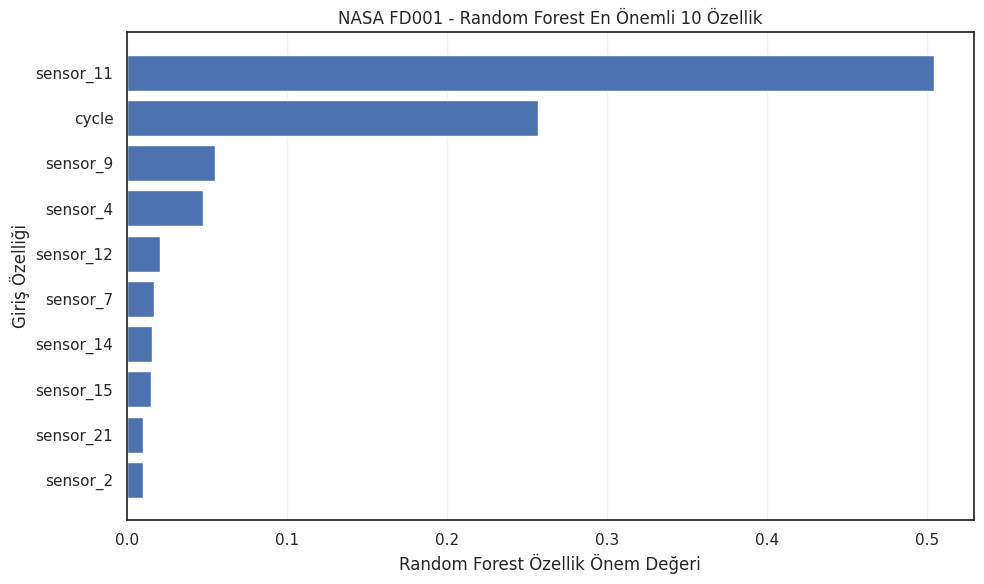


Özellik önemi kontrolleri başarılı.
Önem değerlerinin toplamı: 1.0
En önemli özellik: sensor_11


In [66]:


# RANDOM FOREST ÖZELLİK ÖNEMLERİ


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# 1. MODELİN ÖZELLİK SAYISINI KONTROL ETME


assert len(ozellik_sutunlari) == 18

assert rf_model.n_features_in_ == len(ozellik_sutunlari)

# Eğitimde kullanılan özellik sırasını doğrula.
if hasattr(rf_model, "feature_names_in_"):
    assert list(rf_model.feature_names_in_) == list(
        ozellik_sutunlari
    )


# 2. ÖZELLİK ÖNEMLERİNİ ELDE ETME


ozellik_onemleri = rf_model.feature_importances_

ozellik_onem_tablosu = pd.DataFrame({
    "Özellik": ozellik_sutunlari,
    "Önem Değeri": ozellik_onemleri
})

ozellik_onem_tablosu = (
    ozellik_onem_tablosu
    .sort_values(
        by="Önem Değeri",
        ascending=False
    )
    .reset_index(drop=True)
)

print("RANDOM FOREST - TÜM ÖZELLİK ÖNEMLERİ")
print("-" * 55)

display(
    ozellik_onem_tablosu.round(4)
)


# 3. EN ÖNEMLİ 10 ÖZELLİĞİ GÖSTERME


ilk_10_ozellik = ozellik_onem_tablosu.head(10).copy()

print("\nEN ÖNEMLİ 10 ÖZELLİK")
print("-" * 55)

display(
    ilk_10_ozellik.round(4)
)


# 4. ÖZELLİK ÖNEMİ GRAFİĞİ
# En önemli özellik grafiğin üstünde olacak.
grafik_verisi = ilk_10_ozellik.iloc[::-1]

plt.figure(figsize=(10, 6))

plt.barh(
    grafik_verisi["Özellik"],
    grafik_verisi["Önem Değeri"]
)

plt.xlabel("Random Forest Özellik Önem Değeri")
plt.ylabel("Giriş Özelliği")

plt.title(
    "NASA FD001 - Random Forest En Önemli 10 Özellik"
)

plt.grid(
    axis="x",
    alpha=0.25
)

plt.tight_layout()
plt.show()


# 5. KONTROLLER

assert len(ozellik_onem_tablosu) == 18

assert np.isfinite(ozellik_onemleri).all()

assert np.all(ozellik_onemleri >= 0)

assert np.isclose(
    ozellik_onemleri.sum(),
    1.0
)

print("\nÖzellik önemi kontrolleri başarılı.")

print(
    "Önem değerlerinin toplamı:",
    round(ozellik_onemleri.sum(), 4)
)

print(
    "En önemli özellik:",
    ozellik_onem_tablosu.iloc[0]["Özellik"]
)



### 8.8. Random Forest Özellik Önemlerinin Değerlendirilmesi

Random Forest modelinin RUL tahmininde kullandığı 18 giriş özelliği, model tarafından hesaplanan özellik önem değerleri üzerinden incelenmiştir.

Özellik önemlerinin toplamının **1,0** olduğu ve bütün değerlerin negatif olmayan sonlu sayılardan oluştuğu doğrulanmıştır.

**En önemli beş özellik:**

| Sıra | Özellik | Önem Değeri |
|---|---|---:|
| 1 | sensor_11 | 0,5042 |
| 2 | cycle | 0,2569 |
| 3 | sensor_9 | 0,0552 |
| 4 | sensor_4 | 0,0477 |
| 5 | sensor_12 | 0,0211 |

**Sonuçların değerlendirilmesi:**

Random Forest modelinde en yüksek özellik önem değeri **sensor_11** değişkeninde elde edilmiştir.

Bu sensörün önem değeri **0,5042** olup toplam özellik öneminin yaklaşık **%50,42'sine** karşılık gelmektedir.

İkinci en önemli değişken, **0,2569** önem değeriyle motorun çalışma döngüsünü temsil eden **cycle** değişkenidir.

Bu iki özellik birlikte toplam önem değerinin yaklaşık **%76,11'ini** oluşturmaktadır.

Bu bulgu, eğitilen Random Forest modelinin tahmin kararlarında özellikle sensor_11 ölçümünden ve motorun çalışma döngüsü bilgisinden yararlandığını göstermektedir.

Daha önce gerçekleştirilen keşifsel veri analizinde bazı sensörlerin motor çalışma süreci boyunca değişim gösterdiği belirlenmiştir. sensor_11 değişkeninin yüksek önem değerine sahip olması, bu sensörün model tarafından RUL tahmini açısından yararlı bir gösterge olarak kullanıldığına işaret etmektedir.

sensor_9 ve sensor_4 değişkenleri de modelin tahminlerine katkıda bulunmaktadır. Ancak bunların önem değerleri ilk iki özellikten daha düşüktür.

sensor_6 değişkeninin önem değeri dört ondalık basamakla **0,0000** olarak görüntülenmiştir. Bu sonuç, ilgili değişkenin eğitilen Random Forest modelindeki katkısının bulunmadığını veya çok düşük düzeyde olduğunu göstermektedir. Ancak sensörün bütün modelleme yaklaşımları için gereksiz olduğu sonucuna varılamaz.

**Yöntemsel sınırlılıklar:**

Random Forest özellik önemleri, karar ağaçlarındaki bölünmelerin hata azaltımına katkısı üzerinden hesaplanmaktadır.

Bu nedenle önem değerleri doğrudan nedensel ilişki göstermemektedir.

Ayrıca yüksek korelasyona sahip sensörlerin önem değerleri model içerisinde farklı biçimlerde dağılabilir. Bu durum, değişkenlerin tek tek önemlerinin yorumlanmasını etkileyebilir.

Elde edilen özellik önemleri yalnızca Random Forest modelinin öğrenilmiş tahmin davranışını açıklamaktadır. LSTM modelinin aynı özellikleri aynı önem düzeyinde kullandığı sonucu çıkarılamaz.

**Genel sonuç:**

Random Forest özellik önemi analizi, modelin RUL tahminlerinde özellikle **sensor_11** ve **cycle** değişkenlerine dayandığını göstermiştir.

Bu analiz, modelin tahmin davranışının yorumlanmasına katkı sağlamış ve çalışmanın açıklanabilirlik yönünü güçlendirmiştir.

Gelecekte farklı özellik önem yöntemleri ve özellik çıkarma yaklaşımları kullanılarak sensörlerin tahmin performansına katkısı daha ayrıntılı değerlendirilebilir.



## 9. Sonuçlar, Sınırlılıklar ve Geliştirme Önerileri

### 9.1. Çalışmanın Genel Sonuçları

Bu projede, NASA C-MAPSS FD001 veri seti kullanılarak uçak motorlarının kalan faydalı ömrünün (Remaining Useful Life, RUL) tahmin edilmesi amaçlanmıştır.

Bu amaç doğrultusunda iki farklı modelleme yaklaşımı uygulanmıştır:

- **Random Forest Regressor:** Tek bir çalışma döngüsündeki özelliklerden yararlanan makine öğrenmesi modeli.
- **Long Short-Term Memory (LSTM):** Ardışık 30 çalışma döngüsündeki sensör ve operasyonel özelliklerden yararlanan derin öğrenme modeli.

Veri keşfi, eksik değer kontrolü, özellik seçimi, RUL hedefinin oluşturulması, motor bazlı eğitim/doğrulama ayrımı ve ölçeklendirme işlemleri gerçekleştirilmiştir.

Modellerin değerlendirilmesinde MAE, MSE, RMSE ve R² regresyon metrikleri kullanılmıştır. Nihai performans karşılaştırması, eğitim ve doğrulama aşamalarında kullanılmamış 100 bağımsız NASA FD001 test motoru üzerinde gerçekleştirilmiştir.

**Bağımsız test sonuçları:**

| Metrik | Random Forest | LSTM |
|---|---:|---:|
| MAE | 13,1891 | 11,9941 |
| MSE | 312,3862 | 284,8087 |
| RMSE | 17,6745 | 16,8763 |
| R² | 0,8191 | 0,8351 |

LSTM modeli, bağımsız test kümesinde Random Forest modeline göre dört performans metriğinin tamamında daha başarılı sonuçlar elde etmiştir.

LSTM'nin MAE değeri 11,9941 çalışma döngüsü olarak hesaplanmış ve Random Forest'a göre ortalama mutlak tahmin hatasında yaklaşık **%9,06 oranında azalma** sağlanmıştır.

Bu sonuç, incelenen model yapılandırmaları kapsamında LSTM yaklaşımının FD001 test motorlarının RUL tahmininde daha başarılı olduğunu göstermektedir.

### 9.2. Modellerin Güçlü ve Zayıf Yönleri

Motor bazlı hata analizinde LSTM modelinin 100 test motorunun 55'inde, Random Forest modelinin ise 45'inde daha düşük mutlak hata ürettiği belirlenmiştir.

Bu sonuç, LSTM'nin genel test performansındaki avantajına rağmen her motor için daha başarılı olmadığını göstermektedir.

**Arızaya yakın motorlar:**

Gerçek RUL değeri 0–30 çalışma döngüsü arasında bulunan 25 motor için:

- Random Forest MAE: **8,7535**
- LSTM MAE: **3,0604**

LSTM modeli, bu grupta Random Forest'a göre yaklaşık **%65,04 daha düşük MAE** elde etmiştir.

Arızaya yakın motorların kalan ömrünün doğru tahmin edilmesi bakım planlaması açısından önemli olduğundan, bu bulgu çalışmanın dikkat çekici sonuçlarından biridir.

**Orta RUL aralıkları:**

31–60 ve 61–125 çalışma döngüsü aralıklarında Random Forest modeli daha düşük ortalama mutlak hata elde etmiştir.

Bu sonuç, modellerin tahmin başarısının gerçek RUL aralığına bağlı olarak değiştiğini ortaya koymaktadır.

**Yüksek RUL değerleri:**

Gerçek RUL değeri 125'in üzerinde bulunan 11 motorun tamamında her iki model de kalan ömrü olduğundan düşük tahmin etmiştir.

Bu grupta Random Forest MAE değeri **25,4545**, LSTM MAE değeri ise **18,3525** olarak hesaplanmıştır.

Bu davranış, eğitim sırasında RUL hedefinin 125 çalışma döngüsüyle sınırlandırılmasıyla ilişkili olabilir. Ancak söz konusu ilişkinin nedensel etkisi bu çalışma kapsamında kontrollü deneylerle doğrulanmamıştır.

### 9.3. Model Davranışlarının Yorumlanması

LSTM eğitim geçmişi incelendiğinde modelin 36 epoch boyunca eğitildiği ve en düşük doğrulama MSE değerinin 29. epoch'ta elde edildiği belirlenmiştir.

Eğitim ve doğrulama kayıp eğrileri, modelin ilk epoch'larda güçlü biçimde öğrendiğini; ilerleyen epoch'larda ise doğrulama performansındaki iyileşmenin yavaşladığını göstermiştir.

EarlyStopping mekanizması kullanılarak en iyi doğrulama performansına ait model ağırlıkları geri yüklenmiştir.

Random Forest özellik önemi analizinde ise en yüksek önem değerlerine sahip değişkenler:

- **sensor_11:** 0,5042
- **cycle:** 0,2569
- **sensor_9:** 0,0552
- **sensor_4:** 0,0477

olarak belirlenmiştir.

Bu bulgular, Random Forest modelinin özellikle sensor_11 ölçümünden ve motorun çalışma döngüsü bilgisinden yararlandığını göstermektedir.

Ancak özellik önemleri doğrudan nedensellik göstermemekte ve LSTM modelinin özellik kullanımını açıklamamaktadır.

### 9.4. Çalışmanın Sınırlılıkları

Çalışmanın sonuçları değerlendirilirken aşağıdaki sınırlılıklar dikkate alınmalıdır:

**1. Veri setinin kapsamı:** Çalışmada NASA C-MAPSS veri setinin yalnızca FD001 alt kümesi kullanılmıştır. Bu nedenle sonuçlar diğer C-MAPSS alt kümelerine veya gerçek uçak motorlarına doğrudan genellenemez.

**2. Simülasyon verisi:** C-MAPSS verileri simüle edilmiş motor çalışma koşullarını temsil etmektedir. Bu nedenle elde edilen performans sonuçları, gerçek operasyonel ortamlarda aynı doğruluğun sağlanacağını garanti etmemektedir.

**3. RUL hedefinin sınırlandırılması:** Eğitim hedefleri 125 döngüyle sınırlandırılmıştır. Bu tercih, özellikle yüksek gerçek RUL değerlerindeki tahmin davranışını etkilemiş olabilir.

**4. Model yapılandırmaları:** Sonuçlar belirli Random Forest hiperparametreleri, LSTM mimarisi ve 30 döngülük zaman penceresi kullanılarak elde edilmiştir. Farklı yapılandırmaların daha iyi performans sağlayıp sağlamayacağı sistematik olarak araştırılmamıştır.

**5. Deney tekrarı:** Performans karşılaştırması belirli bir eğitim/doğrulama ayrımı ve model eğitimi üzerinden gerçekleştirilmiştir. Farklı rastgele başlangıçlarla tekrarlı deneyler ve istatistiksel belirsizlik analizleri yapılmamıştır.

**6. Operasyonel kullanım:** MAE, MSE, RMSE ve R² metrikleri tahmin doğruluğunu değerlendirmektedir. Ancak gerçek bakım kararlarında yüksek RUL tahminlerinin olası güvenlik maliyetleri ayrıca değerlendirilmelidir.

### 9.5. Gelecekte Yapılabilecek Geliştirmeler

Elde edilen bulgular doğrultusunda aşağıdaki geliştirmeler önerilmektedir:

1. **Farklı RUL sınırlarının denenmesi:** 125 döngülük sınırın alternatif değerleri ve sınırlandırılmamış hedefler karşılaştırılarak özellikle yüksek RUL değerlerindeki tahmin davranışı incelenebilir.

2. **LSTM zaman penceresinin iyileştirilmesi:** 30 döngülük pencere uzunluğu farklı değerlerle karşılaştırılarak zamansal bilgi miktarının tahmin başarısına etkisi araştırılabilir.

3. **Hiperparametre optimizasyonu:** Random Forest ve LSTM modellerinin hiperparametreleri motor bazlı doğrulama yaklaşımı korunarak sistematik biçimde optimize edilebilir.

4. **Farklı model mimarileri:** GRU, farklı LSTM mimarileri ve diğer regresyon yöntemleri kullanılarak alternatif çözümler değerlendirilebilir.

5. **Ek veri setleriyle değerlendirme:** FD002, FD003 ve FD004 alt kümeleri üzerinde deneyler yapılarak modellerin farklı çalışma koşullarındaki genelleme performansı araştırılabilir.

6. **Bakım odaklı değerlendirme:** Özellikle kalan ömrün olduğundan yüksek tahmin edildiği durumlara daha fazla önem veren, operasyonel riski dikkate alan değerlendirme yöntemleri kullanılabilir.

### 9.6. Nihai Değerlendirme

Bu çalışmada, NASA C-MAPSS FD001 veri seti üzerinde Random Forest ve LSTM modelleri kullanılarak kalan faydalı ömür tahmini gerçekleştirilmiştir.

Bağımsız test sonuçları, incelenen yapılandırmalar arasında LSTM modelinin genel olarak daha düşük hata elde ettiğini göstermiştir.

Özellikle arızaya yakın motorlarda LSTM'nin daha düşük MAE üretmesi, zaman serisi yaklaşımının bu test grubu açısından yararlı olabileceğini düşündürmektedir.

Bununla birlikte Random Forest modeli belirli RUL aralıklarında daha başarılı olmuş; her iki model de bazı motorlarda yüksek tahmin hataları üretmiştir.

Dolayısıyla tek bir genel performans metriğine dayanmak yerine motor bazlı hataların, gerçek RUL aralıklarının ve operasyonel risklerin birlikte değerlendirilmesi gerektiği sonucuna ulaşılmıştır.

**Genel olarak proje, makine öğrenmesi ve derin öğrenme yöntemlerinin simüle edilmiş uçak motoru verileri üzerinde kalan faydalı ömür tahmini amacıyla uygulanabileceğini göstermiştir. Ancak gerçek bakım sistemlerine geçiş için daha kapsamlı doğrulama, farklı çalışma koşullarında test ve operasyonel risk analizi gerekmektedir.**
